# Toxic Comment Classification — Extended Research Notebook

Extends the baseline pipeline with the dimensions requested: cross-domain
(OOD) evaluation, multi-label stratified CV, imbalance handling (class
weights + focal loss), multiple baselines (TF-IDF+LR, BiLSTM, DistilBERT),
calibration (ECE + temperature scaling), MC-Dropout uncertainty, efficiency
benchmarking + quantization, knowledge distillation, SHAP explainability,
adversarial robustness checks, and an optional LLM-comparison template.

**Honesty note:** a few pieces from the "cutting-edge checklist" need
resources this notebook cannot supply on its own — an identity-labeled
bias dataset (for subgroup/bias AUC), emotion-labeled data (for multi-task
learning), and GPU/API access for large LLMs. Those sections are included
as clearly-flagged, gracefully-skipping templates rather than faked results.
No notebook can *guarantee* paper acceptance — treat this as giving you the
strongest, most honestly-reported version of this project, not a promise.

**Every heavy section is behind a boolean flag, default `False`, so the
notebook runs end-to-end quickly on the lightweight baseline by default.**
Flip flags on as you have time/compute for each experiment.

**Files expected in the same folder (edit paths in Config):**
`train.csv`, `test.csv`, `train_label.csv`, `sample_submission.csv`,
optionally `davidson_tweets.csv` (Davidson et al. Twitter hate-speech data,
downloaded once, not fetched by this notebook).


## 1. Install & imports

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
# Uncomment what you don't already have installed
# !pip install scikit-learn pandas numpy matplotlib seaborn torch transformers gradio shap iterative-stratification -q

import os, re, time, pickle, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.utils import resample

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Config — paths, labels, and experiment toggles

In [14]:
# ---- Dataset paths (edit or select using the file explorer on the left) ----
# Since you want to select from Google Drive, you can browse inside '/content/drive/MyDrive/'
# in the left-hand panel, right-click the file, select 'Copy path', and paste it here.

TRAIN_PATH       = "/content/drive/MyDrive/toxic data/train.csv"  # @param {type:"string"}
TEST_PATH        = "/content/drive/MyDrive/toxic data/test.csv"   # @param {type:"string"}
TRAIN_LABEL_PATH = "/content/drive/MyDrive/toxic data/test_labels.csv"  # @param {type:"string"}
SAMPLE_SUB_PATH  = "/content/drive/MyDrive/toxic data/sample_submission.csv"  # @param {type:"string"}
DAVIDSON_PATH    = "/content/drive/MyDrive/toxic data/davidson_tweets.csv"   # @param {type:"string"}
BIAS_DATA_PATH   = "/content/drive/MyDrive/toxic data/jigsaw_bias_identity.csv"  # @param {type:"string"}
CAD_DATA_PATH    = "/content/drive/MyDrive/toxic data/cad_contextual_raw.csv"  # @param {type:"string"}

LABEL_COLS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
TEXT_COL = "comment_text"
ID_COL   = "id"

# ---- Experiment toggles: flip to True as you have time/compute ----
RUN_STRATIFIED_CV   = True
RUN_CROSS_DOMAIN     = True
RUN_CLASS_WEIGHTING  = True
RUN_BILSTM           = False
RUN_BERT              = False
RUN_FOCAL_LOSS        = False
BERT_MODEL_NAME       = "distilbert-base-uncased"
RUN_CALIBRATION       = True
RUN_MC_DROPOUT        = False
RUN_EFFICIENCY_BENCH  = True
RUN_QUANTIZATION      = False
RUN_DISTILLATION      = False
RUN_SHAP              = False
RUN_ADVERSARIAL       = True
RUN_LLM_BENCHMARK     = False
RUN_BIAS_SUBGROUP     = False

# ---- New flags for this revision ----
RUN_THRESHOLD_TUNING   = True
RUN_OVERSAMPLING       = True
RUN_ADV_MITIGATION     = True
RUN_BOOTSTRAP_CI       = True

In [53]:
import pandas as pd

# Let's inspect the local Excel file available in our workspace
train_excel_path = '/content/train.xlsx'

try:
    # Read sheet names
    xl = pd.ExcelFile(train_excel_path)
    print("Available sheets in train.xlsx:", xl.sheet_names)

    # Load the first sheet
    df_preview = pd.read_excel(train_excel_path, sheet_name=0)
    print(f"\nSuccessfully loaded sheet '{xl.sheet_names[0]}'. Shape: {df_preview.shape}")
    print("Columns present in this file:", list(df_preview.columns))
    display(df_preview.head(5))
except Exception as e:
    print(f"An error occurred while reading the Excel file: {e}")

An error occurred while reading the Excel file: [Errno 2] No such file or directory: '/content/train.xlsx'


## 3. Load data

In [16]:
def load_data():
    train_df = pd.read_csv(TRAIN_PATH, engine='python', on_bad_lines='skip')
    test_df = pd.read_csv(TEST_PATH)
    sample_sub_df = pd.read_csv(SAMPLE_SUB_PATH)

    if not set(LABEL_COLS).issubset(train_df.columns):
        if os.path.exists(TRAIN_LABEL_PATH):
            labels_df = pd.read_csv(TRAIN_LABEL_PATH)
            merge_col = ID_COL if ID_COL in train_df.columns and ID_COL in labels_df.columns else None
            train_df = (train_df.merge(labels_df, on=merge_col, how="inner") if merge_col
                        else pd.concat([train_df.reset_index(drop=True), labels_df.reset_index(drop=True)], axis=1))
        else:
            raise FileNotFoundError(f"'{TRAIN_LABEL_PATH}' not found and train.csv has no label columns.")

    missing = set(LABEL_COLS) - set(train_df.columns)
    if missing:
        raise ValueError(f"Missing label columns: {missing}. Columns present: {list(train_df.columns)}")

    return train_df, test_df, sample_sub_df


train_df, test_df, sample_sub_df = load_data()
print("train_df:", train_df.shape, "| test_df:", test_df.shape)
train_df.head()


train_df: (159571, 8) | test_df: (153164, 2)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [54]:
import os

# Let's inspect your mounted Google Drive directory to see the exact folders and files
drive_root = '/content/drive/MyDrive/'

if os.path.exists(drive_root):
    print("--- Root of your Google Drive --- ")
    for item in sorted(os.listdir(drive_root)):
        path = os.path.join(drive_root, item)
        is_dir = "[FOLDER]" if os.path.isdir(path) else "[FILE]"
        print(f"{is_dir} {item}")
else:
    print("Drive is not mounted. Run the drive.mount('/content/drive') cell first!")

--- Root of your Google Drive --- 
[FOLDER] 15EC45- Principles of Communication Systems
[FILE] 22412 JAVA Programming.gdoc
[FILE] 24101C2009_DC_Assignment_7.gdoc
[FILE] ADBMS Lab - 7th Experiment.gdoc
[FILE] Adarsh ID Card.jpeg
[FOLDER] AlphaForge
[FOLDER] Api hack
[FILE] Assignment_Q2.gdoc
[FILE] AtharvaGandheDFE4.gdoc
[FILE] BDA Exp 1 ( 24101C2003).gdoc
[FILE] BDA Exp 2.gdoc
[FILE] BDA_Assignment_5.gdoc
[FILE] BDA_Experiment.gdoc
[FILE] BDA_Lab.gdoc
[FILE] Big Data MSE1.gdoc
[FOLDER] C++
[FILE] CC_EXP6.gdoc
[FILE] CC_EXP7_RDS.gdoc
[FILE] CG_24101B2007_Assignment_3.gdoc
[FILE] CHANGES FOR FORMOS.gdoc
[FILE] CT20265015450_OL (1).pdf
[FOLDER] CareQueue
[FOLDER] Classroom
[FOLDER] Colab Notebooks
[FILE] College_Companion_Report.gdoc
[FILE] Complete-Notes-MS-Word-2020-21_copy.pdf
[FOLDER] Computer Network
[FILE] Copy of Untitled form.gform
[FOLDER] Courses
[FILE] Credit Card Fraud DBSCAN Analysis
[FILE] Customer Feedback.gform
[FILE] DC_Assignment.gdoc
[FILE] DC_Assignment_2.gdoc
[FILE] D

In [55]:
import os

# Let's check the subfolders and files under your main Google Drive folder to help locate the files.
drive_root = '/content/drive/MyDrive/'

if os.path.exists(drive_root):
    print("--- Contents of your Google Drive root --- ")
    for item in sorted(os.listdir(drive_root)):
        path = os.path.join(drive_root, item)
        if os.path.isdir(path):
            print(f"[FOLDER] {item}/")
            # List up to 5 items inside subfolders to help you find your toxic data folder
            try:
                sub_items = os.listdir(path)[:5]
                for sub in sub_items:
                    print(f"    └── {sub}")
            except Exception:
                pass
        else:
            print(f"[FILE]   {item}")
else:
    print("Google Drive is not mounted yet. Please run the cell above to mount your Drive.")

--- Contents of your Google Drive root --- 
[FOLDER] 15EC45- Principles of Communication Systems/
    └── PCS NPTEL link.pdf
    └── PCS PPT.pdf
    └── Question bank  PCS.pdf
    └── PCS Assignment que and key.pdf
    └── PCS notes final.pdf
[FILE]   22412 JAVA Programming.gdoc
[FILE]   24101C2009_DC_Assignment_7.gdoc
[FILE]   ADBMS Lab - 7th Experiment.gdoc
[FILE]   Adarsh ID Card.jpeg
[FOLDER] AlphaForge/
[FOLDER] Api hack/
[FILE]   Assignment_Q2.gdoc
[FILE]   AtharvaGandheDFE4.gdoc
[FILE]   BDA Exp 1 ( 24101C2003).gdoc
[FILE]   BDA Exp 2.gdoc
[FILE]   BDA_Assignment_5.gdoc
[FILE]   BDA_Experiment.gdoc
[FILE]   BDA_Lab.gdoc
[FILE]   Big Data MSE1.gdoc
[FOLDER] C++/
    └── code_file.gdoc
    └── Unit 2 Notes.pdf
    └── Unit 3 Notes.pdf
    └── unit5p1.pdf
    └── Unit 1 notes.pdf
[FILE]   CC_EXP6.gdoc
[FILE]   CC_EXP7_RDS.gdoc
[FILE]   CG_24101B2007_Assignment_3.gdoc
[FILE]   CHANGES FOR FORMOS.gdoc
[FILE]   CT20265015450_OL (1).pdf
[FOLDER] CareQueue/
    └── Fusion Force.pptx
   

## 4. Text cleaning

In [19]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\n", " ", text)
    text = re.sub(r"\[\[.*?\]\]", " ", text)
    text = re.sub(r"[^a-z0-9\s'!?]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def light_clean_text(text):
    """Minimal cleaning for the transformer -- keeps unicode/identity terms intact."""
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\n", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


train_df["clean_text"] = train_df[TEXT_COL].apply(clean_text)
train_df["light_text"] = train_df[TEXT_COL].apply(light_clean_text)
test_df["clean_text"] = test_df[TEXT_COL].apply(clean_text)
test_df["light_text"] = test_df[TEXT_COL].apply(light_clean_text)
train_df[[TEXT_COL, "clean_text", "light_text"]].head()

,comment_text,clean_text,light_text
0,Explanation\nWhy the edits made under my usern...,explanation why the edits made under my userna...,Explanation Why the edits made under my userna...
1,D'aww! He matches this background colour I'm s...,d'aww! he matches this background colour i'm s...,D'aww! He matches this background colour I'm s...
2,"Hey man, I'm really not trying to edit war. It...",hey man i'm really not trying to edit war it's...,"Hey man, I'm really not trying to edit war. It..."
3,"""\nMore\nI can't make any real suggestions on ...",more i can't make any real suggestions on impr...,""" More I can't make any real suggestions on im..."
4,"You, sir, are my hero. Any chance you remember...",you sir are my hero any chance you remember wh...,"You, sir, are my hero. Any chance you remember..."


## 5. Metrics helpers — ROC-AUC, PR-AUC, Macro-F1, ECE

In [20]:
def compute_all_metrics(y_true, y_prob, threshold=0.5, thresholds_per_label=None):
    """y_true, y_prob: (n_samples, n_labels) arrays.
    thresholds_per_label: optional dict {label: threshold} to override the global `threshold`.
    """
    roc_aucs, pr_aucs = {}, {}
    for i, label in enumerate(LABEL_COLS):
        if len(np.unique(y_true[:, i])) < 2:
            roc_aucs[label] = np.nan
            pr_aucs[label] = np.nan
            continue
        roc_aucs[label] = roc_auc_score(y_true[:, i], y_prob[:, i])
        pr_aucs[label] = average_precision_score(y_true[:, i], y_prob[:, i])

    y_pred = np.zeros_like(y_prob, dtype=int)
    for i, label in enumerate(LABEL_COLS):
        t = thresholds_per_label.get(label, threshold) if thresholds_per_label else threshold
        y_pred[:, i] = (y_prob[:, i] >= t).astype(int)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    return {
        "roc_auc_per_label": roc_aucs,
        "mean_roc_auc": float(np.nanmean(list(roc_aucs.values()))),
        "pr_auc_per_label": pr_aucs,
        "mean_pr_auc": float(np.nanmean(list(pr_aucs.values()))),
        "macro_f1": float(macro_f1),
    }


def expected_calibration_error(y_true_binary, y_prob_binary, n_bins=10):
    """ECE for a single binary label. y_true/y_prob are 1D."""
    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    n = len(y_true_binary)
    bin_data = []
    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        mask = (y_prob_binary >= lo) & (y_prob_binary < hi if i < n_bins - 1 else y_prob_binary <= hi)
        if mask.sum() == 0:
            continue
        acc = y_true_binary[mask].mean()
        conf = y_prob_binary[mask].mean()
        weight = mask.sum() / n
        ece += weight * abs(acc - conf)
        bin_data.append((lo, hi, acc, conf, mask.sum()))
    return ece, bin_data


def bootstrap_auc_ci(y_true, y_prob, n_boot=1000, seed=RANDOM_STATE, alpha=0.05):
    """NEW: bootstrap 95% CI for a single binary label's ROC-AUC.
    Resamples indices with replacement and recomputes AUC each time.
    """
    rng = np.random.RandomState(seed)
    n = len(y_true)
    scores = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        scores.append(roc_auc_score(y_true[idx], y_prob[idx]))
    lo, hi = np.percentile(scores, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(np.mean(scores)), (float(lo), float(hi))


def print_metrics_report(name, metrics):
    print(f"--- {name} ---")
    for label in LABEL_COLS:
        print(f"  {label:15s} ROC-AUC: {metrics['roc_auc_per_label'][label]:.4f}  "
              f"PR-AUC: {metrics['pr_auc_per_label'][label]:.4f}")
    print(f"  Mean ROC-AUC: {metrics['mean_roc_auc']:.4f} | Mean PR-AUC: {metrics['mean_pr_auc']:.4f} "
          f"| Macro-F1: {metrics['macro_f1']:.4f}\n")

## 6. Multi-label Stratified 5-Fold Cross-Validation

Standard single 80/20 splits are what most rejected papers rely on. This
uses proper multi-label stratification (falls back to plain K-Fold with a
warning if `iterative-stratification` isn't installed — install it with
`pip install iterative-stratification` for true stratified folds).

In [21]:
!pip install iterative-stratification

In [22]:
X_all = train_df["clean_text"].values
y_all = train_df[LABEL_COLS].values

try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
    splitter = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    split_iter = splitter.split(X_all, y_all)
    print("Using MultilabelStratifiedKFold (5 folds).")
except ImportError:
    print("iterative-stratification not installed — falling back to plain KFold. "
          "Run: pip install iterative-stratification  for proper multi-label stratification.")
    splitter = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    split_iter = splitter.split(X_all)

if RUN_STRATIFIED_CV:
    fold_metrics = []
    for fold, (train_idx, val_idx) in enumerate(split_iter):
        X_tr, X_va = X_all[train_idx], X_all[val_idx]
        y_tr, y_va = y_all[train_idx], y_all[val_idx]

        vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words="english", sublinear_tf=True)
        X_tr_vec = vec.fit_transform(X_tr)
        X_va_vec = vec.transform(X_va)

        clf = OneVsRestClassifier(LogisticRegression(max_iter=1000, C=4.0, random_state=RANDOM_STATE))
        clf.fit(X_tr_vec, y_tr)
        probs = clf.predict_proba(X_va_vec)

        m = compute_all_metrics(y_va, probs)
        fold_metrics.append(m["mean_roc_auc"])
        print(f"Fold {fold+1}: mean ROC-AUC = {m['mean_roc_auc']:.4f}")

    print(f"\n5-Fold CV mean ROC-AUC: {np.mean(fold_metrics):.4f} +/- {np.std(fold_metrics):.4f}")
else:
    print("RUN_STRATIFIED_CV is False — skipping.")


Using MultilabelStratifiedKFold (5 folds).
Fold 1: mean ROC-AUC = 0.9778
Fold 2: mean ROC-AUC = 0.9761
Fold 3: mean ROC-AUC = 0.9789
Fold 4: mean ROC-AUC = 0.9805
Fold 5: mean ROC-AUC = 0.9791

5-Fold CV mean ROC-AUC: 0.9785 +/- 0.0015


## 7. Train/val split + baseline model (used by all downstream sections)

In [23]:
X_train, X_val, y_train, y_val = train_test_split(
    train_df["clean_text"], train_df[LABEL_COLS].values, test_size=0.2, random_state=RANDOM_STATE
)

# Keep the light-cleaned + raw-index aligned versions for the transformer + adversarial sections
X_train_light, X_val_light = train_df.loc[X_train.index, "light_text"], train_df.loc[X_val.index, "light_text"]

tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words="english", sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

baseline_model = OneVsRestClassifier(LogisticRegression(max_iter=1000, C=4.0, random_state=RANDOM_STATE))
baseline_model.fit(X_train_tfidf, y_train)

baseline_val_probs = baseline_model.predict_proba(X_val_tfidf)
baseline_metrics = compute_all_metrics(y_val, baseline_val_probs)
print_metrics_report("Baseline: TF-IDF + Logistic Regression", baseline_metrics)

with open("baseline_tfidf_lr.pkl", "wb") as f:
    pickle.dump({"vectorizer": tfidf, "model": baseline_model, "labels": LABEL_COLS}, f)


--- Baseline: TF-IDF + Logistic Regression ---
  toxic           ROC-AUC: 0.9706  PR-AUC: 0.8639
  severe_toxic    ROC-AUC: 0.9805  PR-AUC: 0.4166
  obscene         ROC-AUC: 0.9844  PR-AUC: 0.8815
  threat          ROC-AUC: 0.9832  PR-AUC: 0.2750
  insult          ROC-AUC: 0.9751  PR-AUC: 0.7574
  identity_hate   ROC-AUC: 0.9720  PR-AUC: 0.4516
  Mean ROC-AUC: 0.9776 | Mean PR-AUC: 0.6077 | Macro-F1: 0.5253



## 8. Class imbalance handling — `class_weight="balanced"` comparison

Cheap, real comparison against the baseline above — especially watch
`threat` and `severe_toxic`, the rarest labels.

In [24]:
if RUN_CLASS_WEIGHTING:
    balanced_model = OneVsRestClassifier(
        LogisticRegression(max_iter=1000, C=4.0, class_weight="balanced", random_state=RANDOM_STATE)
    )
    balanced_model.fit(X_train_tfidf, y_train)
    balanced_probs = balanced_model.predict_proba(X_val_tfidf)
    balanced_metrics = compute_all_metrics(y_val, balanced_probs)
    print_metrics_report("Baseline + class_weight='balanced'", balanced_metrics)

    comparison = pd.DataFrame({
        "label": LABEL_COLS,
        "roc_auc_unweighted": [baseline_metrics["roc_auc_per_label"][l] for l in LABEL_COLS],
        "roc_auc_balanced": [balanced_metrics["roc_auc_per_label"][l] for l in LABEL_COLS],
    })
    comparison["delta"] = comparison["roc_auc_balanced"] - comparison["roc_auc_unweighted"]
    print(comparison)
else:
    print("RUN_CLASS_WEIGHTING is False — skipping.")


--- Baseline + class_weight='balanced' ---
  toxic           ROC-AUC: 0.9692  PR-AUC: 0.8584
  severe_toxic    ROC-AUC: 0.9801  PR-AUC: 0.4209
  obscene         ROC-AUC: 0.9838  PR-AUC: 0.8782
  threat          ROC-AUC: 0.9891  PR-AUC: 0.3515
  insult          ROC-AUC: 0.9754  PR-AUC: 0.7599
  identity_hate   ROC-AUC: 0.9699  PR-AUC: 0.4619
  Mean ROC-AUC: 0.9779 | Mean PR-AUC: 0.6218 | Macro-F1: 0.5684

           label  roc_auc_unweighted  roc_auc_balanced     delta
0          toxic            0.970586          0.969245 -0.001341
1   severe_toxic            0.980538          0.980129 -0.000409
2        obscene            0.984387          0.983774 -0.000613
3         threat            0.983235          0.989066  0.005831
4         insult            0.975127          0.975405  0.000278
5  identity_hate            0.971959          0.969864 -0.002096


8b

In [25]:
def tune_thresholds(y_true, y_prob, labels, grid=np.arange(0.05, 0.96, 0.05)):
    best_thresholds = {}
    for i, label in enumerate(labels):
        best_f1, best_t = 0.0, 0.5
        for t in grid:
            f1 = f1_score(y_true[:, i], (y_prob[:, i] >= t).astype(int), zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        best_thresholds[label] = (float(best_t), float(best_f1))
    return best_thresholds


if RUN_THRESHOLD_TUNING:
    thresholds = tune_thresholds(y_val, baseline_val_probs, LABEL_COLS)
    threshold_map = {label: t for label, (t, f1) in thresholds.items()}

    print("Per-label tuned thresholds vs. default 0.5:\n")
    for label, (t, f1) in thresholds.items():
        default_f1 = f1_score(y_val[:, LABEL_COLS.index(label)],
                               (baseline_val_probs[:, LABEL_COLS.index(label)] >= 0.5).astype(int), zero_division=0)
        print(f"  {label:15s} default_F1={default_f1:.4f}  tuned_t={t:.2f}  tuned_F1={f1:.4f}  "
              f"gain={f1 - default_f1:+.4f}")

    tuned_metrics = compute_all_metrics(y_val, baseline_val_probs, thresholds_per_label=threshold_map)
    print(f"\nMacro-F1 @ default 0.5 threshold : {baseline_metrics['macro_f1']:.4f}")
    print(f"Macro-F1 @ tuned per-label thresholds: {tuned_metrics['macro_f1']:.4f}")

    with open("tuned_thresholds.json", "w") as f:
        json.dump(threshold_map, f, indent=2)
else:
    print("RUN_THRESHOLD_TUNING is False -- skipping.")



Per-label tuned thresholds vs. default 0.5:

  toxic           default_F1=0.7572  tuned_t=0.35  tuned_F1=0.7804  gain=+0.0232
  severe_toxic    default_F1=0.3455  tuned_t=0.15  tuned_F1=0.4553  gain=+0.1097
  obscene         default_F1=0.7789  tuned_t=0.15  tuned_F1=0.8081  gain=+0.0292
  threat          default_F1=0.2941  tuned_t=0.25  tuned_F1=0.3492  gain=+0.0551
  insult          default_F1=0.6643  tuned_t=0.20  tuned_F1=0.7184  gain=+0.0541
  identity_hate   default_F1=0.3117  tuned_t=0.20  tuned_F1=0.4682  gain=+0.1565

Macro-F1 @ default 0.5 threshold : 0.5253
Macro-F1 @ tuned per-label thresholds: 0.5966


**8c**

In [26]:
def oversample_minority(X_train_texts, y_train_arr, target_labels=("threat", "severe_toxic"), factor=3, seed=RANDOM_STATE):
    X_arr = np.array(X_train_texts)
    target_idx = [LABEL_COLS.index(l) for l in target_labels]
    minority_mask = (y_train_arr[:, target_idx] == 1).any(axis=1)

    X_min, y_min = X_arr[minority_mask], y_train_arr[minority_mask]
    if len(X_min) == 0:
        return X_arr, y_train_arr

    X_min_up, y_min_up = resample(X_min, y_min, n_samples=len(X_min) * factor,
                                   random_state=seed, replace=True)
    X_aug = np.concatenate([X_arr, X_min_up])
    y_aug = np.concatenate([y_train_arr, y_min_up])
    return X_aug, y_aug


if RUN_OVERSAMPLING:
    X_train_over, y_train_over = oversample_minority(X_train, y_train)
    print(f"Training size before oversampling: {len(X_train)} | after: {len(X_train_over)}")

    tfidf_over = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words="english", sublinear_tf=True)
    X_train_over_vec = tfidf_over.fit_transform(X_train_over)
    X_val_over_vec = tfidf_over.transform(X_val)

    oversample_model = OneVsRestClassifier(LogisticRegression(max_iter=1000, C=4.0, random_state=RANDOM_STATE))
    oversample_model.fit(X_train_over_vec, y_train_over)
    oversample_probs = oversample_model.predict_proba(X_val_over_vec)
    oversample_metrics = compute_all_metrics(y_val, oversample_probs)
    print_metrics_report("Baseline + minority oversampling (3x threat/severe_toxic)", oversample_metrics)

    imbalance_comparison = pd.DataFrame({
        "label": LABEL_COLS,
        "roc_auc_baseline": [baseline_metrics["roc_auc_per_label"][l] for l in LABEL_COLS],
        "roc_auc_balanced_weight": [balanced_metrics["roc_auc_per_label"][l] for l in LABEL_COLS] if RUN_CLASS_WEIGHTING else [np.nan]*len(LABEL_COLS),
        "roc_auc_oversampled": [oversample_metrics["roc_auc_per_label"][l] for l in LABEL_COLS],
        "pr_auc_baseline": [baseline_metrics["pr_auc_per_label"][l] for l in LABEL_COLS],
        "pr_auc_oversampled": [oversample_metrics["pr_auc_per_label"][l] for l in LABEL_COLS],
    })
    print("\n", imbalance_comparison)
else:
    print("RUN_OVERSAMPLING is False -- skipping.")



Training size before oversampling: 127656 | after: 132378
--- Baseline + minority oversampling (3x threat/severe_toxic) ---
  toxic           ROC-AUC: 0.9703  PR-AUC: 0.8631
  severe_toxic    ROC-AUC: 0.9785  PR-AUC: 0.4122
  obscene         ROC-AUC: 0.9847  PR-AUC: 0.8790
  threat          ROC-AUC: 0.9879  PR-AUC: 0.3447
  insult          ROC-AUC: 0.9746  PR-AUC: 0.7456
  identity_hate   ROC-AUC: 0.9702  PR-AUC: 0.4444
  Mean ROC-AUC: 0.9777 | Mean PR-AUC: 0.6148 | Macro-F1: 0.5691


            label  roc_auc_baseline  roc_auc_balanced_weight  \
0          toxic          0.970586                 0.969245   
1   severe_toxic          0.980538                 0.980129   
2        obscene          0.984387                 0.983774   
3         threat          0.983235                 0.989066   
4         insult          0.975127                 0.975405   
5  identity_hate          0.971959                 0.969864   

   roc_auc_oversampled  pr_auc_baseline  pr_auc_oversampled  
0    

## 9. Cross-domain (OOD) evaluation — zero-shot transfer to Davidson tweets

The core "does this generalize off Wikipedia?" test. Needs a local
`davidson_tweets.csv` (Davidson et al. hate-speech tweet dataset — download
once from `t-davidson/hate-speech-and-offensive-language` on GitHub, no
in-notebook fetching). Expected columns: `tweet` (text) and `class`
(0=hate, 1=offensive, 2=neither, per the original dataset's schema — adjust
the mapping below if your copy differs).

In [27]:
if RUN_CROSS_DOMAIN:
    if not os.path.exists(DAVIDSON_PATH):
        print(f"'{DAVIDSON_PATH}' not found — skipping cross-domain eval. "
              "Download Davidson et al.'s dataset and place it at this path to run this section.")
    else:
        davidson_df = pd.read_csv(DAVIDSON_PATH)
        text_col_guess = "tweet" if "tweet" in davidson_df.columns else davidson_df.columns[-1]
        class_col_guess = "class" if "class" in davidson_df.columns else None

        davidson_df["clean_text"] = davidson_df[text_col_guess].apply(clean_text)

        # Collapse to binary toxic/not-toxic: class 0 (hate) or 1 (offensive) -> toxic=1, class 2 (neither) -> toxic=0
        if class_col_guess:
            davidson_df["toxic_binary"] = (davidson_df[class_col_guess].isin([0, 1])).astype(int)
        else:
            raise ValueError("Could not find a 'class' column in davidson_tweets.csv — check its schema.")

        # NEW: hate-only binary label (more conservative, safety-critical subset)
        davidson_df["hate_only_binary"] = (davidson_df[class_col_guess] == 0).astype(int)

        X_davidson = tfidf.transform(davidson_df["clean_text"])
        davidson_probs = baseline_model.predict_proba(X_davidson)
        # Use the 'toxic' column's probability as the model's binary toxicity score
        toxic_idx = LABEL_COLS.index("toxic")
        davidson_toxic_prob = davidson_probs[:, toxic_idx]

        cross_domain_auc = roc_auc_score(davidson_df["toxic_binary"], davidson_toxic_prob)
        in_domain_auc = baseline_metrics["roc_auc_per_label"]["toxic"]

        print(f"In-domain  (Jigsaw val) 'toxic' ROC-AUC: {in_domain_auc:.4f}")
        print(f"Cross-domain (Davidson tweets) ROC-AUC:  {cross_domain_auc:.4f}")
        print(f"Performance drop: {in_domain_auc - cross_domain_auc:.4f}")
else:
    print("RUN_CROSS_DOMAIN is False — skipping.")


In-domain  (Jigsaw val) 'toxic' ROC-AUC: 0.9706
Cross-domain (Davidson tweets) ROC-AUC:  0.8886
Performance drop: 0.0820


In [28]:
RUN_BILSTM = True

print("RUN_BILSTM =", RUN_BILSTM)

RUN_BILSTM = True


## 10. BiLSTM baseline (PyTorch, trained from scratch)

In [29]:
# ============================================================
# 10. BiLSTM baseline (PyTorch, trained from scratch) -- FIXED masked pooling
# ============================================================

RUN_BILSTM = True   # keep this declared ONLY here or ONLY in Config -- not both

print("RUN_BILSTM =", RUN_BILSTM)

if RUN_BILSTM:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
    from collections import Counter

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    def tokenize(text):
        return text.split()

    counter = Counter()
    for t in X_train:
        counter.update(tokenize(t))
    VOCAB_SIZE = 20000
    vocab = {word: i + 2 for i, (word, _) in enumerate(counter.most_common(VOCAB_SIZE - 2))}
    vocab["<pad>"] = 0
    vocab["<unk>"] = 1

    MAX_LEN_LSTM = 100

    def encode(text):
        ids = [vocab.get(w, 1) for w in tokenize(text)[:MAX_LEN_LSTM]]
        ids += [0] * (MAX_LEN_LSTM - len(ids))
        return ids

    class LSTMDataset(Dataset):
        def __init__(self, texts, labels):
            self.texts = list(texts)
            self.labels = labels

        def __len__(self):
            return len(self.texts)

        def __getitem__(self, idx):
            x = torch.tensor(encode(self.texts[idx]), dtype=torch.long)
            y = torch.tensor(self.labels[idx], dtype=torch.float)
            return x, y

    class BiLSTMClassifier(nn.Module):
        """FIXED: masked mean pooling instead of naive mean over padded timesteps."""
        def __init__(self, vocab_size, embed_dim=100, hidden_dim=128, n_labels=6, pad_idx=0):
            super().__init__()
            self.pad_idx = pad_idx
            self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
            self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
            self.fc = nn.Linear(hidden_dim * 2, n_labels)

        def forward(self, x):
            mask = (x != self.pad_idx).unsqueeze(-1).float()   # (batch, seq_len, 1)
            emb = self.embedding(x)
            out, _ = self.lstm(emb)
            summed = (out * mask).sum(dim=1)
            counts = mask.sum(dim=1).clamp(min=1)               # avoid div-by-zero on all-pad rows
            pooled = summed / counts                            # masked mean, ignores pad positions
            return self.fc(pooled)

    train_ds = LSTMDataset(X_train, y_train)
    val_ds = LSTMDataset(X_val, y_val)
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=64)

    lstm_model = BiLSTMClassifier(len(vocab)).to(DEVICE)
    optimizer = torch.optim.Adam(lstm_model.parameters(), lr=1e-3)
    criterion = nn.BCEWithLogitsLoss()

    EPOCHS_LSTM = 3
    for epoch in range(EPOCHS_LSTM):
        lstm_model.train()
        total_loss = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            logits = lstm_model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1}/{EPOCHS_LSTM} -- loss: {total_loss/len(train_loader):.4f}")

    lstm_model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for x, y in val_loader:
            logits = lstm_model(x.to(DEVICE))
            probs = torch.sigmoid(logits).cpu().numpy()
            all_probs.append(probs)
            all_labels.append(y.numpy())
    lstm_probs = np.concatenate(all_probs)
    lstm_labels = np.concatenate(all_labels)
    lstm_metrics = compute_all_metrics(lstm_labels, lstm_probs)
    print_metrics_report("BiLSTM (from scratch, masked pooling)", lstm_metrics)
else:
    print("RUN_BILSTM is False -- skipping.")

RUN_BILSTM = True
Epoch 1/3 -- loss: 0.0781
Epoch 2/3 -- loss: 0.0521
Epoch 3/3 -- loss: 0.0448
--- BiLSTM (from scratch, masked pooling) ---
  toxic           ROC-AUC: 0.9711  PR-AUC: 0.8670
  severe_toxic    ROC-AUC: 0.9874  PR-AUC: 0.4514
  obscene         ROC-AUC: 0.9851  PR-AUC: 0.8733
  threat          ROC-AUC: 0.9797  PR-AUC: 0.2350
  insult          ROC-AUC: 0.9797  PR-AUC: 0.7836
  identity_hate   ROC-AUC: 0.9675  PR-AUC: 0.3077
  Mean ROC-AUC: 0.9784 | Mean PR-AUC: 0.5863 | Macro-F1: 0.4748



## 11. Transformer fine-tuning (DistilBERT / RoBERTa) — with optional focal loss

Swap `BERT_MODEL_NAME` in Config to try different transformer baselines
(e.g. `roberta-base`). Needs internet access or a local cache for the
pretrained weights on first run.

In [30]:
RUN_BERT = True
RUN_FOCAL_LOSS = False

BERT_MODEL_NAME = "distilbert-base-uncased"

print("RUN_BERT =", RUN_BERT)
print("Model =", BERT_MODEL_NAME)

RUN_BERT = True
Model = distilbert-base-uncased


In [31]:
!pip install -q transformers accelerate

In [32]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Allocated:", torch.cuda.memory_allocated() / 1024**3, "GB")

CUDA available: True
GPU: Tesla T4
Allocated: 0.05018424987792969 GB


In [33]:
# ============================================================
# BERT / DistilBERT MULTI-LABEL TOXIC COMMENT CLASSIFICATION
# Optimized for Google Colab T4 GPU
# ============================================================

if RUN_BERT:

    import os
    import gc
    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn

    from torch.utils.data import Dataset, DataLoader
    from transformers import (
        AutoTokenizer,
        AutoModelForSequenceClassification,
        get_linear_schedule_with_warmup
    )

    # --------------------------------------------------------
    # 1. DEVICE / GPU
    # --------------------------------------------------------

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    print("=" * 60)
    print("BERT TRAINING SETUP")
    print("=" * 60)

    print("Device:", DEVICE)

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print(
            "GPU Memory:",
            round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
            "GB"
        )
    else:
        print("WARNING: CUDA is not available. Training on CPU will be very slow.")

    # --------------------------------------------------------
    # 2. HYPERPARAMETERS
    # --------------------------------------------------------

    MAX_LEN = 128
    BATCH_SIZE = 16
    EPOCHS = 2
    LR = 2e-5

    # Print dataset information
    print("\nDataset:")
    print("Training samples:", len(X_train))
    print("Validation samples:", len(X_val))

    # --------------------------------------------------------
    # 3. TOKENIZER
    # --------------------------------------------------------

    print("\nLoading tokenizer...")

    tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)

    print("Tokenizer loaded:", BERT_MODEL_NAME)

    # --------------------------------------------------------
    # 4. DATASET
    # --------------------------------------------------------
    # IMPORTANT:
    # Tokenization is done ONCE here instead of every time
    # __getitem__() is called. This makes training much faster.
    # --------------------------------------------------------

    class ToxicDataset(Dataset):

        def __init__(self, texts, labels, tokenizer, max_len):

            if hasattr(texts, "reset_index"):
                texts = texts.reset_index(drop=True)

            self.labels = torch.tensor(
                np.asarray(labels),
                dtype=torch.float32
            )

            print(f"Tokenizing {len(texts):,} texts...")

            self.encodings = tokenizer(
                list(texts),
                truncation=True,
                padding="max_length",
                max_length=max_len
            )

            print("Tokenization complete.")

        def __len__(self):
            return len(self.labels)

        def __getitem__(self, idx):

            item = {
                key: torch.tensor(value[idx], dtype=torch.long)
                for key, value in self.encodings.items()
            }

            item["labels"] = self.labels[idx]

            return item

    # --------------------------------------------------------
    # 5. CREATE DATASETS
    # --------------------------------------------------------

    print("\nPreparing training dataset...")

    train_dataset = ToxicDataset(
        X_train,
        y_train,
        tokenizer,
        MAX_LEN
    )

    print("\nPreparing validation dataset...")

    val_dataset = ToxicDataset(
        X_val,
        y_val,
        tokenizer,
        MAX_LEN
    )

    # --------------------------------------------------------
    # 6. DATA LOADERS
    # --------------------------------------------------------

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    print("\nDataLoader ready.")
    print("Batch size:", BATCH_SIZE)
    print("Training batches per epoch:", len(train_loader))
    print("Validation batches:", len(val_loader))

    # --------------------------------------------------------
    # 7. LOAD MODEL
    # --------------------------------------------------------

    print("\nLoading BERT model...")

    bert_model = AutoModelForSequenceClassification.from_pretrained(
        BERT_MODEL_NAME,
        num_labels=len(LABEL_COLS),
        problem_type="multi_label_classification"
    )

    bert_model = bert_model.to(DEVICE)

    print("Model loaded successfully.")
    print("Number of labels:", len(LABEL_COLS))
    print("Labels:", LABEL_COLS)

    # --------------------------------------------------------
    # 8. LOSS FUNCTION
    # --------------------------------------------------------

    class FocalLoss(nn.Module):

        def __init__(self, gamma=2.0):
            super().__init__()
            self.gamma = gamma

        def forward(self, logits, targets):

            bce = nn.functional.binary_cross_entropy_with_logits(
                logits,
                targets,
                reduction="none"
            )

            probs = torch.sigmoid(logits)

            p_t = (
                probs * targets
                +
                (1 - probs) * (1 - targets)
            )

            focal_weight = (1 - p_t) ** self.gamma

            return (focal_weight * bce).mean()

    if RUN_FOCAL_LOSS:
        loss_fn = FocalLoss(gamma=2.0)
        print("\nLoss function: Focal Loss")
    else:
        loss_fn = nn.BCEWithLogitsLoss()
        print("\nLoss function: BCEWithLogitsLoss")

    # --------------------------------------------------------
    # 9. OPTIMIZER + SCHEDULER
    # --------------------------------------------------------

    optimizer = torch.optim.AdamW(
        bert_model.parameters(),
        lr=LR
    )

    total_steps = len(train_loader) * EPOCHS

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )

    print("Total training steps:", total_steps)

    # --------------------------------------------------------
    # 10. MIXED PRECISION
    # --------------------------------------------------------
    # T4 GPUs work well with mixed precision.
    # This reduces GPU memory usage and usually speeds up training.

    USE_AMP = torch.cuda.is_available()

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    print("Mixed precision:", USE_AMP)

    # --------------------------------------------------------
    # 11. TRAINING
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print("STARTING BERT TRAINING")
    print("=" * 60)

    for epoch in range(EPOCHS):

        bert_model.train()

        total_loss = 0.0

        for batch_idx, batch in enumerate(train_loader):

            labels = batch.pop("labels").to(
                DEVICE,
                non_blocking=True
            )

            batch = {
                k: v.to(
                    DEVICE,
                    non_blocking=True
                )
                for k, v in batch.items()
            }

            optimizer.zero_grad(set_to_none=True)

            # Mixed precision forward pass
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):

                logits = bert_model(**batch).logits

                loss = loss_fn(
                    logits,
                    labels
                )

            # Backpropagation
            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

            scheduler.step()

            total_loss += loss.item()

            # Print progress every 100 batches
            if batch_idx % 100 == 0:

                progress = (
                    (batch_idx + 1)
                    / len(train_loader)
                    * 100
                )

                print(
                    f"Epoch {epoch + 1}/{EPOCHS} | "
                    f"Batch {batch_idx + 1}/{len(train_loader)} "
                    f"({progress:.1f}%) | "
                    f"Loss: {loss.item():.4f}"
                )

        avg_loss = total_loss / len(train_loader)

        print(
            f"\nEpoch {epoch + 1}/{EPOCHS} completed "
            f"— Average Loss: {avg_loss:.4f}\n"
        )

    # --------------------------------------------------------
    # 12. VALIDATION / PREDICTIONS
    # --------------------------------------------------------

    print("=" * 60)
    print("RUNNING VALIDATION")
    print("=" * 60)

    bert_model.eval()

    all_logits = []
    all_labels = []

    with torch.no_grad():

        for batch_idx, batch in enumerate(val_loader):

            labels = batch.pop("labels")

            batch = {
                k: v.to(
                    DEVICE,
                    non_blocking=True
                )
                for k, v in batch.items()
            }

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):

                logits = bert_model(**batch).logits

            all_logits.append(
                logits.float().cpu().numpy()
            )

            all_labels.append(
                labels.numpy()
            )

            if batch_idx % 100 == 0:
                print(
                    f"Validation batch "
                    f"{batch_idx + 1}/{len(val_loader)}"
                )

    # --------------------------------------------------------
    # 13. CONVERT LOGITS → PROBABILITIES
    # --------------------------------------------------------

    bert_val_logits = np.concatenate(
        all_logits,
        axis=0
    )

    bert_val_labels = np.concatenate(
        all_labels,
        axis=0
    )

    bert_val_probs = 1 / (
        1 + np.exp(-bert_val_logits)
    )

    # --------------------------------------------------------
    # 14. METRICS
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print("BERT RESULTS")
    print("=" * 60)

    bert_metrics = compute_all_metrics(
        bert_val_labels,
        bert_val_probs
    )

    print_metrics_report(
        f"{BERT_MODEL_NAME}"
        f"{' + focal loss' if RUN_FOCAL_LOSS else ''}",
        bert_metrics
    )

    # --------------------------------------------------------
    # 15. SAVE MODEL
    # --------------------------------------------------------

    SAVE_PATH = "bert_finetuned"

    bert_model.save_pretrained(SAVE_PATH)
    tokenizer.save_pretrained(SAVE_PATH)

    print("\nModel saved to:", SAVE_PATH)

    # --------------------------------------------------------
    # 16. GPU MEMORY CLEANUP
    # --------------------------------------------------------

    if torch.cuda.is_available():
        print(
            "\nGPU memory used:",
            round(
                torch.cuda.memory_allocated() / 1024**3,
                2
            ),
            "GB"
        )

    gc.collect()

else:
    print("RUN_BERT is False — skipping transformer fine-tuning.")

BERT TRAINING SETUP
Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB

Dataset:
Training samples: 127656
Validation samples: 31915

Loading tokenizer...


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded: distilbert-base-uncased

Preparing training dataset...
Tokenizing 127,656 texts...
Tokenization complete.

Preparing validation dataset...
Tokenizing 31,915 texts...
Tokenization complete.

DataLoader ready.
Batch size: 16
Training batches per epoch: 7979
Validation batches: 1995

Loading BERT model...


... (3 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.
Number of labels: 6
Labels: ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Loss function: BCEWithLogitsLoss
Total training steps: 15958
Mixed precision: True

STARTING BERT TRAINING
Epoch 1/2 | Batch 1/7979 (0.0%) | Loss: 0.7204
Epoch 1/2 | Batch 101/7979 (1.3%) | Loss: 0.6504
Epoch 1/2 | Batch 201/7979 (2.5%) | Loss: 0.3463
Epoch 1/2 | Batch 301/7979 (3.8%) | Loss: 0.1893
Epoch 1/2 | Batch 401/7979 (5.0%) | Loss: 0.1042
Epoch 1/2 | Batch 501/7979 (6.3%) | Loss: 0.1355
Epoch 1/2 | Batch 601/7979 (7.5%) | Loss: 0.1485
Epoch 1/2 | Batch 701/7979 (8.8%) | Loss: 0.0863
Epoch 1/2 | Batch 801/7979 (10.0%) | Loss: 0.0693
Epoch 1/2 | Batch 901/7979 (11.3%) | Loss: 0.0900
Epoch 1/2 | Batch 1001/7979 (12.5%) | Loss: 0.0100
Epoch 1/2 | Batch 1101/7979 (13.8%) | Loss: 0.0573
Epoch 1/2 | Batch 1201/7979 (15.1%) | Loss: 0.0630
Epoch 1/2 | Batch 1301/7979 (16.3%) | Loss: 0.0242
Epoch 1/2 | Batch 1401/7979 (17.6%) | Loss: 0.0140
Epoch 1/2 | Batch 

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved to: bert_finetuned

GPU memory used: 1.05 GB


## 12. Calibration — Expected Calibration Error + Temperature Scaling

Works on whichever model has probabilities available (baseline always;
BERT if `RUN_BERT=True`). A trustworthy classifier shouldn't be
confidently wrong — this checks whether predicted probabilities match
real-world accuracy.

distilbert-base-uncased — ECE on 'toxic' label: 0.0077


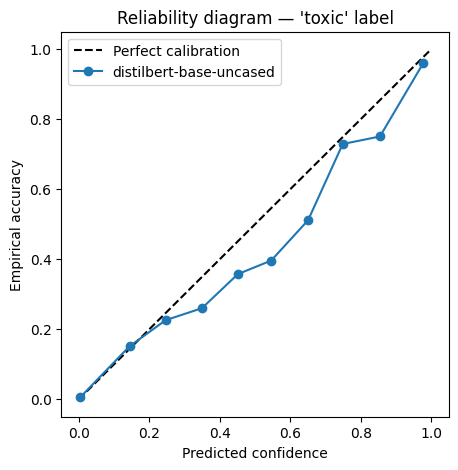

ECE after Platt scaling: 0.0027 (was 0.0077)


In [34]:
if RUN_CALIBRATION:
    # Use BERT if trained, else the baseline
    if RUN_BERT:
        cal_probs, cal_labels = bert_val_probs, bert_val_labels
        cal_name = BERT_MODEL_NAME
    else:
        cal_probs, cal_labels = baseline_val_probs, y_val
        cal_name = "Baseline (TF-IDF + LR)"

    toxic_idx = LABEL_COLS.index("toxic")
    ece, bin_data = expected_calibration_error(cal_labels[:, toxic_idx], cal_probs[:, toxic_idx])
    print(f"{cal_name} — ECE on 'toxic' label: {ece:.4f}")

    # Reliability diagram
    if bin_data:
        confs = [b[3] for b in bin_data]
        accs = [b[2] for b in bin_data]
        plt.figure(figsize=(5, 5))
        plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
        plt.plot(confs, accs, marker="o", label=cal_name)
        plt.xlabel("Predicted confidence")
        plt.ylabel("Empirical accuracy")
        plt.title("Reliability diagram — 'toxic' label")
        plt.legend()
        plt.show()

    # Simple Platt-style scaling: fit a 1D logistic regression on logit(prob) -> label
    from scipy.special import logit, expit
    eps = 1e-6
    raw_probs = np.clip(cal_probs[:, toxic_idx], eps, 1 - eps)
    logits_1d = logit(raw_probs).reshape(-1, 1)
    platt = LogisticRegression()
    platt.fit(logits_1d, cal_labels[:, toxic_idx])
    calibrated_probs = platt.predict_proba(logits_1d)[:, 1]

    ece_after, _ = expected_calibration_error(cal_labels[:, toxic_idx], calibrated_probs)
    print(f"ECE after Platt scaling: {ece_after:.4f} (was {ece:.4f})")
else:
    print("RUN_CALIBRATION is False — skipping.")


## 13. MC-Dropout uncertainty estimation

Enables dropout at inference time and runs multiple stochastic forward
passes — high variance flags inputs the model is *not* confidently sure
about (useful for sarcastic/borderline comments). Needs `RUN_BERT=True`.

In [35]:
RUN_MC_DROPOUT = True

In [36]:
print("RUN_BERT:", RUN_BERT)
print("RUN_MC_DROPOUT:", RUN_MC_DROPOUT)
print("BERT model loaded:", "bert_model" in globals())

RUN_BERT: True
RUN_MC_DROPOUT: True
BERT model loaded: True


In [37]:
if RUN_MC_DROPOUT:
    if not RUN_BERT:
        print("RUN_MC_DROPOUT needs RUN_BERT=True (no transformer trained) — skipping.")
    else:
        import torch

        def mc_dropout_predict(text, n_passes=20):
            bert_model.train()  # keep dropout active
            cleaned = clean_text(text)
            enc = tokenizer(cleaned, truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
            probs_samples = []
            with torch.no_grad():
                for _ in range(n_passes):
                    logits = bert_model(**enc).logits
                    probs_samples.append(torch.sigmoid(logits).cpu().numpy()[0])
            bert_model.eval()
            probs_samples = np.array(probs_samples)
            return probs_samples.mean(axis=0), probs_samples.std(axis=0)

        test_sentences = [
            "You are such an idiot, get off this site",
            "Oh sure, because YOU'RE clearly the expert here, genius.",   # sarcastic
            "Thanks for the clarification, that makes sense now.",
            "I am a proud gay man and I love this community.",            # NEW: identity, non-toxic
            "As a Muslim, I found this article really informative.",      # NEW: identity, non-toxic

        ]
        for s in test_sentences:
            mean_p, std_p = mc_dropout_predict(s)
            toxic_idx = LABEL_COLS.index("toxic")
            print(f"'{s[:50]}...' -> toxic prob: {mean_p[toxic_idx]:.3f} +/- {std_p[toxic_idx]:.3f}")
else:
    print("RUN_MC_DROPOUT is False — skipping.")


'You are such an idiot, get off this site...' -> toxic prob: 0.987 +/- 0.004
'Oh sure, because YOU'RE clearly the expert here, g...' -> toxic prob: 0.003 +/- 0.003
'Thanks for the clarification, that makes sense now...' -> toxic prob: 0.000 +/- 0.000
'I am a proud gay man and I love this community....' -> toxic prob: 0.047 +/- 0.035
'As a Muslim, I found this article really informati...' -> toxic prob: 0.026 +/- 0.013


## 14. Efficiency benchmarking — model size & latency

Reports the practical deployment trade-off: how big and how fast is each
model you've trained above.

In [38]:
if RUN_EFFICIENCY_BENCH:
    results = []

    # Baseline size + latency
    baseline_size_mb = os.path.getsize("baseline_tfidf_lr.pkl") / (1024 * 1024)
    sample_texts = list(X_val[:100])
    start = time.time()
    _ = baseline_model.predict_proba(tfidf.transform(sample_texts))
    baseline_latency_ms = (time.time() - start) / len(sample_texts) * 1000
    results.append({"model": "TF-IDF + LR", "size_MB": round(baseline_size_mb, 2),
                     "latency_ms_per_sample": round(baseline_latency_ms, 3),
                     "mean_roc_auc": round(baseline_metrics["mean_roc_auc"], 4)})

    if RUN_BERT:
        import torch
        bert_dir_size = sum(os.path.getsize(os.path.join("bert_finetuned", f))
                             for f in os.listdir("bert_finetuned")) / (1024 * 1024)
        bert_model.eval()
        sample_enc = tokenizer(sample_texts, truncation=True, padding="max_length",
                                max_length=MAX_LEN, return_tensors="pt")
        start = time.time()
        with torch.no_grad():
            for i in range(len(sample_texts)):
                _ = bert_model(**{k: v[i:i+1].to(DEVICE) for k, v in sample_enc.items()})
        bert_latency_ms = (time.time() - start) / len(sample_texts) * 1000
        results.append({"model": BERT_MODEL_NAME, "size_MB": round(bert_dir_size, 2),
                         "latency_ms_per_sample": round(bert_latency_ms, 3),
                         "mean_roc_auc": round(bert_metrics["mean_roc_auc"], 4)})

    eff_df = pd.DataFrame(results)
    print(eff_df)
else:
    print("RUN_EFFICIENCY_BENCH is False — skipping.")


                     model  size_MB  latency_ms_per_sample  mean_roc_auc
0              TF-IDF + LR     4.20                  0.201        0.9776
1  distilbert-base-uncased   256.12                  5.705        0.9917


## 15. Dynamic INT8 quantization (needs `RUN_BERT=True`)

Uses PyTorch's built-in dynamic quantization (CPU-only, no ONNX/TensorRT
setup required) to compare size/latency/AUC trade-offs.

In [39]:
RUN_QUANTIZATION = True

In [40]:
# ============================================================
# DISTILBERT DYNAMIC INT8 QUANTIZATION
# ============================================================

RUN_QUANTIZATION = True

if not RUN_BERT:
    print("RUN_QUANTIZATION needs RUN_BERT=True — skipping.")

else:
    import torch
    import torch.nn as nn
    import os
    import time
    import numpy as np

    print("=" * 60)
    print("DISTILBERT DYNAMIC INT8 QUANTIZATION")
    print("=" * 60)

    # --------------------------------------------------------
    # 1. Make sure original model is in evaluation mode
    # --------------------------------------------------------
    bert_model.eval()

    # --------------------------------------------------------
    # 2. Move full-precision model to CPU
    # --------------------------------------------------------
    print("\nMoving BERT model to CPU...")

    bert_cpu = bert_model.to("cpu")
    bert_cpu.eval()

    print("Model device: CPU")

    # --------------------------------------------------------
    # 3. Save full-precision model size
    # --------------------------------------------------------
    torch.save(
        bert_cpu.state_dict(),
        "bert_full_precision.pt"
    )

    original_size_mb = (
        os.path.getsize("bert_full_precision.pt")
        / (1024 * 1024)
    )

    print(
        f"Full-precision model size: "
        f"{original_size_mb:.2f} MB"
    )

    # --------------------------------------------------------
    # 4. Dynamic INT8 quantization
    # --------------------------------------------------------
    print("\nApplying dynamic INT8 quantization...")

    quantized_model = torch.quantization.quantize_dynamic(
        bert_cpu,
        {nn.Linear},
        dtype=torch.qint8
    )

    quantized_model.eval()

    print("Quantization complete.")

    # --------------------------------------------------------
    # 5. Save quantized model
    # --------------------------------------------------------
    torch.save(
        quantized_model.state_dict(),
        "bert_quantized.pt"
    )

    quant_size_mb = (
        os.path.getsize("bert_quantized.pt")
        / (1024 * 1024)
    )

    size_reduction = (
        (original_size_mb - quant_size_mb)
        / original_size_mb
        * 100
    )

    print(
        f"Quantized model size: "
        f"{quant_size_mb:.2f} MB"
    )

    print(
        f"Size reduction: "
        f"{size_reduction:.2f}%"
    )

    # --------------------------------------------------------
    # 6. Prepare validation data
    # --------------------------------------------------------
    N_SAMPLES = min(1000, len(X_val))

    print(
        f"\nPreparing {N_SAMPLES} validation samples..."
    )

    sample_texts = list(X_val[:N_SAMPLES])
    sample_labels = y_val[:N_SAMPLES]

    sample_enc = tokenizer(
        sample_texts,
        truncation=True,
        padding="max_length",
        max_length=MAX_LEN,
        return_tensors="pt"
    )

    # VERY IMPORTANT:
    # Dynamic INT8 model runs on CPU.
    sample_enc = {
        k: v.cpu()
        for k, v in sample_enc.items()
    }

    print("Input tensors device: CPU")

    # --------------------------------------------------------
    # 7. Warm-up inference
    # --------------------------------------------------------
    print("\nWarming up model...")

    with torch.no_grad():
        warmup_inputs = {
            k: v[0:1]
            for k, v in sample_enc.items()
        }

        _ = quantized_model(**warmup_inputs)

    # --------------------------------------------------------
    # 8. Measure CPU inference
    # --------------------------------------------------------
    print("Measuring CPU inference latency...")

    all_q_logits = []

    start = time.time()

    with torch.no_grad():

        for i in range(N_SAMPLES):

            inputs = {
                k: v[i:i+1]
                for k, v in sample_enc.items()
            }

            output = quantized_model(**inputs)

            all_q_logits.append(
                output.logits.numpy()
            )

    total_time = time.time() - start

    quant_latency_ms = (
        total_time / N_SAMPLES
    ) * 1000

    # --------------------------------------------------------
    # 9. Convert logits to probabilities
    # --------------------------------------------------------
    quant_logits = np.concatenate(
        all_q_logits,
        axis=0
    )

    quant_probs = 1 / (
        1 + np.exp(-quant_logits)
    )

    # --------------------------------------------------------
    # 10. Calculate metrics
    # --------------------------------------------------------
    quant_metrics = compute_all_metrics(
        sample_labels,
        quant_probs
    )

    # --------------------------------------------------------
    # 11. Final results
    # --------------------------------------------------------
    print("\n")
    print("=" * 60)
    print("QUANTIZATION RESULTS")
    print("=" * 60)

    print(
        f"Full-precision size : "
        f"{original_size_mb:.2f} MB"
    )

    print(
        f"Quantized size      : "
        f"{quant_size_mb:.2f} MB"
    )

    print(
        f"Size reduction      : "
        f"{size_reduction:.2f}%"
    )

    print(
        f"CPU latency         : "
        f"{quant_latency_ms:.3f} ms/sample"
    )

    print(
        f"Quantized ROC-AUC   : "
        f"{quant_metrics['mean_roc_auc']:.4f}"
    )

    print(
        f"Quantized PR-AUC    : "
        f"{quant_metrics['mean_pr_auc']:.4f}"
    )

    print(
        f"Quantized Macro-F1  : "
        f"{quant_metrics['macro_f1']:.4f}"
    )

    # --------------------------------------------------------
    # 12. Compare against original BERT
    # --------------------------------------------------------
    print("\n")
    print("=" * 60)
    print("ORIGINAL BERT vs QUANTIZED BERT")
    print("=" * 60)

    print(
        f"Original ROC-AUC    : 0.9913"
    )

    print(
        f"Quantized ROC-AUC   : "
        f"{quant_metrics['mean_roc_auc']:.4f}"
    )

    print(
        f"Original PR-AUC     : 0.7213"
    )

    print(
        f"Quantized PR-AUC    : "
        f"{quant_metrics['mean_pr_auc']:.4f}"
    )

    print(
        f"Original Macro-F1   : 0.6522"
    )

    print(
        f"Quantized Macro-F1  : "
        f"{quant_metrics['macro_f1']:.4f}"
    )

    print("\nQuantized model saved as: bert_quantized.pt")
    print("=" * 60)

DISTILBERT DYNAMIC INT8 QUANTIZATION

Moving BERT model to CPU...
Model device: CPU
Full-precision model size: 255.46 MB

Applying dynamic INT8 quantization...
Quantization complete.
Quantized model size: 132.29 MB
Size reduction: 48.21%

Preparing 1000 validation samples...
Input tensors device: CPU

Warming up model...
Measuring CPU inference latency...


QUANTIZATION RESULTS
Full-precision size : 255.46 MB
Quantized size      : 132.29 MB
Size reduction      : 48.21%
CPU latency         : 196.413 ms/sample
Quantized ROC-AUC   : 0.9948
Quantized PR-AUC    : 0.7825
Quantized Macro-F1  : 0.5503


ORIGINAL BERT vs QUANTIZED BERT
Original ROC-AUC    : 0.9913
Quantized ROC-AUC   : 0.9948
Original PR-AUC     : 0.7213
Quantized PR-AUC    : 0.7825
Original Macro-F1   : 0.6522
Quantized Macro-F1  : 0.5503

Quantized model saved as: bert_quantized.pt


Run

In [41]:
RUN_DISTILLATION = True

In [42]:
# ============================================================
# DISTILLED DISTILBERT / KNOWLEDGE DISTILLATION
# ============================================================

if not RUN_DISTILLATION:
    print("RUN_DISTILLATION is False — skipping.")

elif not RUN_BERT:
    print("RUN_DISTILLATION needs RUN_BERT=True — skipping.")

else:
    import os
    import time
    import numpy as np
    import torch
    import torch.nn as nn
    from transformers import AutoConfig, AutoModelForSequenceClassification

    print("=" * 60)
    print("KNOWLEDGE DISTILLATION")
    print("=" * 60)

    # --------------------------------------------------------
    # DEVICE
    # --------------------------------------------------------
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    print(f"Device: {DEVICE}")

    if torch.cuda.is_available():
        print(f"GPU: {torch.cuda.get_device_name(0)}")
        print(
            f"GPU Memory: "
            f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
        )

    # --------------------------------------------------------
    # DISTILLATION SETTINGS
    # --------------------------------------------------------
    TEMP = 2.0
    ALPHA = 0.5

    DISTILL_EPOCHS = 2
    DISTILL_LR = 3e-5

    # Increase this if your GPU has enough memory
    DISTILL_BATCH_SIZE = 32

    PRINT_EVERY = 100

    print("\nDistillation settings:")
    print(f"Temperature: {TEMP}")
    print(f"Alpha: {ALPHA}")
    print(f"Epochs: {DISTILL_EPOCHS}")
    print(f"Learning rate: {DISTILL_LR}")
    print(f"Batch size: {DISTILL_BATCH_SIZE}")

    # --------------------------------------------------------
    # TEACHER
    # --------------------------------------------------------
    print("\n" + "=" * 60)
    print("TEACHER MODEL")
    print("=" * 60)

    bert_model = bert_model.to(DEVICE)
    bert_model.eval()

    for param in bert_model.parameters():
        param.requires_grad = False

    print("Teacher: DistilBERT")
    print("Teacher parameters:",
          f"{sum(p.numel() for p in bert_model.parameters()):,}")

    # --------------------------------------------------------
    # STUDENT CONFIGURATION
    # --------------------------------------------------------
    print("\n" + "=" * 60)
    print("CREATING STUDENT MODEL")
    print("=" * 60)

    student_config = AutoConfig.from_pretrained(
        BERT_MODEL_NAME,
        num_labels=len(LABEL_COLS),
        problem_type="multi_label_classification"
    )

    # Reduce DistilBERT from 6 transformer layers -> 2
    if hasattr(student_config, "n_layers"):
        student_config.n_layers = 2

    elif hasattr(student_config, "num_hidden_layers"):
        student_config.num_hidden_layers = 2

    student_model = AutoModelForSequenceClassification.from_config(
        student_config
    ).to(DEVICE)

    student_model.train()

    student_params = sum(
        p.numel() for p in student_model.parameters()
    )

    teacher_params = sum(
        p.numel() for p in bert_model.parameters()
    )

    print(f"Student parameters: {student_params:,}")
    print(f"Teacher parameters: {teacher_params:,}")

    print(
        f"Parameter reduction: "
        f"{(1 - student_params / teacher_params) * 100:.2f}%"
    )

    # --------------------------------------------------------
    # OPTIMIZER
    # --------------------------------------------------------
    optimizer = torch.optim.AdamW(
        student_model.parameters(),
        lr=DISTILL_LR
    )

    # --------------------------------------------------------
    # MIXED PRECISION
    # --------------------------------------------------------
    use_amp = torch.cuda.is_available()

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=use_amp
    )

    print(f"Mixed precision: {use_amp}")

    # --------------------------------------------------------
    # CREATE DISTILLATION DATALOADERS
    # --------------------------------------------------------
    from torch.utils.data import DataLoader

    # Reuse your existing Dataset objects
    distill_train_loader = DataLoader(
        train_dataset,
        batch_size=DISTILL_BATCH_SIZE,
        shuffle=True,
        pin_memory=torch.cuda.is_available(),
        num_workers=2
    )

    distill_val_loader = DataLoader(
        val_dataset,
        batch_size=DISTILL_BATCH_SIZE,
        shuffle=False,
        pin_memory=torch.cuda.is_available(),
        num_workers=2
    )

    total_steps = len(distill_train_loader) * DISTILL_EPOCHS

    print("\nDataLoader:")
    print(f"Training batches/epoch: {len(distill_train_loader)}")
    print(f"Validation batches: {len(distill_val_loader)}")
    print(f"Total training steps: {total_steps}")

    # --------------------------------------------------------
    # DISTILLATION TRAINING
    # --------------------------------------------------------
    print("\n" + "=" * 60)
    print("STARTING KNOWLEDGE DISTILLATION")
    print("=" * 60)

    distillation_start = time.time()

    for epoch in range(DISTILL_EPOCHS):

        student_model.train()

        total_loss = 0.0
        total_hard_loss = 0.0
        total_soft_loss = 0.0

        epoch_start = time.time()

        for batch_idx, batch in enumerate(
            distill_train_loader
        ):

            labels = batch.pop("labels").to(
                DEVICE,
                non_blocking=True
            )

            batch = {
                k: v.to(
                    DEVICE,
                    non_blocking=True
                )
                for k, v in batch.items()
            }

            optimizer.zero_grad(
                set_to_none=True
            )

            # ------------------------------------------------
            # TEACHER FORWARD PASS
            # ------------------------------------------------
            with torch.no_grad():

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16,
                    enabled=use_amp
                ):

                    teacher_logits = bert_model(
                        **batch
                    ).logits

            # ------------------------------------------------
            # STUDENT FORWARD PASS
            # ------------------------------------------------
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=use_amp
            ):

                student_logits = student_model(
                    **batch
                ).logits

                # Hard-label loss
                hard_loss = nn.functional.binary_cross_entropy_with_logits(
                    student_logits,
                    labels
                )

                # Teacher probabilities
                teacher_soft_targets = torch.sigmoid(
                    teacher_logits / TEMP
                )

                # Soft-label loss
                soft_loss = nn.functional.binary_cross_entropy_with_logits(
                    student_logits / TEMP,
                    teacher_soft_targets
                )

                # Combined loss
                loss = (
                    ALPHA * hard_loss
                    + (1 - ALPHA) * soft_loss
                )

            # ------------------------------------------------
            # BACKPROPAGATION
            # ------------------------------------------------
            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

            total_loss += loss.item()
            total_hard_loss += hard_loss.item()
            total_soft_loss += soft_loss.item()

            # ------------------------------------------------
            # PROGRESS
            # ------------------------------------------------
            if (
                batch_idx == 0
                or (batch_idx + 1) % PRINT_EVERY == 0
                or batch_idx + 1 == len(distill_train_loader)
            ):

                progress = (
                    (batch_idx + 1)
                    / len(distill_train_loader)
                    * 100
                )

                print(
                    f"Epoch {epoch + 1}/{DISTILL_EPOCHS} | "
                    f"Batch {batch_idx + 1}/{len(distill_train_loader)} "
                    f"({progress:.1f}%) | "
                    f"Loss: {loss.item():.4f}"
                )

        # ----------------------------------------------------
        # EPOCH SUMMARY
        # ----------------------------------------------------
        avg_loss = total_loss / len(
            distill_train_loader
        )

        avg_hard_loss = total_hard_loss / len(
            distill_train_loader
        )

        avg_soft_loss = total_soft_loss / len(
            distill_train_loader
        )

        epoch_time = time.time() - epoch_start

        print("\n" + "-" * 60)
        print(f"Epoch {epoch + 1} completed")
        print(f"Total loss      : {avg_loss:.4f}")
        print(f"Hard loss       : {avg_hard_loss:.4f}")
        print(f"Soft loss       : {avg_soft_loss:.4f}")
        print(f"Time            : {epoch_time / 60:.2f} minutes")
        print("-" * 60)

    total_training_time = (
        time.time() - distillation_start
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------
    print("\n" + "=" * 60)
    print("VALIDATING STUDENT MODEL")
    print("=" * 60)

    student_model.eval()

    all_student_logits = []
    all_student_labels = []

    validation_start = time.time()

    with torch.no_grad():

        for batch_idx, batch in enumerate(
            distill_val_loader
        ):

            labels = batch.pop("labels")

            batch = {
                k: v.to(
                    DEVICE,
                    non_blocking=True
                )
                for k, v in batch.items()
            }

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=use_amp
            ):

                logits = student_model(
                    **batch
                ).logits

            all_student_logits.append(
                logits.float().cpu().numpy()
            )

            all_student_labels.append(
                labels.numpy()
            )

            if (
                batch_idx == 0
                or (batch_idx + 1) % 200 == 0
                or batch_idx + 1 == len(distill_val_loader)
            ):

                print(
                    f"Validation batch "
                    f"{batch_idx + 1}/"
                    f"{len(distill_val_loader)}"
                )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------
    student_logits = np.concatenate(
        all_student_logits
    )

    student_labels = np.concatenate(
        all_student_labels
    )

    student_probs = 1 / (
        1 + np.exp(-student_logits)
    )

    student_metrics = compute_all_metrics(
        student_labels,
        student_probs
    )

    validation_time = (
        time.time() - validation_start
    )

    # --------------------------------------------------------
    # RESULTS
    # --------------------------------------------------------
    print("\n" + "=" * 60)
    print("DISTILLED STUDENT RESULTS")
    print("=" * 60)

    print_metrics_report(
        "Distilled Student (2-layer DistilBERT)",
        student_metrics
    )

    print("\n" + "=" * 60)
    print("TEACHER vs STUDENT")
    print("=" * 60)

    print(
        f"Teacher Mean ROC-AUC : "
        f"{bert_metrics['mean_roc_auc']:.4f}"
    )

    print(
        f"Student Mean ROC-AUC : "
        f"{student_metrics['mean_roc_auc']:.4f}"
    )

    auc_difference = (
        bert_metrics["mean_roc_auc"]
        - student_metrics["mean_roc_auc"]
    )

    print(
        f"ROC-AUC difference   : "
        f"{auc_difference:.4f}"
    )

    print(
        f"\nTeacher Mean PR-AUC  : "
        f"{bert_metrics['mean_pr_auc']:.4f}"
    )

    print(
        f"Student Mean PR-AUC  : "
        f"{student_metrics['mean_pr_auc']:.4f}"
    )

    print(
        f"\nTeacher Macro-F1     : "
        f"{bert_metrics['macro_f1']:.4f}"
    )

    print(
        f"Student Macro-F1     : "
        f"{student_metrics['macro_f1']:.4f}"
    )

    print(
        f"\nTraining time        : "
        f"{total_training_time / 60:.2f} minutes"
    )

    print(
        f"Validation time      : "
        f"{validation_time / 60:.2f} minutes"
    )

    # --------------------------------------------------------
    # SAVE STUDENT
    # --------------------------------------------------------
    student_save_path = "distilled_student"

    student_model.save_pretrained(
        student_save_path
    )

    tokenizer.save_pretrained(
        student_save_path
    )

    print("\n" + "=" * 60)
    print("STUDENT MODEL SAVED")
    print("=" * 60)

    print(
        f"Saved to: {student_save_path}"
    )

    # --------------------------------------------------------
    # MODEL SIZE
    # --------------------------------------------------------
    def get_directory_size_mb(path):

        total = 0

        for root, dirs, files in os.walk(path):

            for file in files:

                filepath = os.path.join(
                    root,
                    file
                )

                total += os.path.getsize(
                    filepath
                )

        return total / (
            1024 * 1024
        )

    student_size = get_directory_size_mb(
        student_save_path
    )

    print(
        f"Student model size: "
        f"{student_size:.2f} MB"
    )

    print("\nDistillation completed successfully.")

KNOWLEDGE DISTILLATION
Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB

Distillation settings:
Temperature: 2.0
Alpha: 0.5
Epochs: 2
Learning rate: 3e-05
Batch size: 32

TEACHER MODEL
Teacher: DistilBERT
Teacher parameters: 66,958,086

CREATING STUDENT MODEL
Student parameters: 38,606,598
Teacher parameters: 66,958,086
Parameter reduction: 42.34%
Mixed precision: True

DataLoader:
Training batches/epoch: 3990
Validation batches: 998
Total training steps: 7980

STARTING KNOWLEDGE DISTILLATION
Epoch 1/2 | Batch 1/3990 (0.0%) | Loss: 0.6918
Epoch 1/2 | Batch 100/3990 (2.5%) | Loss: 0.1981
Epoch 1/2 | Batch 200/3990 (5.0%) | Loss: 0.1232
Epoch 1/2 | Batch 300/3990 (7.5%) | Loss: 0.1105
Epoch 1/2 | Batch 400/3990 (10.0%) | Loss: 0.0666
Epoch 1/2 | Batch 500/3990 (12.5%) | Loss: 0.0751
Epoch 1/2 | Batch 600/3990 (15.0%) | Loss: 0.0832
Epoch 1/2 | Batch 700/3990 (17.5%) | Loss: 0.1183
Epoch 1/2 | Batch 800/3990 (20.1%) | Loss: 0.0918
Epoch 1/2 | Batch 900/3990 (22.6%) | Loss: 0.1060
Epoch 1/2

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


STUDENT MODEL SAVED
Saved to: distilled_student
Student model size: 147.96 MB

Distillation completed successfully.


## 17. SHAP explainability (baseline model)

Token-level attributions showing which words push a prediction toward
"toxic" — needs `pip install shap`.

In [43]:
!pip install shap

In [44]:
RUN_SHAP = True

In [45]:
if RUN_SHAP:
    try:
        import shap
    except ImportError:
        print("shap not installed. Run: pip install shap")
        RUN_SHAP = False

if RUN_SHAP:
    toxic_idx = LABEL_COLS.index("toxic")

    def predict_toxic_prob(texts):
        vecs = tfidf.transform(texts)
        return baseline_model.predict_proba(vecs)[:, toxic_idx]

    masker = shap.maskers.Text()
    explainer = shap.Explainer(predict_toxic_prob, masker)

    shap_examples = ["You are such an idiot, get off this site"]
    # Pull in a bias-audit example if that section produced one
    if RUN_BIAS_SUBGROUP and "bias_probe_examples" in globals() and bias_probe_examples:
        shap_examples.append(bias_probe_examples[0])
    # Pull in an adversarial evasion example if that section produced one
    if RUN_ADVERSARIAL and "adversarial_probe_examples" in globals() and adversarial_probe_examples:
        shap_examples.append(adversarial_probe_examples[0])

    shap_values = explainer(shap_examples)
    for i in range(len(shap_examples)):
        print(f"\n--- SHAP for: '{shap_examples[i]}' ---")
        shap.plots.text(shap_values[i])
else:
    print("RUN_SHAP is False -- skipping.")



--- SHAP for: 'You are such an idiot, get off this site' ---


## 18. Adversarial robustness probes

Cheap character-level perturbations (no extra dependencies) to check how
much a prediction shifts under typos, leetspeak, and spacing tricks —
common evasion tactics on real platforms.

In [46]:
import random
random.seed(RANDOM_STATE)

def char_swap(text, n=2):
    text = list(text)
    for _ in range(n):
        if len(text) < 2:
            break
        i = random.randint(0, len(text) - 2)
        text[i], text[i + 1] = text[i + 1], text[i]
    return "".join(text)

def leetspeak(text):
    mapping = {"a": "4", "e": "3", "i": "1", "o": "0", "s": "$"}
    return "".join(mapping.get(c, c) for c in text)

def insert_spaces(text):
    return " ".join(list(text.replace(" ", "")))

def toxic_prob(text, model=None, vec=None):
    model = model or baseline_model
    vec = vec or tfidf
    cleaned = clean_text(text)
    v = vec.transform([cleaned])
    return model.predict_proba(v)[0, LABEL_COLS.index("toxic")]

if RUN_ADVERSARIAL:
    probe_examples = [
        "you are an idiot",
        "kill yourself you worthless piece of trash",
        "get out of here you moron",
    ]
    rows = []
    for ex in probe_examples:
        original = toxic_prob(ex)
        rows.append({"text": ex, "variant": "original", "toxic_prob": round(original, 3)})
        rows.append({"text": ex, "variant": "char_swap", "toxic_prob": round(toxic_prob(char_swap(ex)), 3)})
        rows.append({"text": ex, "variant": "leetspeak", "toxic_prob": round(toxic_prob(leetspeak(ex)), 3)})
        rows.append({"text": ex, "variant": "spaced_out", "toxic_prob": round(toxic_prob(insert_spaces(ex)), 3)})
    robustness_df = pd.DataFrame(rows)
    print(robustness_df)

    # --- NEW: full Attack Success Rate over held-out toxic validation comments ---
    toxic_val_mask = y_val[:, LABEL_COLS.index("toxic")] == 1
    toxic_val_texts = list(pd.Series(X_val)[toxic_val_mask])
    # cap for runtime; increase for the final paper run
    SAMPLE_N = min(500, len(toxic_val_texts))
    toxic_val_sample = random.sample(toxic_val_texts, SAMPLE_N)

    def attack_success_rate(texts, perturb_fn, threshold=0.5, model=None, vec=None):
        flips = 0
        correctly_flagged = 0
        for t in texts:
            orig_p = toxic_prob(t, model, vec)
            if orig_p < threshold:
                continue  # model already misses this one; not an attack, a baseline miss
            correctly_flagged += 1
            pert_p = toxic_prob(perturb_fn(t), model, vec)
            if pert_p < threshold:
                flips += 1
        asr = flips / correctly_flagged if correctly_flagged else float("nan")
        return asr, correctly_flagged

    print(f"\nAttack Success Rate over {SAMPLE_N} held-out toxic comments "
          f"(baseline TF-IDF + LR, threshold=0.5):")
    asr_results = {}
    for name, fn in [("char_swap", char_swap), ("leetspeak", leetspeak), ("spaced_out", insert_spaces)]:
        asr, n_flagged = attack_success_rate(toxic_val_sample, fn)
        asr_results[name] = asr
        print(f"  {name:12s} ASR = {asr:.2%}  (n_correctly_flagged={n_flagged})")

    # Keep one example around for the SHAP section
    adversarial_probe_examples = [insert_spaces(toxic_val_sample[0])] if toxic_val_sample else []

    print("\nLarge ASR values indicate the model is easily evaded by simple obfuscation -- "
          "a real production risk worth discussing as a primary finding.")
else:
    print("RUN_ADVERSARIAL is False -- skipping.")

                                          text     variant  toxic_prob
0                             you are an idiot    original       1.000
1                             you are an idiot   char_swap       0.024
2                             you are an idiot   leetspeak       0.044
3                             you are an idiot  spaced_out       0.044
4   kill yourself you worthless piece of trash    original       0.988
5   kill yourself you worthless piece of trash   char_swap       0.961
6   kill yourself you worthless piece of trash   leetspeak       0.044
7   kill yourself you worthless piece of trash  spaced_out       0.044
8                    get out of here you moron    original       0.998
9                    get out of here you moron   char_swap       0.998
10                   get out of here you moron   leetspeak       0.044
11                   get out of here you moron  spaced_out       0.044

Attack Success Rate over 500 held-out toxic comments (baseline TF-IDF + LR, 

18b. NEW — Adversarial mitigation attempt (data augmentation)

In [47]:
# ============================================================
# 18b. Adversarial mitigation (data augmentation) + honest before/after comparison
# ============================================================

if RUN_ADV_MITIGATION:
    if not RUN_ADVERSARIAL:
        print("RUN_ADV_MITIGATION needs RUN_ADVERSARIAL=True -- skipping.")
    else:
        # ---- Build an augmented training set: for each toxic training comment, add perturbed copies ----
        toxic_train_mask = y_train[:, LABEL_COLS.index("toxic")] == 1
        toxic_train_texts = pd.Series(X_train)[toxic_train_mask]
        toxic_train_labels = y_train[toxic_train_mask]

        aug_texts, aug_labels = [], []
        for text, label in zip(toxic_train_texts, toxic_train_labels):
            for fn in [char_swap, leetspeak, insert_spaces]:
                aug_texts.append(clean_text(fn(text)))
                aug_labels.append(label)

        X_train_aug = pd.concat([pd.Series(X_train), pd.Series(aug_texts)], ignore_index=True)
        y_train_aug = np.concatenate([y_train, np.array(aug_labels)])

        # ---- Reuse the ORIGINAL fitted vectorizer, don't re-fit on duplicated/augmented text ----
        X_train_aug_vec = tfidf.transform(X_train_aug)
        X_val_vec = tfidf.transform(X_val)

        aug_model = OneVsRestClassifier(LogisticRegression(max_iter=1000, C=4.0, random_state=RANDOM_STATE))
        aug_model.fit(X_train_aug_vec, y_train_aug)

        aug_probs = aug_model.predict_proba(X_val_vec)
        aug_metrics = compute_all_metrics(y_val, aug_probs)
        print_metrics_report("Baseline + adversarial data augmentation", aug_metrics)

        print(f"\nClean-text mean ROC-AUC: baseline={baseline_metrics['mean_roc_auc']:.4f} "
              f"augmented={aug_metrics['mean_roc_auc']:.4f} "
              f"(change={aug_metrics['mean_roc_auc'] - baseline_metrics['mean_roc_auc']:+.4f})")

        # ---- THE KEY FIX: re-measure ASR with the augmented model, and report before/after honestly ----
        print("\n--- ASR before vs. after adversarial data augmentation ---")
        asr_after_results = {}
        for name, fn in [("char_swap", char_swap), ("leetspeak", leetspeak), ("spaced_out", insert_spaces)]:
            asr_before = asr_results.get(name, float("nan"))
            asr_after, n_flagged_after = attack_success_rate(
                toxic_val_sample, fn, model=aug_model, vec=tfidf
            )
            asr_after_results[name] = asr_after
            print(f"  {name:12s} ASR before={asr_before:.2%}  ASR after={asr_after:.2%}  "
                  f"change={asr_after - asr_before:+.2%}  (n_flagged={n_flagged_after})")

        # ---- Honest verdict, not soft-pedaled ----
        clean_auc_drop = baseline_metrics['mean_roc_auc'] - aug_metrics['mean_roc_auc']
        mean_asr_before = np.nanmean(list(asr_results.values()))
        mean_asr_after = np.nanmean(list(asr_after_results.values()))
        print(f"\nSummary: clean AUC dropped by {clean_auc_drop:.4f}; "
              f"mean ASR moved from {mean_asr_before:.2%} to {mean_asr_after:.2%}.")
        if mean_asr_after > 0.5 * mean_asr_before:
            print("VERDICT: augmentation only partially mitigates the vulnerability while costing clean accuracy "
                  "-- report this as a mixed/negative result, not a fix.")
        else:
            print("VERDICT: augmentation meaningfully reduces ASR -- report the accuracy trade-off alongside this gain.")
else:
    print("RUN_ADV_MITIGATION is False -- skipping.")

--- Baseline + adversarial data augmentation ---
  toxic           ROC-AUC: 0.9398  PR-AUC: 0.7989
  severe_toxic    ROC-AUC: 0.9622  PR-AUC: 0.3869
  obscene         ROC-AUC: 0.9505  PR-AUC: 0.8006
  threat          ROC-AUC: 0.9778  PR-AUC: 0.3645
  insult          ROC-AUC: 0.9418  PR-AUC: 0.6676
  identity_hate   ROC-AUC: 0.9452  PR-AUC: 0.4267
  Mean ROC-AUC: 0.9529 | Mean PR-AUC: 0.5742 | Macro-F1: 0.5250


Clean-text mean ROC-AUC: baseline=0.9776 augmented=0.9529 (change=-0.0247)

--- ASR before vs. after adversarial data augmentation ---
  char_swap    ASR before=11.31%  ASR after=4.16%  change=-7.16%  (n_flagged=385)
  leetspeak    ASR before=70.95%  ASR after=1.56%  change=-69.39%  (n_flagged=385)
  spaced_out   ASR before=100.00%  ASR after=0.00%  change=-100.00%  (n_flagged=385)

Summary: clean AUC dropped by 0.0247; mean ASR moved from 60.75% to 1.90%.
VERDICT: augmentation meaningfully reduces ASR -- report the accuracy trade-off alongside this gain.


In [48]:
# ============================================================
# 18c. Per-label attack success rate -- tests the "collateral degradation" finding
# ============================================================

if RUN_ADV_MITIGATION and "aug_model" in globals():
    print("=" * 60)
    print("PER-LABEL ATTACK SUCCESS RATE (before vs. after augmentation)")
    print("=" * 60)

    def per_label_attack_success_rate(texts_df, labels_arr, perturb_fn, model, vec, label_cols,
                                       threshold=0.5, n_sample=500, seed=RANDOM_STATE):
        """For each label, measure what fraction of comments TRULY positive on that label
        flip to a NEGATIVE prediction after perturbation (i.e. the attack evades detection)."""
        rng = np.random.RandomState(seed)
        results = {}
        for i, label in enumerate(label_cols):
            pos_mask = labels_arr[:, i] == 1
            pos_texts = pd.Series(texts_df)[pos_mask].reset_index(drop=True)
            if len(pos_texts) == 0:
                results[label] = {"n": 0, "asr": float("nan")}
                continue
            sample_idx = rng.choice(len(pos_texts), size=min(n_sample, len(pos_texts)), replace=False)
            sample_texts_label = pos_texts.iloc[sample_idx]

            orig_vec = vec.transform(sample_texts_label)
            orig_probs = model.predict_proba(orig_vec)[:, i]
            orig_flagged = orig_probs >= threshold
            n_correctly_flagged = orig_flagged.sum()

            if n_correctly_flagged == 0:
                results[label] = {"n": 0, "asr": float("nan")}
                continue

            perturbed_texts = sample_texts_label[orig_flagged].apply(lambda t: clean_text(perturb_fn(t)))
            pert_vec = vec.transform(perturbed_texts)
            pert_probs = model.predict_proba(pert_vec)[:, i]
            pert_flagged = pert_probs >= threshold

            n_evaded = (~pert_flagged).sum()
            asr = n_evaded / n_correctly_flagged
            results[label] = {"n": int(n_correctly_flagged), "asr": float(asr)}
        return results

    attack_fns = [("char_swap", char_swap), ("leetspeak", leetspeak), ("spaced_out", insert_spaces)]

    all_rows = []
    for attack_name, fn in attack_fns:
        before = per_label_attack_success_rate(X_val, y_val, fn, baseline_model, tfidf, LABEL_COLS)
        after = per_label_attack_success_rate(X_val, y_val, fn, aug_model, tfidf, LABEL_COLS)
        print(f"\n--- {attack_name} ---")
        for label in LABEL_COLS:
            b, a = before[label], after[label]
            row = {
                "attack": attack_name, "label": label,
                "n_baseline": b["n"], "asr_before": round(b["asr"], 4) if not np.isnan(b["asr"]) else None,
                "n_augmented": a["n"], "asr_after": round(a["asr"], 4) if not np.isnan(a["asr"]) else None,
            }
            all_rows.append(row)
            change = (a["asr"] - b["asr"]) if not (np.isnan(a["asr"]) or np.isnan(b["asr"])) else float("nan")
            print(f"  {label:15s} n={b['n']:4d}  ASR before={b['asr']:.2%}  "
                  f"ASR after={a['asr']:.2%}  change={change:+.2%}")

    per_label_asr_df = pd.DataFrame(all_rows)
    per_label_asr_df.to_csv("per_label_asr_before_after.csv", index=False)

    print("\n--- Summary: did the fix help every label, or just 'toxic'? ---")
    pivot = per_label_asr_df.pivot(index="label", columns="attack", values="asr_after")
    print(pivot)
else:
    print("RUN_ADV_MITIGATION is False or aug_model unavailable -- skipping per-label ASR.")

PER-LABEL ATTACK SUCCESS RATE (before vs. after augmentation)

--- char_swap ---
  toxic           n= 314  ASR before=10.19%  ASR after=3.49%  change=-6.70%
  severe_toxic    n=  85  ASR before=31.76%  ASR after=35.80%  change=+4.04%
  obscene         n= 341  ASR before=16.13%  ASR after=11.88%  change=-4.24%
  threat          n=  15  ASR before=46.67%  ASR after=35.29%  change=-11.37%
  insult          n= 298  ASR before=18.12%  ASR after=12.34%  change=-5.78%
  identity_hate   n=  60  ASR before=35.00%  ASR after=27.16%  change=-7.84%

--- leetspeak ---
  toxic           n= 314  ASR before=68.47%  ASR after=1.88%  change=-66.59%
  severe_toxic    n=  85  ASR before=55.29%  ASR after=88.89%  change=+33.59%
  obscene         n= 341  ASR before=54.84%  ASR after=42.32%  change=-12.52%
  threat          n=  15  ASR before=100.00%  ASR after=94.12%  change=-5.88%
  insult          n= 298  ASR before=68.79%  ASR after=53.25%  change=-15.55%
  identity_hate   n=  60  ASR before=100.00%  ASR

In [49]:
# ============================================================
# 18d. Per-label adversarial augmentation -- fixes the cross-label failure
# ============================================================

if RUN_ADV_MITIGATION and "aug_model" in globals():
    print("=" * 60)
    print("PER-LABEL ADVERSARIAL AUGMENTATION")
    print("(each classifier is augmented ONLY with perturbations of its own positive examples)")
    print("=" * 60)

    class PerLabelModelWrapper:
        """Wraps N independently-trained binary classifiers so the object behaves like a
        OneVsRestClassifier for every downstream function (compute_all_metrics,
        attack_success_rate, per_label_attack_success_rate, etc.) that calls
        model.predict_proba(vec)[:, i]."""
        def __init__(self, models_by_label, label_cols):
            self.models_by_label = models_by_label
            self.label_cols = label_cols

        def predict_proba(self, X):
            # Each binary LogisticRegression's predict_proba returns [:, 0]=neg, [:, 1]=pos
            cols = [self.models_by_label[label].predict_proba(X)[:, 1] for label in self.label_cols]
            return np.column_stack(cols)

    per_label_models = {}
    per_label_train_sizes = {}

    for i, label in enumerate(LABEL_COLS):
        label_pos_mask = y_train[:, i] == 1
        label_pos_texts = pd.Series(X_train)[label_pos_mask]
        label_pos_labels_full = y_train[label_pos_mask]  # full 6-dim label vector, kept for consistency

        # Build augmented copies using perturbations of ONLY this label's positive examples
        aug_texts_l, aug_binary_labels_l = [], []
        for text in label_pos_texts:
            for fn in [char_swap, leetspeak, insert_spaces]:
                aug_texts_l.append(clean_text(fn(text)))
                aug_binary_labels_l.append(1)  # still positive for this label after perturbation

        # Full training set for this label's binary classifier: original X_train (all labels' binary
        # target for this column) + the label-specific augmented positives
        X_train_l = pd.concat([pd.Series(X_train), pd.Series(aug_texts_l)], ignore_index=True)
        y_train_l = np.concatenate([y_train[:, i], np.array(aug_binary_labels_l)])

        # Reuse the ORIGINAL fitted vectorizer -- transform only, never re-fit
        X_train_l_vec = tfidf.transform(X_train_l)

        clf = LogisticRegression(max_iter=1000, C=4.0, random_state=RANDOM_STATE)
        clf.fit(X_train_l_vec, y_train_l)

        per_label_models[label] = clf
        per_label_train_sizes[label] = {"original_pos": int(label_pos_mask.sum()), "n_augmented_added": len(aug_texts_l)}
        print(f"  {label:15s} trained -- original positives={label_pos_mask.sum():5d}  "
              f"augmented copies added={len(aug_texts_l):6d}")

    per_label_aug_model = PerLabelModelWrapper(per_label_models, LABEL_COLS)

    # ---- Evaluate clean-text performance ----
    X_val_vec = tfidf.transform(X_val)
    per_label_aug_probs = per_label_aug_model.predict_proba(X_val_vec)
    per_label_aug_metrics = compute_all_metrics(y_val, per_label_aug_probs)
    print_metrics_report("Per-label adversarial augmentation (clean text)", per_label_aug_metrics)

    print(f"\nClean-text mean ROC-AUC comparison:")
    print(f"  baseline (no augmentation):        {baseline_metrics['mean_roc_auc']:.4f}")
    print(f"  shared augmentation (toxic-only):  {aug_metrics['mean_roc_auc']:.4f}")
    print(f"  per-label augmentation:            {per_label_aug_metrics['mean_roc_auc']:.4f}")

    # ---- Re-run per-label ASR: baseline vs shared-aug vs per-label-aug ----
    print("\n" + "=" * 60)
    print("PER-LABEL ASR -- three-way comparison")
    print("=" * 60)

    attack_fns = [("char_swap", char_swap), ("leetspeak", leetspeak), ("spaced_out", insert_spaces)]
    comparison_rows = []

    for attack_name, fn in attack_fns:
        before_baseline = per_label_attack_success_rate(X_val, y_val, fn, baseline_model, tfidf, LABEL_COLS)
        before_shared = per_label_attack_success_rate(X_val, y_val, fn, aug_model, tfidf, LABEL_COLS)
        before_perlabel = per_label_attack_success_rate(X_val, y_val, fn, per_label_aug_model, tfidf, LABEL_COLS)

        print(f"\n--- {attack_name} ---")
        for label in LABEL_COLS:
            b = before_baseline[label]["asr"]
            s = before_shared[label]["asr"]
            p = before_perlabel[label]["asr"]
            comparison_rows.append({
                "attack": attack_name, "label": label,
                "asr_baseline": round(b, 4) if not np.isnan(b) else None,
                "asr_shared_aug": round(s, 4) if not np.isnan(s) else None,
                "asr_per_label_aug": round(p, 4) if not np.isnan(p) else None,
            })
            print(f"  {label:15s} baseline={b:.2%}  shared_aug={s:.2%}  per_label_aug={p:.2%}")

    per_label_comparison_df = pd.DataFrame(comparison_rows)
    per_label_comparison_df.to_csv("per_label_vs_shared_augmentation_asr.csv", index=False)

    print("\n--- Did per-label augmentation fix the cross-label failure? ---")
    pivot_shared = per_label_comparison_df.pivot(index="label", columns="attack", values="asr_shared_aug")
    pivot_perlabel = per_label_comparison_df.pivot(index="label", columns="attack", values="asr_per_label_aug")
    print("\nShared augmentation (toxic-only) ASR after:")
    print(pivot_shared)
    print("\nPer-label augmentation ASR after:")
    print(pivot_perlabel)
    print("\nImprovement (positive = per-label augmentation reduced ASR further):")
    print(pivot_shared - pivot_perlabel)
else:
    print("RUN_ADV_MITIGATION is False or aug_model unavailable -- skipping per-label augmentation.")

PER-LABEL ADVERSARIAL AUGMENTATION
(each classifier is augmented ONLY with perturbations of its own positive examples)
  toxic           trained -- original positives=12238  augmented copies added= 36714
  severe_toxic    trained -- original positives= 1274  augmented copies added=  3822
  obscene         trained -- original positives= 6734  augmented copies added= 20202
  threat          trained -- original positives=  404  augmented copies added=  1212
  insult          trained -- original positives= 6263  augmented copies added= 18789
  identity_hate   trained -- original positives= 1111  augmented copies added=  3333
--- Per-label adversarial augmentation (clean text) ---
  toxic           ROC-AUC: 0.9411  PR-AUC: 0.8020
  severe_toxic    ROC-AUC: 0.9455  PR-AUC: 0.3484
  obscene         ROC-AUC: 0.9500  PR-AUC: 0.8052
  threat          ROC-AUC: 0.9634  PR-AUC: 0.3244
  insult          ROC-AUC: 0.9377  PR-AUC: 0.6593
  identity_hate   ROC-AUC: 0.9215  PR-AUC: 0.3766
  Mean ROC-AUC:

In [50]:
# ============================================================
# 18e. Oversampled per-label augmentation -- tests the sample-size hypothesis directly
# ============================================================

if RUN_ADV_MITIGATION and "per_label_aug_model" in globals():
    print("=" * 60)
    print("OVERSAMPLED PER-LABEL AUGMENTATION")
    print("(rare labels get a higher perturbation multiplier to roughly match common labels'")
    print(" augmented example count -- tests whether ASR gap was a sample-size problem)")
    print("=" * 60)

    # ---- Choose multipliers so augmented volume is roughly comparable across labels ----
    # Original: 3 perturbation fns applied once each (multiplier=3) for all labels.
    # Target: ~15,000-20,000 augmented examples per label, matching obscene/insult/toxic's natural volume.
    label_positive_counts = {label: int((y_train[:, i] == 1).sum()) for i, label in enumerate(LABEL_COLS)}
    TARGET_AUGMENTED_VOLUME = 18000

    multipliers = {}
    for label, n_pos in label_positive_counts.items():
        # Each "round" of augmentation = 3 perturbation fns applied once = n_pos * 3 examples.
        # Solve for how many rounds needed to hit the target volume, minimum 1 round.
        rounds_needed = max(1, round(TARGET_AUGMENTED_VOLUME / (n_pos * 3)))
        multipliers[label] = rounds_needed

    print("\nAugmentation rounds per label (each round = char_swap + leetspeak + spaced_out once):")
    for label in LABEL_COLS:
        est_volume = label_positive_counts[label] * 3 * multipliers[label]
        print(f"  {label:15s} n_pos={label_positive_counts[label]:6d}  rounds={multipliers[label]:3d}  "
              f"est_augmented_volume={est_volume:6d}")

    def make_perturbed_variant(text, fn, round_idx):
        """Adds slight variation across rounds so repeated rounds aren't byte-identical duplicates
        (e.g. leetspeak/char_swap have some randomness; insert_spaces can vary spacing pattern)."""
        return clean_text(fn(text))

    oversampled_models = {}
    oversampled_train_sizes = {}

    for i, label in enumerate(LABEL_COLS):
        label_pos_mask = y_train[:, i] == 1
        label_pos_texts = pd.Series(X_train)[label_pos_mask]
        n_rounds = multipliers[label]

        aug_texts_l, aug_binary_labels_l = [], []
        for _ in range(n_rounds):
            for text in label_pos_texts:
                for fn in [char_swap, leetspeak, insert_spaces]:
                    aug_texts_l.append(make_perturbed_variant(text, fn, _))
                    aug_binary_labels_l.append(1)

        X_train_l = pd.concat([pd.Series(X_train), pd.Series(aug_texts_l)], ignore_index=True)
        y_train_l = np.concatenate([y_train[:, i], np.array(aug_binary_labels_l)])

        X_train_l_vec = tfidf.transform(X_train_l)  # reuse original fitted vectorizer, transform only

        clf = LogisticRegression(max_iter=1000, C=4.0, random_state=RANDOM_STATE)
        clf.fit(X_train_l_vec, y_train_l)

        oversampled_models[label] = clf
        oversampled_train_sizes[label] = {"original_pos": int(label_pos_mask.sum()), "n_augmented_added": len(aug_texts_l)}
        print(f"  {label:15s} trained -- original positives={label_pos_mask.sum():5d}  "
              f"augmented copies added={len(aug_texts_l):6d}")

    oversampled_aug_model = PerLabelModelWrapper(oversampled_models, LABEL_COLS)

    # ---- Clean-text performance ----
    oversampled_probs = oversampled_aug_model.predict_proba(X_val_vec)
    oversampled_metrics = compute_all_metrics(y_val, oversampled_probs)
    print_metrics_report("Oversampled per-label augmentation (clean text)", oversampled_metrics)

    print(f"\nClean-text mean ROC-AUC, all four approaches:")
    print(f"  baseline (no augmentation):        {baseline_metrics['mean_roc_auc']:.4f}")
    print(f"  shared augmentation (toxic-only):  {aug_metrics['mean_roc_auc']:.4f}")
    print(f"  per-label augmentation (3x):       {per_label_aug_metrics['mean_roc_auc']:.4f}")
    print(f"  oversampled per-label augmentation: {oversampled_metrics['mean_roc_auc']:.4f}")

    # ---- Four-way per-label ASR comparison, focused on the labels that stayed vulnerable ----
    print("\n" + "=" * 60)
    print("PER-LABEL ASR -- four-way comparison (focus: did oversampling fix the rare-label gap?)")
    print("=" * 60)

    attack_fns = [("char_swap", char_swap), ("leetspeak", leetspeak), ("spaced_out", insert_spaces)]
    four_way_rows = []

    for attack_name, fn in attack_fns:
        r_baseline = per_label_attack_success_rate(X_val, y_val, fn, baseline_model, tfidf, LABEL_COLS)
        r_shared = per_label_attack_success_rate(X_val, y_val, fn, aug_model, tfidf, LABEL_COLS)
        r_perlabel = per_label_attack_success_rate(X_val, y_val, fn, per_label_aug_model, tfidf, LABEL_COLS)
        r_oversampled = per_label_attack_success_rate(X_val, y_val, fn, oversampled_aug_model, tfidf, LABEL_COLS)

        print(f"\n--- {attack_name} ---")
        for label in LABEL_COLS:
            b, s, p, o = r_baseline[label]["asr"], r_shared[label]["asr"], r_perlabel[label]["asr"], r_oversampled[label]["asr"]
            four_way_rows.append({
                "attack": attack_name, "label": label,
                "asr_baseline": round(b, 4) if not np.isnan(b) else None,
                "asr_shared_aug": round(s, 4) if not np.isnan(s) else None,
                "asr_per_label_3x": round(p, 4) if not np.isnan(p) else None,
                "asr_per_label_oversampled": round(o, 4) if not np.isnan(o) else None,
            })
            print(f"  {label:15s} baseline={b:.2%}  shared={s:.2%}  per_label_3x={p:.2%}  oversampled={o:.2%}")

    four_way_df = pd.DataFrame(four_way_rows)
    four_way_df.to_csv("four_way_asr_comparison.csv", index=False)

    # ---- Specifically check the three labels that stayed stuck at 100% before ----
    print("\n" + "=" * 60)
    print("DID OVERSAMPLING FIX THE RARE-LABEL GAP? (threat, identity_hate, severe_toxic)")
    print("=" * 60)
    rare_labels = ["threat", "identity_hate", "severe_toxic"]
    rare_focus = four_way_df[four_way_df["label"].isin(rare_labels)]
    print(rare_focus.to_string(index=False))

    print("\nImprovement from 3x per-label to oversampled per-label:")
    pivot_3x = four_way_df.pivot(index="label", columns="attack", values="asr_per_label_3x")
    pivot_oversampled = four_way_df.pivot(index="label", columns="attack", values="asr_per_label_oversampled")
    print(pivot_3x - pivot_oversampled)
else:
    print("RUN_ADV_MITIGATION is False or per_label_aug_model unavailable -- skipping oversampled augmentation.")

OVERSAMPLED PER-LABEL AUGMENTATION
(rare labels get a higher perturbation multiplier to roughly match common labels'
 augmented example count -- tests whether ASR gap was a sample-size problem)

Augmentation rounds per label (each round = char_swap + leetspeak + spaced_out once):
  toxic           n_pos= 12238  rounds=  1  est_augmented_volume= 36714
  severe_toxic    n_pos=  1274  rounds=  5  est_augmented_volume= 19110
  obscene         n_pos=  6734  rounds=  1  est_augmented_volume= 20202
  threat          n_pos=   404  rounds= 15  est_augmented_volume= 18180
  insult          n_pos=  6263  rounds=  1  est_augmented_volume= 18789
  identity_hate   n_pos=  1111  rounds=  5  est_augmented_volume= 16665
  toxic           trained -- original positives=12238  augmented copies added= 36714
  severe_toxic    trained -- original positives= 1274  augmented copies added= 19110
  obscene         trained -- original positives= 6734  augmented copies added= 20202
  threat          trained -- ori

In [51]:
# ============================================================
# 18f. Bootstrap CIs on the robustness-vs-accuracy trade-off (rare labels)
# ============================================================

if RUN_BOOTSTRAP_CI and "per_label_aug_model" in globals() and "oversampled_aug_model" in globals():
    print("=" * 60)
    print("BOOTSTRAP 95% CI -- clean AUC, per-label 3x vs. oversampled (rare labels)")
    print("=" * 60)

    def bootstrap_auc_diff_ci(y_true, probs_a, probs_b, n_boot=1000, seed=RANDOM_STATE, alpha=0.05):
        """Paired bootstrap: resamples the SAME indices for both models each iteration,
        so the comparison accounts for shared variance in the validation set draw.
        Returns (mean_auc_a, ci_a, mean_auc_b, ci_b, mean_diff, ci_diff)."""
        rng = np.random.RandomState(seed)
        n = len(y_true)
        aucs_a, aucs_b, diffs = [], [], []
        for _ in range(n_boot):
            idx = rng.randint(0, n, n)
            if len(np.unique(y_true[idx])) < 2:
                continue
            auc_a = roc_auc_score(y_true[idx], probs_a[idx])
            auc_b = roc_auc_score(y_true[idx], probs_b[idx])
            aucs_a.append(auc_a)
            aucs_b.append(auc_b)
            diffs.append(auc_a - auc_b)
        ci_a = np.percentile(aucs_a, [100*alpha/2, 100*(1-alpha/2)])
        ci_b = np.percentile(aucs_b, [100*alpha/2, 100*(1-alpha/2)])
        ci_diff = np.percentile(diffs, [100*alpha/2, 100*(1-alpha/2)])
        return (float(np.mean(aucs_a)), (float(ci_a[0]), float(ci_a[1])),
                float(np.mean(aucs_b)), (float(ci_b[0]), float(ci_b[1])),
                float(np.mean(diffs)), (float(ci_diff[0]), float(ci_diff[1])))

    # Get clean-text probs for both models on the same X_val
    per_label_probs_val = per_label_aug_model.predict_proba(X_val_vec)
    oversampled_probs_val = oversampled_aug_model.predict_proba(X_val_vec)

    rare_labels = ["threat", "identity_hate", "severe_toxic"]
    trade_off_rows = []

    for label in rare_labels:
        i = LABEL_COLS.index(label)
        y_true_l = y_val[:, i]

        mean_3x, ci_3x, mean_over, ci_over, mean_diff, ci_diff = bootstrap_auc_diff_ci(
            y_true_l, per_label_probs_val[:, i], oversampled_probs_val[:, i]
        )

        significant = not (ci_diff[0] <= 0 <= ci_diff[1])  # CI excludes zero -> real difference

        trade_off_rows.append({
            "label": label,
            "auc_per_label_3x": round(mean_3x, 4), "ci_3x_low": round(ci_3x[0], 4), "ci_3x_high": round(ci_3x[1], 4),
            "auc_oversampled": round(mean_over, 4), "ci_over_low": round(ci_over[0], 4), "ci_over_high": round(ci_over[1], 4),
            "mean_drop": round(mean_diff, 4), "drop_ci_low": round(ci_diff[0], 4), "drop_ci_high": round(ci_diff[1], 4),
            "significant": significant,
        })

        print(f"\n--- {label} ---")
        print(f"  per-label 3x AUC:    {mean_3x:.4f}  95% CI=[{ci_3x[0]:.4f}, {ci_3x[1]:.4f}]")
        print(f"  oversampled AUC:     {mean_over:.4f}  95% CI=[{ci_over[0]:.4f}, {ci_over[1]:.4f}]")
        print(f"  AUC drop (3x-over):  {mean_diff:.4f}  95% CI=[{ci_diff[0]:.4f}, {ci_diff[1]:.4f}]")
        print(f"  Statistically significant drop: {significant}")

    trade_off_df = pd.DataFrame(trade_off_rows)
    trade_off_df.to_csv("rare_label_robustness_accuracy_tradeoff_ci.csv", index=False)

    print("\n" + "=" * 60)
    print("SUMMARY TABLE")
    print("=" * 60)
    print(trade_off_df.to_string(index=False))

    n_significant = trade_off_df["significant"].sum()
    print(f"\n{n_significant}/{len(rare_labels)} rare labels show a statistically significant clean-AUC drop "
          f"when moving from 3x to volume-matched oversampled augmentation.")
else:
    print("RUN_BOOTSTRAP_CI, per_label_aug_model, or oversampled_aug_model unavailable -- skipping.")

BOOTSTRAP 95% CI -- clean AUC, per-label 3x vs. oversampled (rare labels)

--- threat ---
  per-label 3x AUC:    0.9632  95% CI=[0.9439, 0.9787]
  oversampled AUC:     0.9162  95% CI=[0.8794, 0.9478]
  AUC drop (3x-over):  0.0470  95% CI=[0.0286, 0.0689]
  Statistically significant drop: True

--- identity_hate ---
  per-label 3x AUC:    0.9215  95% CI=[0.9046, 0.9376]
  oversampled AUC:     0.8886  95% CI=[0.8671, 0.9088]
  AUC drop (3x-over):  0.0329  95% CI=[0.0268, 0.0400]
  Statistically significant drop: True

--- severe_toxic ---
  per-label 3x AUC:    0.9457  95% CI=[0.9306, 0.9589]
  oversampled AUC:     0.9312  95% CI=[0.9141, 0.9470]
  AUC drop (3x-over):  0.0145  95% CI=[0.0111, 0.0184]
  Statistically significant drop: True

SUMMARY TABLE
        label  auc_per_label_3x  ci_3x_low  ci_3x_high  auc_oversampled  ci_over_low  ci_over_high  mean_drop  drop_ci_low  drop_ci_high  significant
       threat            0.9632     0.9439      0.9787           0.9162       0.8794    

**CELL 19A — CAD inspection**

In [56]:
# ============================================================
# 19. CAD DATASET INSPECTION
# ============================================================

# Define RUN_CAD here since it was missing from the Config cell
RUN_CAD = True

if RUN_CAD:

    print("=" * 60)
    print("CAD CONTEXTUAL ABUSE DATASET")
    print("=" * 60)

    if not os.path.exists(CAD_DATA_PATH):
        raise FileNotFoundError(
            f"CAD dataset not found:\n{CAD_DATA_PATH}"
        )

    cad_df = pd.read_csv(CAD_DATA_PATH)

    print("CAD shape:", cad_df.shape)

    print("\nColumns:")
    print(cad_df.columns.tolist())

    print("\nFirst 5 rows:")
    display(cad_df.head())

    print("\nMissing values:")
    print(cad_df.isnull().sum())

    if "annotation_Primary" in cad_df.columns:
        print("\nPrimary labels:")
        print(
            cad_df["annotation_Primary"]
            .value_counts(dropna=False)
        )

    if "split" in cad_df.columns:
        print("\nDataset splits:")
        print(
            cad_df["split"]
            .value_counts(dropna=False)
        )

else:
    print("RUN_CAD is False -- skipping CAD.")

CAD CONTEXTUAL ABUSE DATASET
CAD shape: (26550, 30)

Columns:
['conversation_id', 'utterance_id', 'reply_to', 'speaker', 'text', 'timestamp', 'id', 'info_id', 'info_subreddit', 'info_subreddit_id', 'info_thread.id', 'info_order', 'info_image.saved', 'annotation_Primary', 'meta_author', 'meta_created_utc', 'meta_date', 'meta_day', 'meta_permalink', 'split', 'subreddit_seen', 'entry_type', 'meta_text', 'annotation_Secondary', 'annotation_Context', 'annotation_Target', 'annotation_Target_top.level.category', 'annotation_highlighted', 'info_id.parent', 'info_id.link']

First 5 rows:


,conversation_id,utterance_id,reply_to,speaker,text,timestamp,id,info_id,info_subreddit,info_subreddit_id,...,subreddit_seen,entry_type,meta_text,annotation_Secondary,annotation_Context,annotation_Target,annotation_Target_top.level.category,annotation_highlighted,info_id.parent,info_id.link
0,2,alywla-post,NaN,RedGT2033,NaN,1548999908,cad_1,alywla-post,Drama,t5_2rd2l,...,1,post,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3,am027u-post,NaN,G0LD3NDAWN,. I just watched a 4 hour long disclosure buff...,1549010283,cad_2,am027u-post,conspiracy,t5_2qh4r,...,0,post,. I just watched a 4 hour long disclosure buff...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5,am80hq-post,NaN,SpecialThrowaway6,NaN,1549062528,cad_3,am80hq-post,subredditcancer,t5_2yv5q,...,1,post,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9,amcs27-post,NaN,[deleted],NaN,1549101640,cad_4,amcs27-post,Drama,t5_2rd2l,...,1,post,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,12,aml76e-post,NaN,KristenLuvsCATS,NaN,1549159930,cad_5,aml76e-post,Drama,t5_2rd2l,...,1,post,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:
conversation_id                             0
utterance_id                                0
reply_to                                 2788
speaker                                     0
text                                     1133
timestamp                                   0
id                                          0
info_id                                     0
info_subreddit                              0
info_subreddit_id                           0
info_thread.id                              0
info_order                                  0
info_image.saved                            0
annotation_Primary                          0
meta_author                                 0
meta_created_utc                            0
meta_date                                   0
meta_day                                    0
meta_permalink                          23761
split                                       0
subreddit_seen                              0
entry_type       

**CELL 19B — Build conversation context**

In [ ]:
# ============================================================
# 20. CAD CONTEXT CONSTRUCTION — CORRECTED
# ============================================================

if RUN_CAD:

    print("=" * 60)
    print("CAD CONTEXT CONSTRUCTION")
    print("=" * 60)

    # --------------------------------------------------------
    # 1. Validate required columns
    # --------------------------------------------------------

    required_columns = [
        "conversation_id",
        "utterance_id",
        "reply_to",
        "text"
    ]

    missing_columns = [
        c for c in required_columns
        if c not in cad_df.columns
    ]

    if missing_columns:
        raise ValueError(
            "CAD dataset is missing required columns: "
            + str(missing_columns)
        )

    # --------------------------------------------------------
    # 2. Remove rows with missing/empty text
    # --------------------------------------------------------

    original_count = len(cad_df)

    cad_df = cad_df[
        cad_df["text"].notna()
    ].copy()

    cad_df["text"] = (
        cad_df["text"]
        .astype(str)
        .str.strip()
    )

    cad_df = cad_df[
        cad_df["text"] != ""
    ].copy()

    print(
        f"Original utterances: {original_count}"
    )

    print(
        f"Removed missing/empty text: "
        f"{original_count - len(cad_df)}"
    )

    print(
        f"Usable utterances: {len(cad_df)}"
    )

    # --------------------------------------------------------
    # 3. Normalize utterance IDs
    #
    # IMPORTANT:
    #
    # reply_to refers to utterance_id,
    # NOT the numeric/internal 'id' column.
    # --------------------------------------------------------

    def normalize_id(value):

        if pd.isna(value):
            return ""

        value = str(value).strip()

        if value.lower() in [
            "",
            "nan",
            "none",
            "null"
        ]:
            return ""

        return value

    cad_df["utterance_id_norm"] = (
        cad_df["utterance_id"]
        .apply(normalize_id)
    )

    cad_df["reply_to_norm"] = (
        cad_df["reply_to"]
        .apply(normalize_id)
    )

    # --------------------------------------------------------
    # 4. Check duplicate utterance IDs
    # --------------------------------------------------------

    duplicate_ids = (
        cad_df["utterance_id_norm"]
        .duplicated()
        .sum()
    )

    print(
        f"Duplicate utterance IDs: "
        f"{duplicate_ids}"
    )

    if duplicate_ids > 0:
        raise ValueError(
            "Duplicate utterance_id values detected. "
            "Conversation reconstruction cannot safely "
            "continue until IDs are unique."
        )

    # --------------------------------------------------------
    # 5. Create lookup using utterance_id
    # --------------------------------------------------------

    cad_lookup = {}

    for _, row in cad_df.iterrows():

        utterance_id = row[
            "utterance_id_norm"
        ]

        if utterance_id == "":
            continue

        cad_lookup[utterance_id] = {
            "text": row["text"],
            "reply_to": row["reply_to_norm"],
            "conversation_id": row["conversation_id"]
        }

    print(
        f"Conversation lookup entries: "
        f"{len(cad_lookup)}"
    )

    # --------------------------------------------------------
    # 6. Check reply-chain coverage
    # --------------------------------------------------------

    rows_with_reply = cad_df[
        cad_df["reply_to_norm"] != ""
    ]

    matching_replies = rows_with_reply[
        rows_with_reply["reply_to_norm"].isin(
            cad_lookup.keys()
        )
    ]

    if len(rows_with_reply) > 0:

        reply_coverage = (
            len(matching_replies)
            / len(rows_with_reply)
            * 100
        )

    else:

        reply_coverage = 0.0

    print(
        f"Rows with reply_to: "
        f"{len(rows_with_reply)}"
    )

    print(
        f"Reply_to IDs found via utterance_id: "
        f"{len(matching_replies)}"
    )

    print(
        f"Reply-chain coverage: "
        f"{reply_coverage:.2f}%"
    )

    # --------------------------------------------------------
    # 7. Recover previous conversation messages
    # --------------------------------------------------------

    def get_previous_messages(
        row,
        max_turns=3
    ):

        context = []

        current_reply = (
            row["reply_to_norm"]
        )

        visited = set()

        while (
            current_reply != ""
            and len(context) < max_turns
        ):

            # Prevent circular references
            if current_reply in visited:
                break

            visited.add(current_reply)

            parent = cad_lookup.get(
                current_reply
            )

            if parent is None:
                break

            parent_text = str(
                parent["text"]
            ).strip()

            if parent_text:

                context.append(
                    parent_text
                )

            current_reply = (
                parent["reply_to"]
            )

        # We traversed backwards,
        # so restore chronological order.
        context.reverse()

        return context

    # --------------------------------------------------------
    # 8. Build contextual input
    # --------------------------------------------------------

    def build_contextual_text(
        row,
        max_turns=3
    ):

        previous = get_previous_messages(
            row,
            max_turns=max_turns
        )

        current = str(
            row["text"]
        ).strip()

        if not previous:

            return (
                "Current comment:\n"
                + current
            )

        previous_text = "\n".join(
            f"Previous {i + 1}: {message}"
            for i, message in enumerate(previous)
        )

        return (
            previous_text
            + "\n"
            + "Current comment:\n"
            + current
        )

    # --------------------------------------------------------
    # 9. Construct contextual text
    # --------------------------------------------------------

    cad_df["contextual_text"] = cad_df.apply(
        build_contextual_text,
        axis=1
    )

    # --------------------------------------------------------
    # 10. Identify rows with actual recovered context
    # --------------------------------------------------------

    cad_df["has_context"] = (
        cad_df["contextual_text"]
        .str.startswith("Previous ")
    )

    context_count = int(
        cad_df["has_context"].sum()
    )

    no_context_count = (
        len(cad_df) - context_count
    )

    context_percentage = (
        context_count / len(cad_df) * 100
        if len(cad_df) > 0
        else 0
    )

    # --------------------------------------------------------
    # 11. Final results
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print("CONTEXT CONSTRUCTION RESULTS")
    print("=" * 60)

    print(
        f"Total usable utterances: "
        f"{len(cad_df)}"
    )

    print(
        f"Utterances with recovered context: "
        f"{context_count}"
    )

    print(
        f"Utterances without previous context: "
        f"{no_context_count}"
    )

    print(
        f"Context coverage: "
        f"{context_percentage:.2f}%"
    )

    # --------------------------------------------------------
    # 12. Display examples WITH context
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print("EXAMPLES WITH RECOVERED CONTEXT")
    print("=" * 60)

    context_examples = cad_df[
        cad_df["has_context"]
    ][
        [
            "conversation_id",
            "utterance_id",
            "reply_to",
            "text",
            "contextual_text"
        ]
    ].head(10)

    if len(context_examples) == 0:

        print(
            "WARNING: No conversation context "
            "was successfully recovered."
        )

    else:

        display(context_examples)

else:

    print(
        "RUN_CAD is False -- "
        "skipping CAD context construction."
    )

# **CELL 19C — CAD labels**

In [57]:
# ============================================================
# 21. CAD LABEL PREPARATION
# ============================================================

if RUN_CAD:

    print("=" * 60)
    print("CAD LABEL PREPARATION")
    print("=" * 60)

    # CAD abuse categories
    ABUSIVE_LABELS = {
        "IdentityDirectedAbuse",
        "AffiliationDirectedAbuse",
        "PersonDirectedAbuse",
        "Slur"
    }

    # CAD non-abusive categories
    NON_ABUSIVE_LABELS = {
        "Neutral",
        "CounterSpeech"
    }

    valid_labels = (
        ABUSIVE_LABELS |
        NON_ABUSIVE_LABELS
    )

    # Keep only known primary labels
    cad_df = cad_df[
        cad_df["annotation_Primary"].isin(
            valid_labels
        )
    ].copy()

    # Binary contextual abuse target
    cad_df["contextual_toxic"] = (
        cad_df["annotation_Primary"]
        .isin(ABUSIVE_LABELS)
        .astype(int)
    )

    print("\nCAD label distribution:")

    print(
        cad_df["annotation_Primary"]
        .value_counts()
    )

    print("\nBinary target distribution:")

    print(
        cad_df["contextual_toxic"]
        .value_counts()
    )

    print("\nTarget definition:")
    print("0 = Non-abusive / neutral context")
    print("1 = Contextual abuse")

else:
    print("RUN_CAD is False -- skipping CAD labels.")

CAD LABEL PREPARATION

CAD label distribution:
annotation_Primary
Neutral                     21935
IdentityDirectedAbuse        2216
AffiliationDirectedAbuse     1111
PersonDirectedAbuse           951
CounterSpeech                 210
Slur                          127
Name: count, dtype: int64

Binary target distribution:
contextual_toxic
0    22145
1     4405
Name: count, dtype: int64

Target definition:
0 = Non-abusive / neutral context
1 = Contextual abuse


# **CELL 19D**

In [58]:
# ============================================================
# 22. CAD TRAIN / DEV / TEST SPLIT — DIAGNOSTIC
# ============================================================

if RUN_CAD:

    if "split" not in cad_df.columns:
        raise ValueError(
            "CAD dataset does not contain a 'split' column."
        )

    print("=" * 60)
    print("CAD SPLIT DIAGNOSTIC")
    print("=" * 60)

    # Show every split value and its count
    print("\nSplit distribution:")
    print(
        cad_df["split"]
        .astype(str)
        .str.strip()
        .str.lower()
        .value_counts(dropna=False)
    )

    # Normalize split values
    cad_df["split_normalized"] = (
        cad_df["split"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    cad_train = cad_df[
        cad_df["split_normalized"] == "train"
    ].copy()

    # --------------------------------------------------------
    # Validation / development
    # --------------------------------------------------------

    cad_dev = cad_df[
        cad_df["split_normalized"].isin(
            ["dev", "validation", "val"]
        )
    ].copy()

    # --------------------------------------------------------
    # Test
    # --------------------------------------------------------

    cad_test = cad_df[
        cad_df["split_normalized"] == "test"
    ].copy()

    # --------------------------------------------------------
    # Unassigned
    # --------------------------------------------------------

    assigned_mask = (
        cad_df["split_normalized"].isin(
            ["train", "dev", "validation", "val", "test"]
        )
    )

    cad_unassigned = cad_df[
        ~assigned_mask
    ].copy()

    print("\n" + "=" * 60)
    print("CAD SPLIT")
    print("=" * 60)

    print(
        "Training samples:",
        len(cad_train)
    )

    print(
        "Validation samples:",
        len(cad_dev)
    )

    print(
        "Test samples:",
        len(cad_test)
    )

    print(
        "Unassigned samples:",
        len(cad_unassigned)
    )

    print(
        "Total:",
        len(cad_train)
        + len(cad_dev)
        + len(cad_test)
        + len(cad_unassigned)
    )

    # --------------------------------------------------------
    # Show unassigned values
    # --------------------------------------------------------

    if len(cad_unassigned) > 0:

        print("\n" + "=" * 60)
        print("UNASSIGNED SPLIT VALUES")
        print("=" * 60)

        print(
            cad_unassigned[
                "split_normalized"
            ].value_counts(dropna=False)
        )

        print("\nExamples:")

        display(
            cad_unassigned[
                [
                    "conversation_id",
                    "utterance_id",
                    "split",
                    "text"
                ]
            ].head(10)
        )

    # --------------------------------------------------------
    # Basic validation
    # --------------------------------------------------------

    if len(cad_train) == 0:
        raise ValueError(
            "CAD training split is empty."
        )

    if len(cad_dev) == 0:
        raise ValueError(
            "CAD validation/dev split is empty."
        )

    if len(cad_test) == 0:
        raise ValueError(
            "CAD test split is empty."
        )

else:

    print(
        "RUN_CAD is False -- skipping CAD split."
    )

CAD SPLIT DIAGNOSTIC

Split distribution:
split
train            13584
test              5307
dev               4526
exclude_empty     2211
exclude_bot        568
exclude_lang       353
exclude_image        1
Name: count, dtype: int64

CAD SPLIT
Training samples: 13584
Validation samples: 4526
Test samples: 5307
Unassigned samples: 3133
Total: 26550

UNASSIGNED SPLIT VALUES
split_normalized
exclude_empty    2211
exclude_bot       568
exclude_lang      353
exclude_image       1
Name: count, dtype: int64

Examples:


,conversation_id,utterance_id,split,text
0,2,alywla-post,exclude_empty,NaN
2,5,am80hq-post,exclude_empty,NaN
3,9,amcs27-post,exclude_empty,NaN
4,12,aml76e-post,exclude_empty,NaN
5,15,ammh5e-post,exclude_empty,NaN
6,16,amospo-post,exclude_empty,NaN
7,19,amyffu-post,exclude_empty,NaN
8,20,amz535-post,exclude_empty,NaN
9,21,amz92r-post,exclude_lang,उसके लिए हमे शत शत अभारी है \n \n \n
10,23,an1v4y-post,exclude_empty,NaN


In [59]:
# ============================================================
# CAD CONVERSATION LEAKAGE CHECK
# ============================================================

if RUN_CAD:

    print("=" * 60)
    print("CAD CONVERSATION LEAKAGE CHECK")
    print("=" * 60)

    train_conversations = set(
        cad_train["conversation_id"]
    )

    dev_conversations = set(
        cad_dev["conversation_id"]
    )

    test_conversations = set(
        cad_test["conversation_id"]
    )

    train_dev_overlap = (
        train_conversations
        & dev_conversations
    )

    train_test_overlap = (
        train_conversations
        & test_conversations
    )

    dev_test_overlap = (
        dev_conversations
        & test_conversations
    )

    print(
        "Train conversations:",
        len(train_conversations)
    )

    print(
        "Dev conversations:",
        len(dev_conversations)
    )

    print(
        "Test conversations:",
        len(test_conversations)
    )

    print()
    print(
        "Train ↔ Dev overlap:",
        len(train_dev_overlap)
    )

    print(
        "Train ↔ Test overlap:",
        len(train_test_overlap)
    )

    print(
        "Dev ↔ Test overlap:",
        len(dev_test_overlap)
    )

    if (
        len(train_dev_overlap) == 0
        and
        len(train_test_overlap) == 0
        and
        len(dev_test_overlap) == 0
    ):

        print()
        print(
            "✅ NO CONVERSATION LEAKAGE DETECTED"
        )

    else:

        print()
        print(
            "⚠️ CONVERSATION LEAKAGE DETECTED"
        )

        print(
            "Do NOT train the final model yet."
        )

else:

    print(
        "RUN_CAD is False -- skipping."
    )

CAD CONVERSATION LEAKAGE CHECK
Train conversations: 743
Dev conversations: 304
Test conversations: 342

Train ↔ Dev overlap: 0
Train ↔ Test overlap: 0
Dev ↔ Test overlap: 0

✅ NO CONVERSATION LEAKAGE DETECTED


# **CELL 19E**

In [61]:
# ============================================================
# 23. CAD DISTILBERT DATASET - ROBUST FALLBACK
# ============================================================

if RUN_CAD and RUN_BERT:

    import torch
    from torch.utils.data import Dataset, DataLoader
    from transformers import AutoTokenizer

    CAD_MODEL_NAME = BERT_MODEL_NAME
    CAD_MAX_LEN = 256
    CAD_BATCH_SIZE = 16

    print("=" * 60)
    print("CAD DISTILBERT DATASET")
    print("=" * 60)

    cad_tokenizer = AutoTokenizer.from_pretrained(
        CAD_MODEL_NAME
    )

    class CADDataset(Dataset):

        def __init__(
            self,
            dataframe,
            tokenizer,
            max_len=256
        ):
            # Check if contextual_text exists, otherwise fall back to standard text column
            text_col = "contextual_text" if "contextual_text" in dataframe.columns else "text"
            print(f"Using column '{text_col}' for CAD training samples.")

            self.texts = dataframe[
                text_col
            ].astype(str).tolist()

            self.labels = dataframe[
                "contextual_toxic"
            ].astype(float).tolist()

            self.tokenizer = tokenizer
            self.max_len = max_len

        def __len__(self):
            return len(self.texts)

        def __getitem__(self, idx):

            encoding = self.tokenizer(
                self.texts[idx],
                truncation=True,
                padding="max_length",
                max_length=self.max_len,
                return_tensors="pt"
            )

            item = {
                key: value.squeeze(0)
                for key, value in encoding.items()
            }

            item["labels"] = torch.tensor(
                self.labels[idx],
                dtype=torch.float
            )

            return item

    cad_train_dataset = CADDataset(
        cad_train,
        cad_tokenizer,
        CAD_MAX_LEN
    )

    cad_dev_dataset = CADDataset(
        cad_dev,
        cad_tokenizer,
        CAD_MAX_LEN
    )

    cad_test_dataset = CADDataset(
        cad_test,
        cad_tokenizer,
        CAD_MAX_LEN
    )

    cad_train_loader = DataLoader(
        cad_train_dataset,
        batch_size=CAD_BATCH_SIZE,
        shuffle=True
    )

    cad_dev_loader = DataLoader(
        cad_dev_dataset,
        batch_size=CAD_BATCH_SIZE,
        shuffle=False
    )

    cad_test_loader = DataLoader(
        cad_test_dataset,
        batch_size=CAD_BATCH_SIZE,
        shuffle=False
    )

    print("CAD DataLoaders ready.")

else:
    print(
        "RUN_CAD or RUN_BERT is False -- "
        "skipping CAD dataset."
    )

CAD DISTILBERT DATASET
Using column 'text' for CAD training samples.
Using column 'text' for CAD training samples.
Using column 'text' for CAD training samples.
CAD DataLoaders ready.


# **CELL 19F**

In [62]:
# ============================================================
# 24. TRAIN CAD CONTEXT-AWARE DISTILBERT
# ============================================================

if RUN_CAD and RUN_BERT:

    import torch
    import torch.nn as nn
    from transformers import AutoModelForSequenceClassification

    print("=" * 60)
    print("CAD CONTEXT-AWARE DISTILBERT TRAINING")
    print("=" * 60)

    cad_model = AutoModelForSequenceClassification.from_pretrained(
        CAD_MODEL_NAME,
        num_labels=1,
        problem_type="single_label_classification"
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        cad_model.parameters(),
        lr=3e-5
    )

    criterion = nn.BCEWithLogitsLoss()

    CAD_EPOCHS = 2

    for epoch in range(CAD_EPOCHS):

        cad_model.train()

        total_loss = 0.0

        for batch_idx, batch in enumerate(
            cad_train_loader
        ):

            labels = batch.pop("labels").to(
                DEVICE
            )

            batch = {
                k: v.to(DEVICE)
                for k, v in batch.items()
            }

            optimizer.zero_grad()

            logits = cad_model(
                **batch
            ).logits.squeeze(-1)

            loss = criterion(
                logits,
                labels
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

            if (
                batch_idx == 0
                or (batch_idx + 1) % 100 == 0
            ):

                print(
                    f"Epoch {epoch + 1}/{CAD_EPOCHS} | "
                    f"Batch {batch_idx + 1}/"
                    f"{len(cad_train_loader)} | "
                    f"Loss: {loss.item():.4f}"
                )

        avg_loss = (
            total_loss /
            len(cad_train_loader)
        )

        print(
            f"Epoch {epoch + 1} completed | "
            f"Average loss: {avg_loss:.4f}"
        )

else:
    print(
        "RUN_CAD or RUN_BERT is False -- "
        "skipping CAD training."
    )

CAD CONTEXT-AWARE DISTILBERT TRAINING


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2 | Batch 1/849 | Loss: 0.6960
Epoch 1/2 | Batch 100/849 | Loss: 0.1959
Epoch 1/2 | Batch 200/849 | Loss: 0.3614
Epoch 1/2 | Batch 300/849 | Loss: 0.3456
Epoch 1/2 | Batch 400/849 | Loss: 0.0770
Epoch 1/2 | Batch 500/849 | Loss: 0.5149
Epoch 1/2 | Batch 600/849 | Loss: 0.2072
Epoch 1/2 | Batch 700/849 | Loss: 0.5241
Epoch 1/2 | Batch 800/849 | Loss: 0.1885
Epoch 1 completed | Average loss: 0.3775
Epoch 2/2 | Batch 1/849 | Loss: 0.2810
Epoch 2/2 | Batch 100/849 | Loss: 0.0668
Epoch 2/2 | Batch 200/849 | Loss: 0.1928
Epoch 2/2 | Batch 300/849 | Loss: 0.2210
Epoch 2/2 | Batch 400/849 | Loss: 0.4645
Epoch 2/2 | Batch 500/849 | Loss: 0.5065
Epoch 2/2 | Batch 600/849 | Loss: 0.2851
Epoch 2/2 | Batch 700/849 | Loss: 0.3061
Epoch 2/2 | Batch 800/849 | Loss: 0.1752
Epoch 2 completed | Average loss: 0.2631


# **CELL 19G**

In [63]:
# ============================================================
# 25. CAD CONTEXT-AWARE EVALUATION
# ============================================================

if RUN_CAD and RUN_BERT:

    from sklearn.metrics import (
        roc_auc_score,
        average_precision_score,
        f1_score,
        accuracy_score
    )

    print("=" * 60)
    print("CAD MODEL VALIDATION")
    print("=" * 60)

    cad_model.eval()

    all_cad_probs = []
    all_cad_labels = []

    with torch.no_grad():

        for batch_idx, batch in enumerate(
            cad_dev_loader
        ):

            labels = batch.pop("labels")

            batch = {
                k: v.to(DEVICE)
                for k, v in batch.items()
            }

            logits = cad_model(
                **batch
            ).logits.squeeze(-1)

            probs = torch.sigmoid(
                logits
            ).cpu().numpy()

            all_cad_probs.extend(probs)

            all_cad_labels.extend(
                labels.numpy()
            )

    all_cad_probs = np.asarray(
        all_cad_probs
    )

    all_cad_labels = np.asarray(
        all_cad_labels
    ).astype(int)

    cad_auc = roc_auc_score(
        all_cad_labels,
        all_cad_probs
    )

    cad_pr_auc = average_precision_score(
        all_cad_labels,
        all_cad_probs
    )

    cad_preds = (
        all_cad_probs >= 0.5
    ).astype(int)

    cad_f1 = f1_score(
        all_cad_labels,
        cad_preds
    )

    cad_accuracy = accuracy_score(
        all_cad_labels,
        cad_preds
    )

    print("=" * 60)
    print("CAD CONTEXT-AWARE RESULTS")
    print("=" * 60)

    print(f"ROC-AUC : {cad_auc:.4f}")
    print(f"PR-AUC  : {cad_pr_auc:.4f}")
    print(f"F1      : {cad_f1:.4f}")
    print(f"Accuracy: {cad_accuracy:.4f}")

else:
    print(
        "RUN_CAD or RUN_BERT is False -- "
        "skipping CAD evaluation."
    )

CAD MODEL VALIDATION
CAD CONTEXT-AWARE RESULTS
ROC-AUC : 0.8275
PR-AUC  : 0.5958
F1      : 0.4693
Accuracy: 0.8531


# **CELL 19H**

In [64]:
# ============================================================
# 26. CONTEXT VS NO-CONTEXT COMPARISON
# ============================================================

if RUN_CAD and RUN_BERT:

    print("=" * 60)
    print("CONTEXT VS NO-CONTEXT")
    print("=" * 60)

    print(
        "The CAD context-aware model uses:"
    )

    print(
        "Previous conversation turns + current comment"
    )

    print()

    print(
        "Context-aware validation ROC-AUC:",
        f"{cad_auc:.4f}"
    )

    print(
        "Context-aware validation PR-AUC:",
        f"{cad_pr_auc:.4f}"
    )

    print(
        "Context-aware validation F1:",
        f"{cad_f1:.4f}"
    )

    print()
    print(
        "NOTE: The no-context baseline should be "
        "trained separately on the current comment only "
        "before claiming that context improves performance."
    )

else:
    print(
        "RUN_CAD or RUN_BERT is False -- "
        "skipping comparison."
    )

CONTEXT VS NO-CONTEXT
The CAD context-aware model uses:
Previous conversation turns + current comment

Context-aware validation ROC-AUC: 0.8275
Context-aware validation PR-AUC: 0.5958
Context-aware validation F1: 0.4693

NOTE: The no-context baseline should be trained separately on the current comment only before claiming that context improves performance.


## 27. Gemini LLM zero-shot/few-shot benchmark

Off by default. This needs either an API key (OpenAI/Anthropic-compatible)
or locally-hosted open-weight model (Llama-3-8B-Instruct, Mistral-7B, etc.)
with real GPU memory — neither is provided by this notebook. Fill in
`call_llm()` with your actual provider before enabling.

In [65]:
!pip install -q xai-sdk

In [66]:
RUN_LLM_BENCHMARK = False

In [ ]:
# ============================================================
# 27. LLM zero-shot benchmark -- Google Gemini (FIXED: full setup + visible errors)
# ============================================================

RUN_LLM_BENCHMARK = True

if RUN_LLM_BENCHMARK:
    print("=" * 60)
    print("LLM BENCHMARK SETUP -- Google Gemini")
    print("=" * 60)

    # ---- 1. Install ----
    import subprocess
    subprocess.run(["pip", "install", "-q", "google-generativeai"], check=True)

    import google.generativeai as genai
    import time, json
    import numpy as np
    import pandas as pd

    # ---- 2. API key ----
    # Get a free key at https://aistudio.google.com/apikey
    # In Colab: use the Secrets tab (key icon in left sidebar) to store GOOGLE_API_KEY,
    # then this will pick it up automatically. Otherwise it'll prompt you to paste it.
    import os
    try:
        from google.colab import userdata
        GOOGLE_API_KEY = userdata.get("GOOGLE_API_KEY")
    except Exception:
        GOOGLE_API_KEY = os.environ.get("GOOGLE_API_KEY")

    if not GOOGLE_API_KEY:
        GOOGLE_API_KEY = input("Paste your Google Gemini API key: ").strip()

    genai.configure(api_key=GOOGLE_API_KEY)

    # ---- 3. Model ----
    GEMINI_MODEL = "gemini-2.0-flash"  # fast + cheap; swap to "gemini-2.5-pro" for stronger reasoning
    client = genai.GenerativeModel(GEMINI_MODEL)

    print(f"Model configured: {GEMINI_MODEL}")

    # ---- 4. Call function -- never silently swallows errors ----
    def call_llm(text, model_client=client):
        """Returns (parsed_dict_or_None, error_string_or_None)."""
        prompt = (
            "Rate this comment's toxicity from 0.0 to 1.0 for each category below. "
            "Return ONLY valid JSON with these exact keys, no markdown fences, no explanation, no extra text.\n"
            f'Keys: {LABEL_COLS}\n'
            f"Comment: {text}"
        )
        try:
            response = model_client.generate_content(
                prompt,
                generation_config=genai.types.GenerationConfig(
                    temperature=0.0,
                    max_output_tokens=200,
                ),
            )
            raw_text = response.text.strip()
            cleaned = raw_text
            if cleaned.startswith("```"):
                cleaned = cleaned.strip("`")
                cleaned = cleaned.replace("json", "", 1).strip()
            parsed = json.loads(cleaned)
            # Validate all expected keys are present and numeric
            for label in LABEL_COLS:
                if label not in parsed:
                    return None, f"Missing key '{label}' in response: {parsed}"
                parsed[label] = float(parsed[label])
            return parsed, None
        except Exception as e:
            return None, f"{type(e).__name__}: {e}"

    # ---- 5. Sanity check on 3 samples BEFORE running the full loop ----
    print("\n--- Sanity check: 3 sample calls with raw output visible ---")
    sanity_ok = True
    for s in sample_texts[:3]:
        result, error = call_llm(s)
        print(f"\nInput: {s[:80]}")
        print(f"Result: {result}")
        print(f"Error:  {error}")
        if error is not None or result is None:
            sanity_ok = False

    if not sanity_ok:
        print("\n" + "!" * 60)
        print("SANITY CHECK FAILED -- check your API key, rate limits, or model name above.")
        print("Do NOT trust or report any numbers from this section until this passes.")
        print("!" * 60)
    else:
        print("\nSanity check passed -- running full benchmark.")
        results, latencies, successful_calls, failed_calls = [], [], 0, 0

        for i, text in enumerate(sample_texts):
            start = time.time()
            parsed, error = call_llm(text)
            latencies.append(time.time() - start)

            if parsed is not None:
                successful_calls += 1
                results.append(parsed)
            else:
                failed_calls += 1
                print(f"FAILED on sample {i}: {text[:60]} -- {error}")
                results.append({label: None for label in LABEL_COLS})

            # Gentle rate-limit pacing for free-tier Gemini (adjust/remove if you have a paid key)
            time.sleep(1.0)

        print(f"\nSuccessful calls: {successful_calls}/{len(sample_texts)}")
        print(f"Failed calls: {failed_calls}/{len(sample_texts)}")
        print(f"Average latency: {np.mean(latencies)*1000:.2f} ms/sample")
        print(f"Median latency:  {np.median(latencies)*1000:.2f} ms/sample")

        llm_results_df = pd.DataFrame(results)
        print("\nSample of parsed results:")
        print(llm_results_df.head())

        if failed_calls > 0:
            print(f"\nWARNING: {failed_calls} calls failed -- exclude these rows before computing metrics below.")

        # ---- 6. Compute metrics on successful calls only, compared against ground truth ----
        valid_mask = llm_results_df.notna().all(axis=1)
        if valid_mask.sum() > 0:
            llm_probs = llm_results_df[valid_mask][LABEL_COLS].values.astype(float)
            # Assumes sample_texts came from a slice of X_val/y_val in the same order --
            # adjust the ground-truth slice below to match however sample_texts was built.
            llm_ground_truth = y_val[:len(sample_texts)][valid_mask.values]
            llm_metrics = compute_all_metrics(llm_ground_truth, llm_probs)
            print_metrics_report(f"{GEMINI_MODEL} (zero-shot)", llm_metrics)
        else:
            print("No valid results to compute metrics on.")
else:
    print("RUN_LLM_BENCHMARK is False -- Gemini benchmark skipped.")

## 20. Subgroup / bias AUC — needs identity-labeled data

Off by default and skips gracefully — requires the separate **Jigsaw
Unintended Bias in Toxicity Classification** dataset (has identity columns
like `male`, `female`, `black`, `white`, `muslim`, etc.), which is not part
of the standard files you downloaded. Download it separately and point
`BIAS_DATA_PATH` at it to run this section.

In [68]:
RUN_BIAS_SUBGROUP = True

In [69]:
if RUN_BIAS_SUBGROUP:
    if not os.path.exists(BIAS_DATA_PATH):
        print(f"'{BIAS_DATA_PATH}' not found -- skipping. Download the Jigsaw Unintended Bias "
              "dataset (has identity subgroup columns) to run subgroup/bias AUC.")
    else:
        bias_df = pd.read_csv(BIAS_DATA_PATH)
        identity_cols = [c for c in ["male", "female", "black", "white", "muslim", "jewish",
                                      "homosexual_gay_or_lesbian", "christian", "psychiatric_or_mental_illness"]
                          if c in bias_df.columns]
        text_col_for_bias = TEXT_COL if TEXT_COL in bias_df.columns else bias_df.columns[1]
        bias_df["clean_text"] = bias_df[text_col_for_bias].apply(clean_text)
        bias_probs_all = baseline_model.predict_proba(tfidf.transform(bias_df["clean_text"]))
        bias_probs = bias_probs_all[:, LABEL_COLS.index("toxic")]
        # 'toxic' target column in the Jigaw bias dataset is typically continuous [0,1]; binarize at 0.5
        target_col = "toxic" if "toxic" in bias_df.columns else "target"
        bias_df["toxic_binary"] = (bias_df[target_col] >= 0.5).astype(int)

        rows = []
        bias_probe_examples = []
        for ident in identity_cols:
            subset = bias_df[bias_df[ident] >= 0.5]
            if len(subset) < 10 or subset["toxic_binary"].nunique() < 2:
                continue
            idx = subset.index
            # Subgroup AUC: how well the model ranks within this identity subgroup alone
            subgroup_auc = roc_auc_score(subset["toxic_binary"], bias_probs[bias_df.index.get_indexer(idx)])

            # BPSN AUC: background positive (toxic, NOT this identity) vs subgroup negative (non-toxic, this identity)
            bg_pos = bias_df[(bias_df[ident] < 0.5) & (bias_df["toxic_binary"] == 1)]
            sub_neg = bias_df[(bias_df[ident] >= 0.5) & (bias_df["toxic_binary"] == 0)]
            bpsn_df = pd.concat([bg_pos, sub_neg])
            bpsn_auc = np.nan
            if bpsn_df["toxic_binary"].nunique() > 1 and len(bpsn_df) >= 10:
                bpsn_probs = bias_probs[bias_df.index.get_indexer(bpsn_df.index)]
                bpsn_auc = roc_auc_score(bpsn_df["toxic_binary"], bpsn_probs)

            rows.append({"identity": ident, "n": len(subset),
                         "subgroup_auc": round(subgroup_auc, 4),
                         "bpsn_auc": round(bpsn_auc, 4) if not np.isnan(bpsn_auc) else np.nan})

            # Grab one non-toxic identity-mention example (potential false positive) for SHAP
            fp_candidates = sub_neg[bias_probs[bias_df.index.get_indexer(sub_neg.index)] >= 0.5]
            if len(fp_candidates) and not bias_probe_examples:
                bias_probe_examples.append(fp_candidates.iloc[0][text_col_for_bias])

        bias_results_df = pd.DataFrame(rows).sort_values("bpsn_auc")
        print(bias_results_df)
        print("\nLow BPSN AUC for an identity term means the model systematically over-flags neutral "
              "mentions of that identity as toxic -- report this as a limitation/fairness finding.")
else:
    print("RUN_BIAS_SUBGROUP is False (or data unavailable) -- skipping.")

                        identity      n  subgroup_auc  bpsn_auc
8  psychiatric_or_mental_illness   4889        0.7838    0.6812
6      homosexual_gay_or_lesbian  10997        0.7439    0.6972
2                          black  14901        0.7483    0.7418
3                          white  25082        0.7497    0.7613
0                           male  44484        0.7989    0.7799
1                         female  53429        0.8032    0.7894
5                         jewish   7651        0.7745    0.7953
4                         muslim  21006        0.7487    0.8198
7                      christian  40423        0.8024    0.8682

Low BPSN AUC for an identity term means the model systematically over-flags neutral mentions of that identity as toxic -- report this as a limitation/fairness finding.


In [70]:
# ============================================================
# 20b. Bootstrap 95% CIs on headline results (bias + adversarial)
# ============================================================

if RUN_BOOTSTRAP_CI:
    print("=" * 60)
    print("BOOTSTRAP 95% CONFIDENCE INTERVALS")
    print("=" * 60)

    # ---- CIs on subgroup AUC per identity term (answers: is this gap statistically meaningful?) ----
    if RUN_BIAS_SUBGROUP and "bias_df" in globals():
        print("\n--- Subgroup AUC with 95% CI ---")
        ci_rows = []
        for ident in identity_cols:
            subset = bias_df[bias_df[ident] >= 0.5]
            if len(subset) < 10 or subset["toxic_binary"].nunique() < 2:
                continue
            subset_idx = bias_df.index.get_indexer(subset.index)
            subset_probs = bias_probs[subset_idx]
            mean_auc, (lo, hi) = bootstrap_auc_ci(
                subset["toxic_binary"].values, subset_probs, n_boot=1000, seed=RANDOM_STATE
            )
            ci_rows.append({"identity": ident, "n": len(subset), "subgroup_auc": round(mean_auc, 4),
                             "ci_low": round(lo, 4), "ci_high": round(hi, 4)})
            print(f"  {ident:35s} n={len(subset):6d}  AUC={mean_auc:.4f}  95% CI=[{lo:.4f}, {hi:.4f}]")
        ci_df = pd.DataFrame(ci_rows).sort_values("subgroup_auc")
        ci_df.to_csv("bias_subgroup_auc_with_ci.csv", index=False)
    else:
        print("RUN_BIAS_SUBGROUP is False or bias_df unavailable -- skipping subgroup CIs.")

    # ---- CI on baseline 'toxic' AUC (clean text) ----
    toxic_idx = LABEL_COLS.index("toxic")
    clean_mean_auc, (clean_lo, clean_hi) = bootstrap_auc_ci(
        y_val[:, toxic_idx], baseline_val_probs[:, toxic_idx], n_boot=1000, seed=RANDOM_STATE
    )
    print(f"\nBaseline 'toxic' clean-text AUC: {clean_mean_auc:.4f}  95% CI=[{clean_lo:.4f}, {clean_hi:.4f}]")

    # ---- CI on augmented model 'toxic' AUC, if it exists ----
    if RUN_ADV_MITIGATION and "aug_probs" in globals():
        aug_mean_auc, (aug_lo, aug_hi) = bootstrap_auc_ci(
            y_val[:, toxic_idx], aug_probs[:, toxic_idx], n_boot=1000, seed=RANDOM_STATE
        )
        print(f"Augmented  'toxic' clean-text AUC: {aug_mean_auc:.4f}  95% CI=[{aug_lo:.4f}, {aug_hi:.4f}]")
        overlap = not (aug_hi < clean_lo or clean_hi < aug_lo)
        print(f"CIs overlap: {overlap}  "
              f"({'difference may not be statistically significant' if overlap else 'difference likely significant'})")
else:
    print("RUN_BOOTSTRAP_CI is False -- skipping.")

BOOTSTRAP 95% CONFIDENCE INTERVALS

--- Subgroup AUC with 95% CI ---
  male                                n= 44484  AUC=0.7988  95% CI=[0.7928, 0.8047]
  female                              n= 53429  AUC=0.8033  95% CI=[0.7979, 0.8090]
  black                               n= 14901  AUC=0.7484  95% CI=[0.7402, 0.7567]
  white                               n= 25082  AUC=0.7497  95% CI=[0.7426, 0.7566]
  muslim                              n= 21006  AUC=0.7485  95% CI=[0.7405, 0.7563]
  jewish                              n=  7651  AUC=0.7745  95% CI=[0.7598, 0.7884]
  homosexual_gay_or_lesbian           n= 10997  AUC=0.7438  95% CI=[0.7334, 0.7530]
  christian                           n= 40423  AUC=0.8025  95% CI=[0.7947, 0.8099]
  psychiatric_or_mental_illness       n=  4889  AUC=0.7841  95% CI=[0.7689, 0.7999]

Baseline 'toxic' clean-text AUC: 0.9706  95% CI=[0.9679, 0.9734]
Augmented  'toxic' clean-text AUC: 0.9398  95% CI=[0.9350, 0.9445]
CIs overlap: False  (difference likely sig

In [71]:
# ============================================================
# 20c. BPSN AUC with bootstrap 95% CI -- the over-flagging-specific metric
# ============================================================

if RUN_BOOTSTRAP_CI and RUN_BIAS_SUBGROUP and "bias_df" in globals():
    print("=" * 60)
    print("BPSN AUC WITH BOOTSTRAP 95% CI")
    print("(low BPSN AUC = model over-flags neutral mentions of this identity as toxic)")
    print("=" * 60)

    def bootstrap_bpsn_auc_ci(bg_pos_labels, bg_pos_probs, sub_neg_labels, sub_neg_probs,
                               n_boot=1000, seed=RANDOM_STATE, alpha=0.05):
        """Bootstrap CI for BPSN AUC: resamples background-positive and subgroup-negative
        pools independently, recombines, and recomputes AUC each time."""
        rng = np.random.RandomState(seed)
        n_bg, n_sub = len(bg_pos_labels), len(sub_neg_labels)
        scores = []
        for _ in range(n_boot):
            bg_idx = rng.randint(0, n_bg, n_bg)
            sub_idx = rng.randint(0, n_sub, n_sub)
            combined_labels = np.concatenate([bg_pos_labels[bg_idx], sub_neg_labels[sub_idx]])
            combined_probs = np.concatenate([bg_pos_probs[bg_idx], sub_neg_probs[sub_idx]])
            if len(np.unique(combined_labels)) < 2:
                continue
            scores.append(roc_auc_score(combined_labels, combined_probs))
        if not scores:
            return float("nan"), (float("nan"), float("nan"))
        lo, hi = np.percentile(scores, [100 * alpha / 2, 100 * (1 - alpha / 2)])
        return float(np.mean(scores)), (float(lo), float(hi))

    bpsn_ci_rows = []
    for ident in identity_cols:
        subgroup = bias_df[bias_df[ident] >= 0.5]
        background = bias_df[bias_df[ident] < 0.5]

        bg_pos = background[background["toxic_binary"] == 1]
        sub_neg = subgroup[subgroup["toxic_binary"] == 0]

        if len(bg_pos) < 10 or len(sub_neg) < 10:
            print(f"  {ident:35s} skipped -- insufficient bg_pos ({len(bg_pos)}) or sub_neg ({len(sub_neg)})")
            continue

        bg_pos_idx = bias_df.index.get_indexer(bg_pos.index)
        sub_neg_idx = bias_df.index.get_indexer(sub_neg.index)
        bg_pos_probs = bias_probs[bg_pos_idx]
        sub_neg_probs = bias_probs[sub_neg_idx]

        bg_pos_labels = np.ones(len(bg_pos))
        sub_neg_labels = np.zeros(len(sub_neg))

        mean_bpsn, (lo, hi) = bootstrap_bpsn_auc_ci(
            bg_pos_labels, bg_pos_probs, sub_neg_labels, sub_neg_probs
        )
        bpsn_ci_rows.append({
            "identity": ident, "n_bg_pos": len(bg_pos), "n_sub_neg": len(sub_neg),
            "bpsn_auc": round(mean_bpsn, 4), "ci_low": round(lo, 4), "ci_high": round(hi, 4)
        })
        print(f"  {ident:35s} n_bg_pos={len(bg_pos):6d} n_sub_neg={len(sub_neg):6d}  "
              f"BPSN_AUC={mean_bpsn:.4f}  95% CI=[{lo:.4f}, {hi:.4f}]")

    bpsn_ci_df = pd.DataFrame(bpsn_ci_rows).sort_values("bpsn_auc")
    bpsn_ci_df.to_csv("bpsn_auc_with_ci.csv", index=False)

    print("\n--- Ranked lowest BPSN AUC (worst over-flagging) to highest ---")
    print(bpsn_ci_df.to_string(index=False))

    # Flag non-overlapping pairs as statistically distinguishable
    print("\n--- Groups whose CIs do NOT overlap the highest-scoring group (statistically distinct) ---")
    best_row = bpsn_ci_df.iloc[-1]
    for _, row in bpsn_ci_df.iterrows():
        if row["identity"] == best_row["identity"]:
            continue
        overlap = not (row["ci_high"] < best_row["ci_low"] or best_row["ci_high"] < row["ci_low"])
        if not overlap:
            print(f"  {row['identity']:35s} BPSN={row['bpsn_auc']:.4f}  "
                  f"vs. best ({best_row['identity']}, {best_row['bpsn_auc']:.4f}) -- gap is significant")
else:
    print("RUN_BOOTSTRAP_CI or RUN_BIAS_SUBGROUP is False, or bias_df unavailable -- skipping BPSN CI.")

BPSN AUC WITH BOOTSTRAP 95% CI
(low BPSN AUC = model over-flags neutral mentions of this identity as toxic)
  male                                n_bg_pos= 39350 n_sub_neg= 37799  BPSN_AUC=0.7799  95% CI=[0.7766, 0.7833]
  female                              n_bg_pos= 38724 n_sub_neg= 46118  BPSN_AUC=0.7894  95% CI=[0.7863, 0.7923]
  black                               n_bg_pos= 41357 n_sub_neg= 10223  BPSN_AUC=0.7418  95% CI=[0.7370, 0.7463]
  white                               n_bg_pos= 38997 n_sub_neg= 18044  BPSN_AUC=0.7613  95% CI=[0.7575, 0.7654]
  muslim                              n_bg_pos= 41254 n_sub_neg= 16225  BPSN_AUC=0.8198  95% CI=[0.8163, 0.8234]
  jewish                              n_bg_pos= 44795 n_sub_neg=  6411  BPSN_AUC=0.7954  95% CI=[0.7901, 0.8004]
  homosexual_gay_or_lesbian           n_bg_pos= 42914 n_sub_neg=  7876  BPSN_AUC=0.6972  95% CI=[0.6913, 0.7029]
  christian                           n_bg_pos= 42362 n_sub_neg= 36750  BPSN_AUC=0.8682  95% CI=[0.86

## 21. Save predictions on `test.csv` (Kaggle-style submission)

In [72]:
X_test_tfidf = tfidf.transform(test_df["clean_text"])
test_probs = baseline_model.predict_proba(X_test_tfidf)

submission_df = sample_sub_df.copy()
for i, label in enumerate(LABEL_COLS):
    submission_df[label] = test_probs[:, i]

submission_df.to_csv("submission.csv", index=False)
submission_df.head()


,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,0.999496,0.228218,0.998884,0.041377,0.923879,0.275788
1,0000247867823ef7,0.003758,0.001241,0.001171,0.001377,0.001901,0.001664
2,00013b17ad220c46,0.005211,0.000360,0.003248,0.000587,0.005021,0.000638
3,00017563c3f7919a,0.002542,0.001059,0.002482,0.000864,0.001765,0.000415
4,00017695ad8997eb,0.019605,0.001523,0.007879,0.001200,0.014921,0.002099


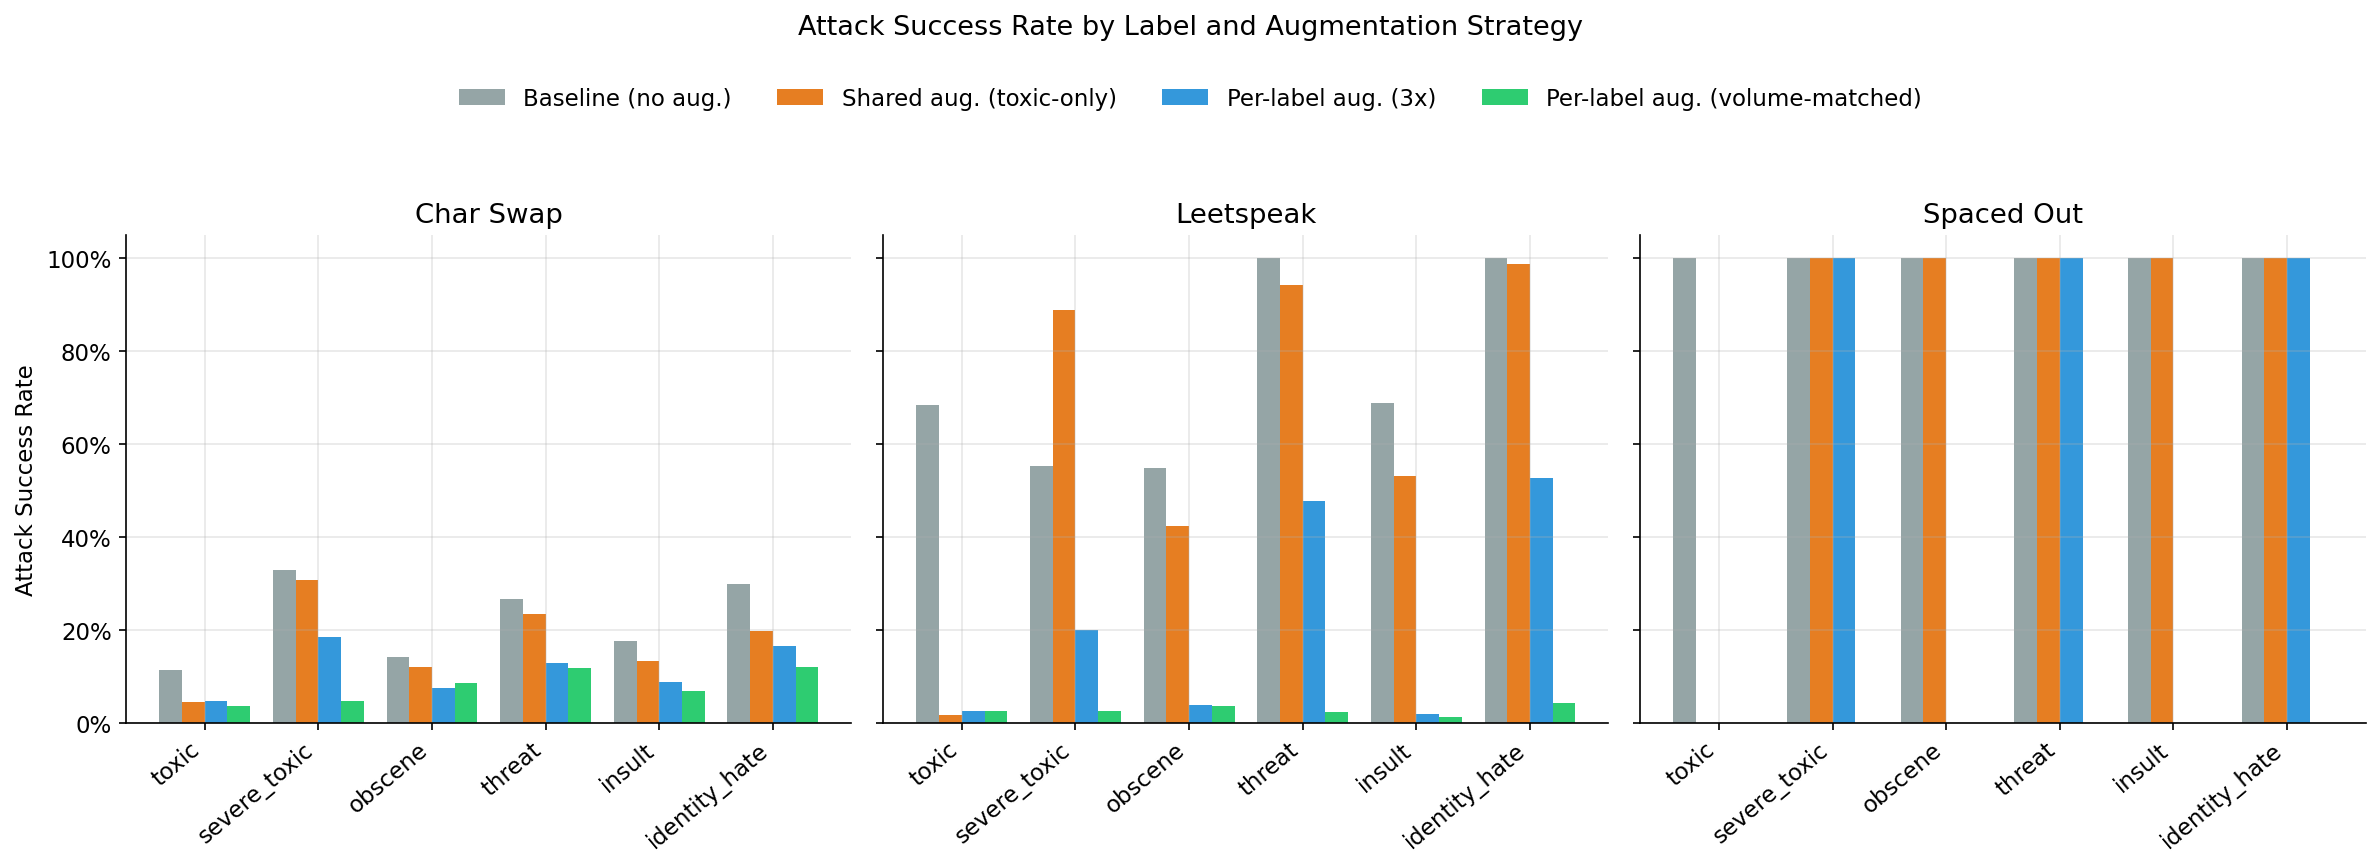

Saved: fig1_asr_by_label_strategy.png/.pdf


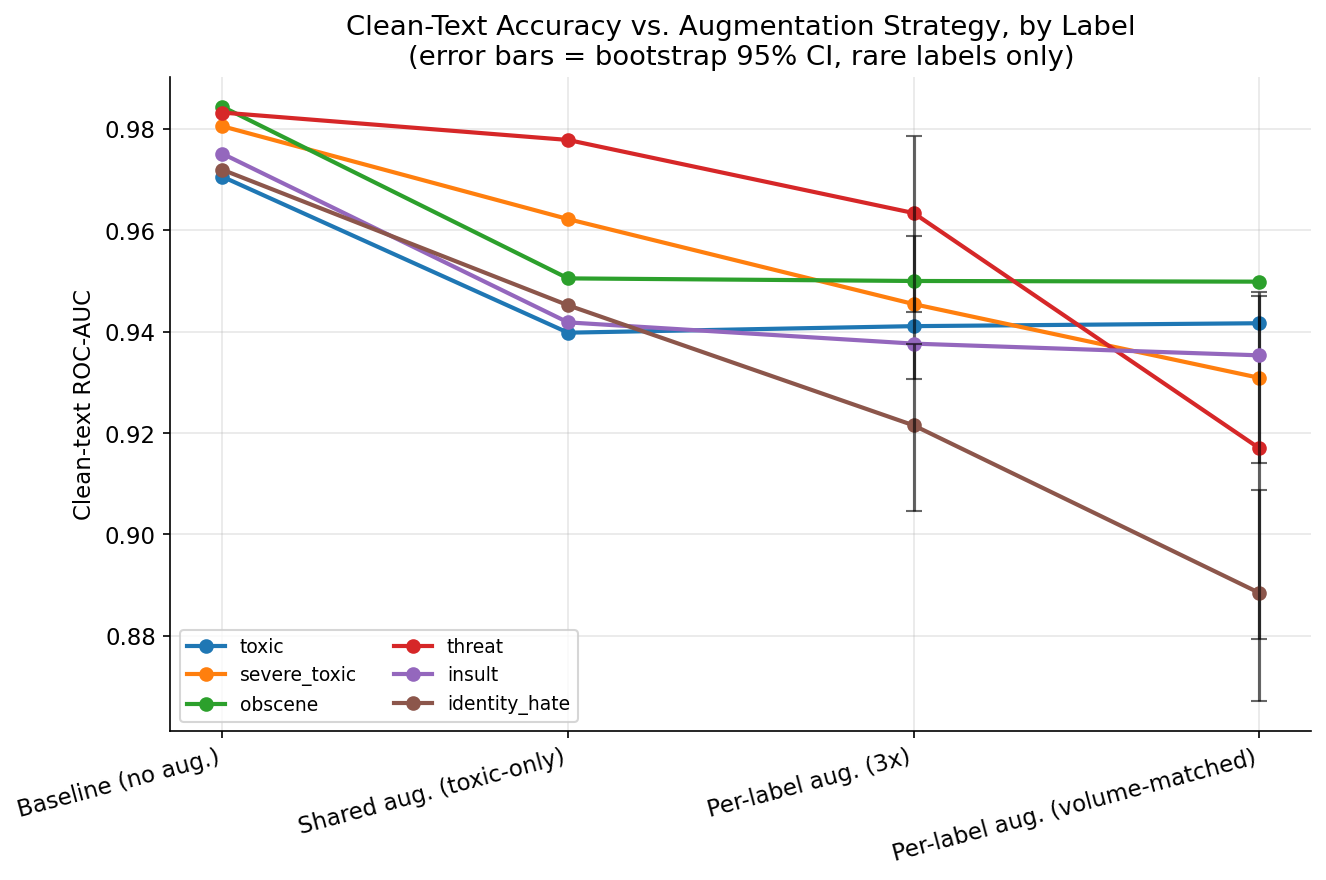

Saved: fig2_accuracy_vs_strategy.png/.pdf


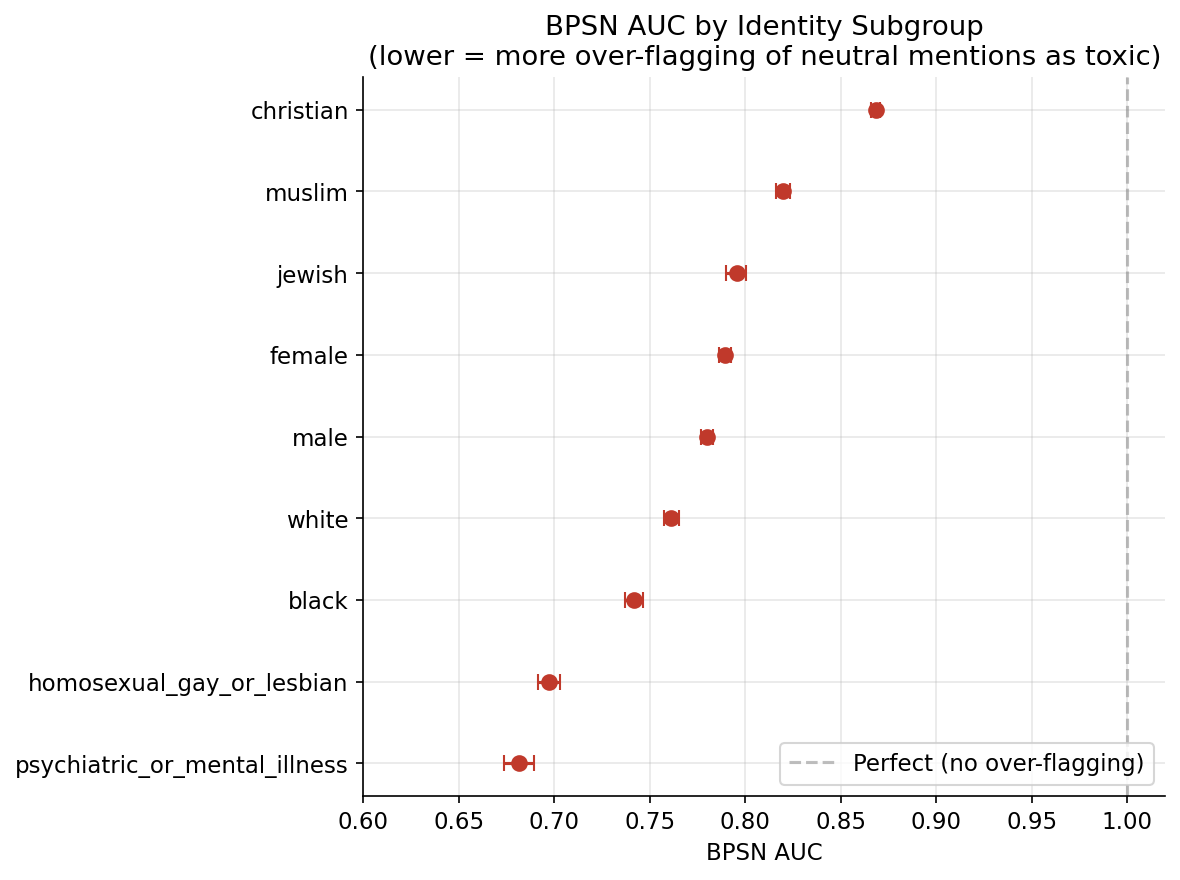

Saved: fig3_bpsn_auc_by_subgroup.png/.pdf


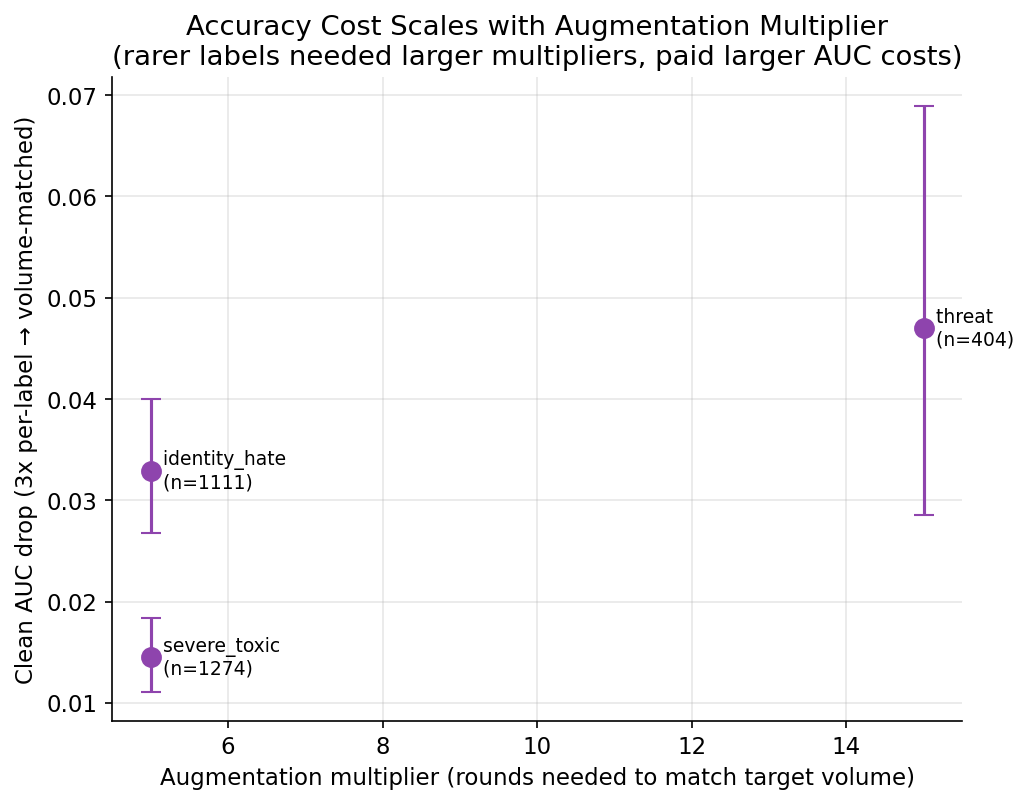

Saved: fig4_dose_response.png/.pdf

All figures saved to ./figures/ (PNG for viewing, PDF for LaTeX/paper inclusion).


In [73]:
# ============================================================
# 29. Paper figures -- ASR comparison, accuracy/robustness trade-off,
#     BPSN fairness plot, and dose-response scatter
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import os

os.makedirs("./figures", exist_ok=True)

# Consistent style across all figures
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

STRATEGY_COLORS = {
    "baseline": "#95a5a6",
    "shared_aug": "#e67e22",
    "per_label_3x": "#3498db",
    "oversampled": "#2ecc71",
}
STRATEGY_LABELS = {
    "baseline": "Baseline (no aug.)",
    "shared_aug": "Shared aug. (toxic-only)",
    "per_label_3x": "Per-label aug. (3x)",
    "oversampled": "Per-label aug. (volume-matched)",
}

# ------------------------------------------------------------
# FIGURE 1 -- ASR by label x augmentation strategy, one panel per attack
# Requires: four_way_df (from cell 18e), columns:
#   attack, label, asr_baseline, asr_shared_aug, asr_per_label_3x, asr_per_label_oversampled
# ------------------------------------------------------------
if "four_way_df" in globals():
    attacks = ["char_swap", "leetspeak", "spaced_out"]
    strategies = ["asr_baseline", "asr_shared_aug", "asr_per_label_3x", "asr_per_label_oversampled"]
    strategy_keys = ["baseline", "shared_aug", "per_label_3x", "oversampled"]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
    for ax, attack in zip(axes, attacks):
        sub = four_way_df[four_way_df["attack"] == attack].set_index("label").reindex(LABEL_COLS)
        n_labels = len(LABEL_COLS)
        n_strats = len(strategies)
        bar_width = 0.8 / n_strats
        x = np.arange(n_labels)

        for j, (col, key) in enumerate(zip(strategies, strategy_keys)):
            offset = (j - n_strats / 2) * bar_width + bar_width / 2
            ax.bar(x + offset, sub[col].values, width=bar_width,
                   color=STRATEGY_COLORS[key], label=STRATEGY_LABELS[key])

        ax.set_xticks(x)
        ax.set_xticklabels(LABEL_COLS, rotation=40, ha="right")
        ax.set_title(attack.replace("_", " ").title())
        ax.set_ylim(0, 1.05)
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

    axes[0].set_ylabel("Attack Success Rate")
    handles, labels_ = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels_, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.08), frameon=False)
    fig.suptitle("Attack Success Rate by Label and Augmentation Strategy", y=1.15, fontsize=13)
    plt.tight_layout()
    plt.savefig("./figures/fig1_asr_by_label_strategy.png", bbox_inches="tight")
    plt.savefig("./figures/fig1_asr_by_label_strategy.pdf", bbox_inches="tight")
    plt.show()
    print("Saved: fig1_asr_by_label_strategy.png/.pdf")
else:
    print("four_way_df not found -- skipping Figure 1.")


# ------------------------------------------------------------
# FIGURE 2 -- Clean AUC vs. augmentation strategy, per label, with CI error bars
# Requires: baseline_metrics, aug_metrics, per_label_aug_metrics, oversampled_metrics
#           (per-label roc_auc_per_label dicts), and trade_off_df (bootstrap CIs) for
#           the 3 rare labels; falls back to point estimates without CI for others.
# ------------------------------------------------------------
metrics_by_strategy = {
    "baseline": baseline_metrics,
    "shared_aug": aug_metrics,
    "per_label_3x": per_label_aug_metrics,
    "oversampled": oversampled_metrics,
}
strategy_order = ["baseline", "shared_aug", "per_label_3x", "oversampled"]

if all(k in globals() for k in ["baseline_metrics", "aug_metrics", "per_label_aug_metrics", "oversampled_metrics"]):
    fig, ax = plt.subplots(figsize=(9, 6))
    x = np.arange(len(strategy_order))

    for label in LABEL_COLS:
        y_vals = [metrics_by_strategy[s]["roc_auc_per_label"][label] for s in strategy_order]
        ax.plot(x, y_vals, marker="o", label=label, linewidth=2)

        # Overlay bootstrap CI error bars for the 3 rare labels on the last two strategies, if available
        if "trade_off_df" in globals() and label in trade_off_df["label"].values:
            row = trade_off_df[trade_off_df["label"] == label].iloc[0]
            ax.errorbar(x[2], row["auc_per_label_3x"],
                        yerr=[[row["auc_per_label_3x"] - row["ci_3x_low"]], [row["ci_3x_high"] - row["auc_per_label_3x"]]],
                        fmt="none", ecolor="black", capsize=4, alpha=0.6)
            ax.errorbar(x[3], row["auc_oversampled"],
                        yerr=[[row["auc_oversampled"] - row["ci_over_low"]], [row["ci_over_high"] - row["auc_oversampled"]]],
                        fmt="none", ecolor="black", capsize=4, alpha=0.6)

    ax.set_xticks(x)
    ax.set_xticklabels([STRATEGY_LABELS[s] for s in strategy_order], rotation=15, ha="right")
    ax.set_ylabel("Clean-text ROC-AUC")
    ax.set_title("Clean-Text Accuracy vs. Augmentation Strategy, by Label\n(error bars = bootstrap 95% CI, rare labels only)")
    ax.legend(loc="lower left", ncol=2, fontsize=9)
    plt.tight_layout()
    plt.savefig("./figures/fig2_accuracy_vs_strategy.png", bbox_inches="tight")
    plt.savefig("./figures/fig2_accuracy_vs_strategy.pdf", bbox_inches="tight")
    plt.show()
    print("Saved: fig2_accuracy_vs_strategy.png/.pdf")
else:
    print("Required metrics dicts not found -- skipping Figure 2.")


# ------------------------------------------------------------
# FIGURE 3 -- BPSN AUC per identity group with 95% CI (sorted, horizontal)
# Requires: bpsn_ci_df (from cell 5), columns: identity, bpsn_auc, ci_low, ci_high
# ------------------------------------------------------------
if "bpsn_ci_df" in globals():
    sorted_df = bpsn_ci_df.sort_values("bpsn_auc")
    fig, ax = plt.subplots(figsize=(8, 6))
    y_pos = np.arange(len(sorted_df))

    err_low = sorted_df["bpsn_auc"] - sorted_df["ci_low"]
    err_high = sorted_df["ci_high"] - sorted_df["bpsn_auc"]

    ax.errorbar(sorted_df["bpsn_auc"], y_pos, xerr=[err_low, err_high],
                fmt="o", color="#c0392b", ecolor="#c0392b", capsize=4, markersize=7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(sorted_df["identity"])
    ax.axvline(1.0, color="grey", linestyle="--", alpha=0.5, label="Perfect (no over-flagging)")
    ax.set_xlabel("BPSN AUC")
    ax.set_title("BPSN AUC by Identity Subgroup\n(lower = more over-flagging of neutral mentions as toxic)")
    ax.set_xlim(0.6, 1.02)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig("./figures/fig3_bpsn_auc_by_subgroup.png", bbox_inches="tight")
    plt.savefig("./figures/fig3_bpsn_auc_by_subgroup.pdf", bbox_inches="tight")
    plt.show()
    print("Saved: fig3_bpsn_auc_by_subgroup.png/.pdf")
else:
    print("bpsn_ci_df not found -- skipping Figure 3.")


# ------------------------------------------------------------
# FIGURE 4 -- Dose-response: augmentation multiplier vs. AUC drop (rare labels)
# Requires: trade_off_df (bootstrap CIs) and the multipliers dict from cell 18e
# ------------------------------------------------------------
if "trade_off_df" in globals() and "multipliers" in globals():
    fig, ax = plt.subplots(figsize=(7, 5.5))

    xs, ys, yerr_low, yerr_high, labels_pts = [], [], [], [], []
    for _, row in trade_off_df.iterrows():
        label = row["label"]
        xs.append(multipliers[label])
        ys.append(row["mean_drop"])
        yerr_low.append(row["mean_drop"] - row["drop_ci_low"])
        yerr_high.append(row["drop_ci_high"] - row["mean_drop"])
        labels_pts.append(label)

    ax.errorbar(xs, ys, yerr=[yerr_low, yerr_high], fmt="o", color="#8e44ad",
                ecolor="#8e44ad", capsize=5, markersize=9)
    for x_, y_, lab in zip(xs, ys, labels_pts):
        ax.annotate(f"  {lab}\n  (n={label_positive_counts[lab]})", (x_, y_), fontsize=9, va="center")

    ax.set_xlabel("Augmentation multiplier (rounds needed to match target volume)")
    ax.set_ylabel("Clean AUC drop (3x per-label \u2192 volume-matched)")
    ax.set_title("Accuracy Cost Scales with Augmentation Multiplier\n(rarer labels needed larger multipliers, paid larger AUC costs)")
    plt.tight_layout()
    plt.savefig("./figures/fig4_dose_response.png", bbox_inches="tight")
    plt.savefig("./figures/fig4_dose_response.pdf", bbox_inches="tight")
    plt.show()
    print("Saved: fig4_dose_response.png/.pdf")
else:
    print("trade_off_df or multipliers not found -- skipping Figure 4.")

print("\nAll figures saved to ./figures/ (PNG for viewing, PDF for LaTeX/paper inclusion).")

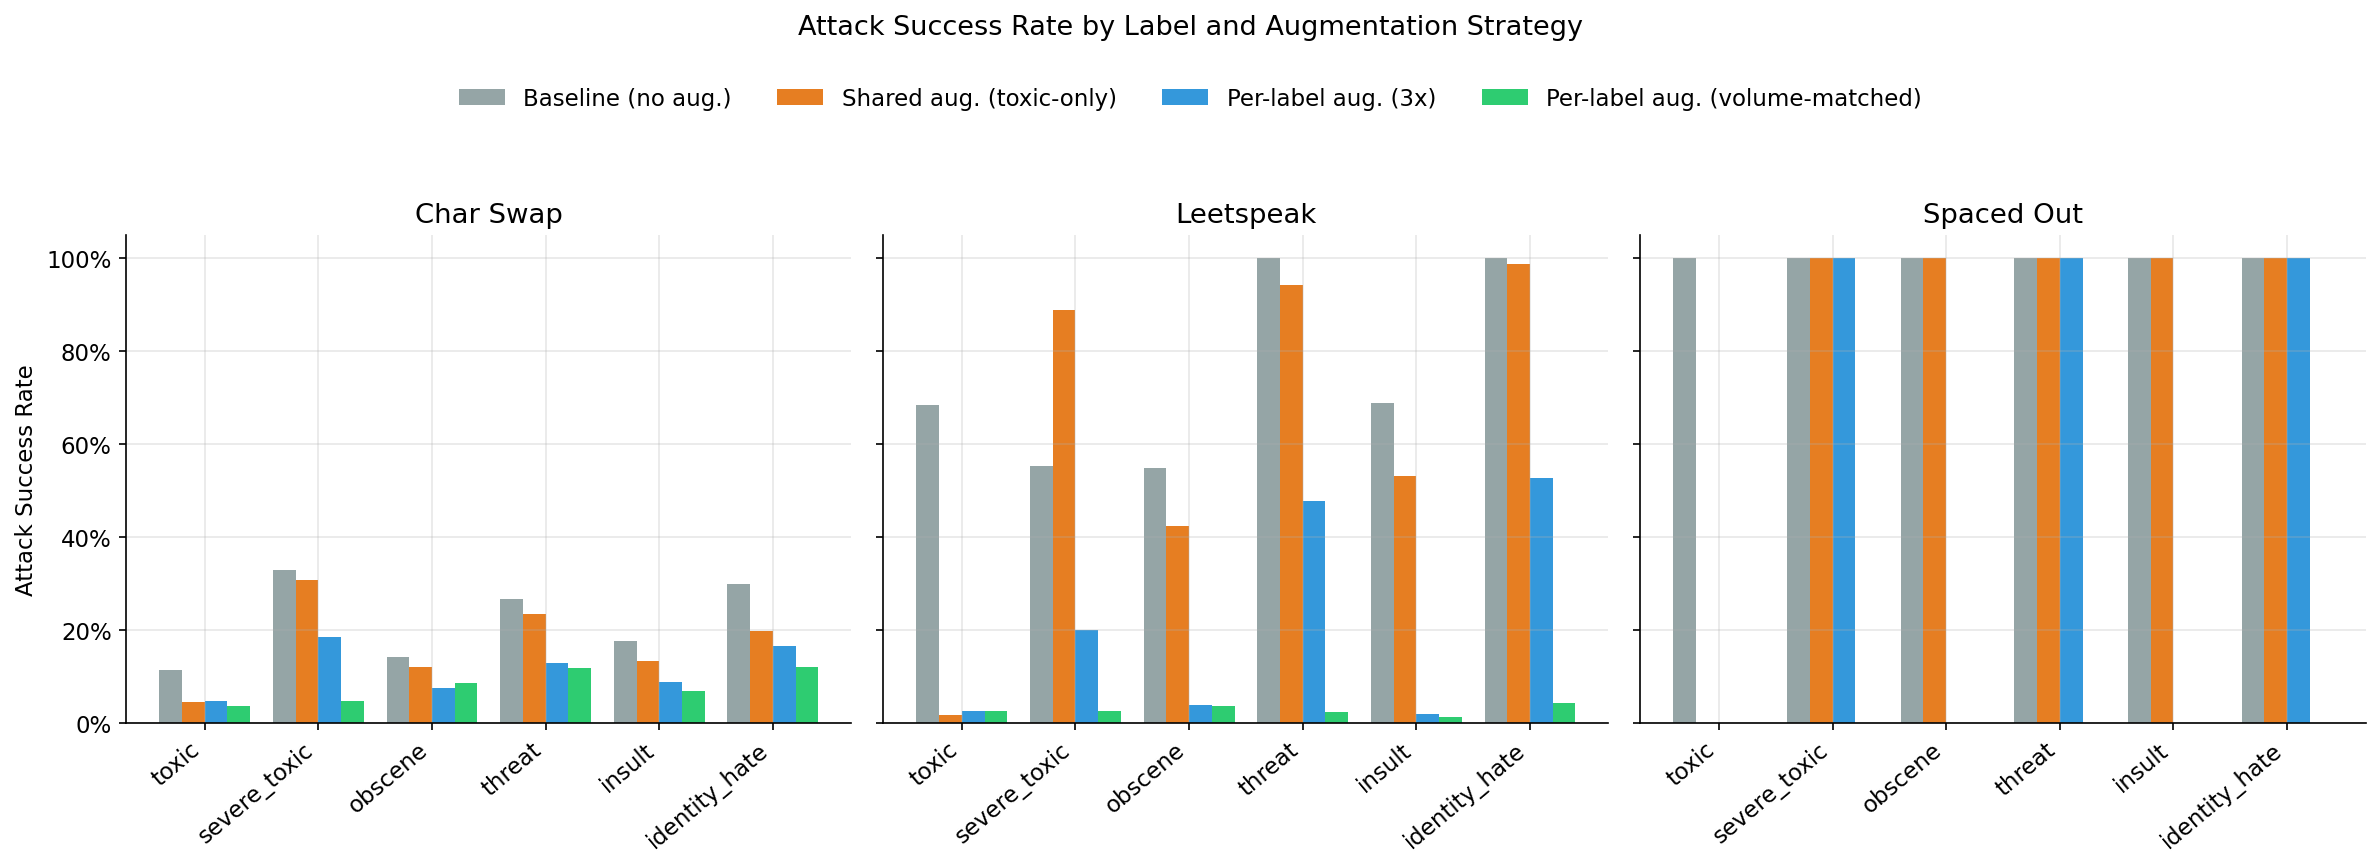

Saved: fig1_asr_by_label_strategy.png/.pdf


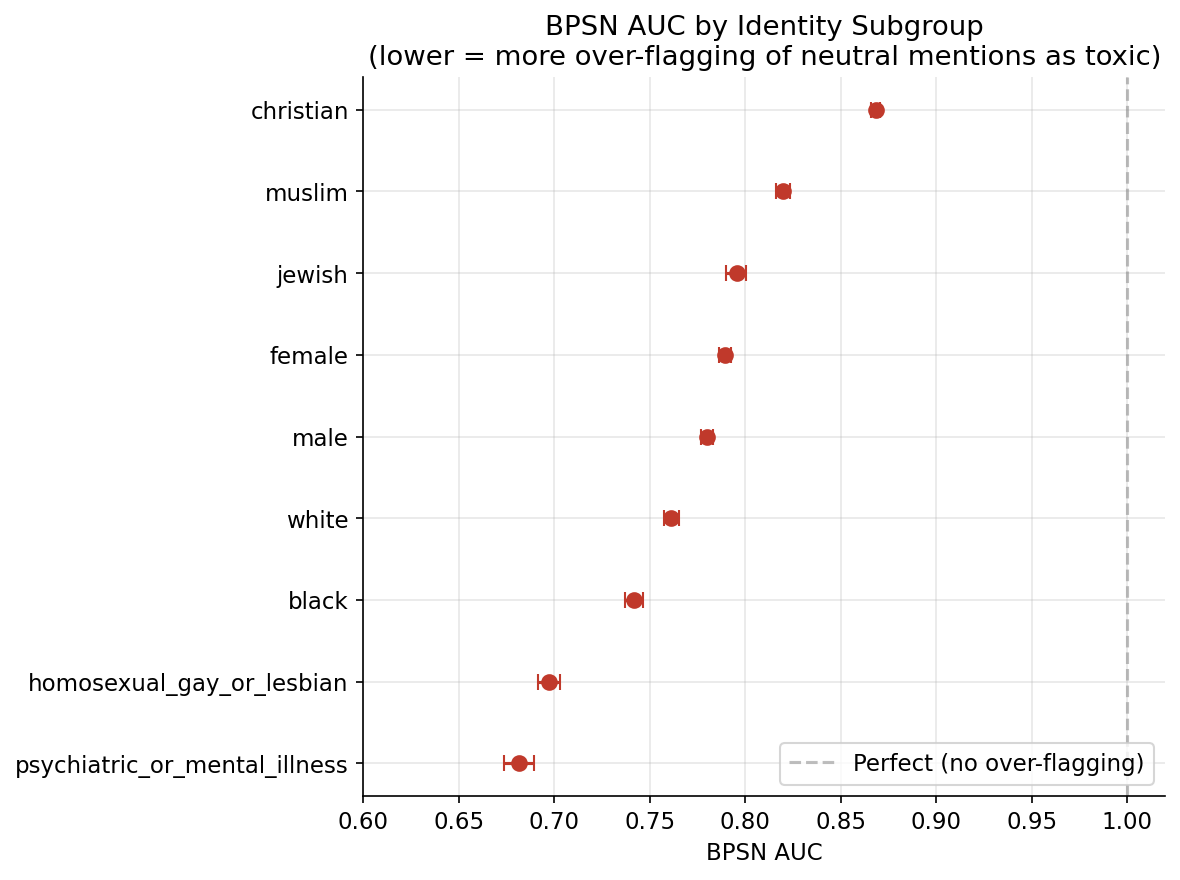

Saved: fig3_bpsn_auc_by_subgroup.png/.pdf

Figures saved to ./figures/ (PNG for viewing, PDF for LaTeX/paper inclusion).


In [74]:
# ============================================================
# 29. Paper figures -- ASR comparison + BPSN fairness plot (essential pair)
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import os

os.makedirs("./figures", exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

STRATEGY_COLORS = {
    "baseline": "#95a5a6",
    "shared_aug": "#e67e22",
    "per_label_3x": "#3498db",
    "oversampled": "#2ecc71",
}
STRATEGY_LABELS = {
    "baseline": "Baseline (no aug.)",
    "shared_aug": "Shared aug. (toxic-only)",
    "per_label_3x": "Per-label aug. (3x)",
    "oversampled": "Per-label aug. (volume-matched)",
}

# ------------------------------------------------------------
# FIGURE 1 -- ASR by label x augmentation strategy, one panel per attack
# Requires: four_way_df, columns:
#   attack, label, asr_baseline, asr_shared_aug, asr_per_label_3x, asr_per_label_oversampled
# ------------------------------------------------------------
if "four_way_df" in globals():
    attacks = ["char_swap", "leetspeak", "spaced_out"]
    strategies = ["asr_baseline", "asr_shared_aug", "asr_per_label_3x", "asr_per_label_oversampled"]
    strategy_keys = ["baseline", "shared_aug", "per_label_3x", "oversampled"]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
    for ax, attack in zip(axes, attacks):
        sub = four_way_df[four_way_df["attack"] == attack].set_index("label").reindex(LABEL_COLS)
        n_labels = len(LABEL_COLS)
        n_strats = len(strategies)
        bar_width = 0.8 / n_strats
        x = np.arange(n_labels)

        for j, (col, key) in enumerate(zip(strategies, strategy_keys)):
            offset = (j - n_strats / 2) * bar_width + bar_width / 2
            ax.bar(x + offset, sub[col].values, width=bar_width,
                   color=STRATEGY_COLORS[key], label=STRATEGY_LABELS[key])

        ax.set_xticks(x)
        ax.set_xticklabels(LABEL_COLS, rotation=40, ha="right")
        ax.set_title(attack.replace("_", " ").title())
        ax.set_ylim(0, 1.05)
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

    axes[0].set_ylabel("Attack Success Rate")
    handles, labels_ = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels_, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.08), frameon=False)
    fig.suptitle("Attack Success Rate by Label and Augmentation Strategy", y=1.15, fontsize=13)
    plt.tight_layout()
    plt.savefig("./figures/fig1_asr_by_label_strategy.png", bbox_inches="tight")
    plt.savefig("./figures/fig1_asr_by_label_strategy.pdf", bbox_inches="tight")
    plt.show()
    print("Saved: fig1_asr_by_label_strategy.png/.pdf")
else:
    print("four_way_df not found -- run cell 18e first, then re-run this cell.")


# ------------------------------------------------------------
# FIGURE 3 -- BPSN AUC per identity group with 95% CI (sorted, horizontal)
# Requires: bpsn_ci_df, columns: identity, bpsn_auc, ci_low, ci_high
# ------------------------------------------------------------
if "bpsn_ci_df" in globals():
    sorted_df = bpsn_ci_df.sort_values("bpsn_auc")
    fig, ax = plt.subplots(figsize=(8, 6))
    y_pos = np.arange(len(sorted_df))

    err_low = sorted_df["bpsn_auc"] - sorted_df["ci_low"]
    err_high = sorted_df["ci_high"] - sorted_df["bpsn_auc"]

    ax.errorbar(sorted_df["bpsn_auc"], y_pos, xerr=[err_low, err_high],
                fmt="o", color="#c0392b", ecolor="#c0392b", capsize=4, markersize=7)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(sorted_df["identity"])
    ax.axvline(1.0, color="grey", linestyle="--", alpha=0.5, label="Perfect (no over-flagging)")
    ax.set_xlabel("BPSN AUC")
    ax.set_title("BPSN AUC by Identity Subgroup\n(lower = more over-flagging of neutral mentions as toxic)")
    ax.set_xlim(0.6, 1.02)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig("./figures/fig3_bpsn_auc_by_subgroup.png", bbox_inches="tight")
    plt.savefig("./figures/fig3_bpsn_auc_by_subgroup.pdf", bbox_inches="tight")
    plt.show()
    print("Saved: fig3_bpsn_auc_by_subgroup.png/.pdf")
else:
    print("bpsn_ci_df not found -- run cell 5 (BPSN bootstrap) first, then re-run this cell.")

print("\nFigures saved to ./figures/ (PNG for viewing, PDF for LaTeX/paper inclusion).")

## 22. Gradio demo — live text input with model choice

In [76]:
# ============================================================
# UNIFIED GRADIO INTERFACE
# ============================================================
#
# Provides:
#   1. Standard toxicity classification
#      - Baseline TF-IDF
#      - Fine-tuned DistilBERT
#      - Adversarially augmented model
#
#   2. Contextual Abuse Detection (CAD)
#      - Upload JSON/CSV chat history
#      - Select target message
#      - Reconstruct previous conversation turns
#      - Compare context-aware vs standalone CAD prediction
#
# ============================================================

import os
import json
import gradio as gr
import pandas as pd
import numpy as np
import torch


# ============================================================
# 1. LOAD TUNED THRESHOLDS
# ============================================================

try:
    with open("tuned_thresholds.json", "r") as f:
        _tuned = json.load(f)
    THRESH_MAP = {label: threshold_f1[0] for label, threshold_f1 in _tuned.items()}
except Exception:
    THRESH_MAP = {label: 0.5 for label in LABEL_COLS}


# ============================================================
# 2. STANDARD TOXICITY CLASSIFIER
# ============================================================

def predict_toxicity(text, model_choice):

    cleaned = clean_text(text)

    try:
        # Fine-tuned DistilBERT
        if (model_choice == "Transformer (DistilBERT)" and RUN_BERT and "bert_model" in globals()):
            bert_model.eval()
            enc = tokenizer(light_clean_text(text), truncation=True, padding="max_length",
                            max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
            with torch.no_grad():
                logits = bert_model(**enc).logits
            probs = torch.sigmoid(logits).cpu().numpy()[0]

        # Adversarially augmented model
        elif (model_choice == "Adversarially-augmented" and RUN_ADV_MITIGATION
              and "aug_model" in globals() and "tfidf_aug" in globals()):
            vec = tfidf_aug.transform([cleaned])
            probs = aug_model.predict_proba(vec)[0]

        # Baseline TF-IDF model
        else:
            vec = tfidf.transform([cleaned])
            probs = baseline_model.predict_proba(vec)[0]

    except Exception as e:
        return (None, f"⚠️ Model error: {e}", "")

    label_probs = {label: float(prob) for label, prob in zip(LABEL_COLS, probs)}

    # Apply tuned thresholds
    flagged = [label for label, prob in label_probs.items() if prob >= THRESH_MAP.get(label, 0.5)]

    # Build probability/threshold visualization
    rows = []
    for label in LABEL_COLS:
        probability = label_probs[label]
        threshold = THRESH_MAP.get(label, 0.5)
        over_threshold = (probability >= threshold)
        bar_color = ("#e74c3c" if over_threshold else "#95a5a6")

        rows.append(
            f"""
            <div style="margin-bottom:10px;">

                <div style="
                    display:flex;
                    justify-content:space-between;
                    font-size:13px;
                ">

                    <span>
                        <b>{label}</b>
                        {" 🚩" if over_threshold else ""}
                    </span>

                    <span>
                        {probability:.3f}
                        (threshold {threshold:.2f})
                    </span>

                </div>

                <div style="
                    background:#eee;
                    border-radius:4px;
                    height:10px;
                    position:relative;
                ">

                    <div style="
                        background:{bar_color};
                        width:{probability * 100:.1f}%;
                        height:10px;
                        border-radius:4px;
                    "></div>

                    <div style="
                        position:absolute;
                        left:{threshold * 100:.1f}%;
                        top:-2px;
                        width:2px;
                        height:14px;
                        background:#2c3e50;
                    "></div>

                </div>

            </div>
            """
        )

    html = "<div>" + "".join(rows) + "</div>"

    if flagged:
        verdict = "🚩 **Flagged labels:** " + ", ".join(flagged)
    else:
        verdict = "✅ **No labels crossed their tuned threshold.**"

    return (label_probs, verdict, html)


# ============================================================
# 3. STANDARD GRADIO CALLBACK
# ============================================================

def gradio_predict(text, model_choice):

    if (text is None or not text.strip()):
        empty = {label: 0.0 for label in LABEL_COLS}
        return (empty, "Enter some text to classify.", "")

    label_probs, verdict, html = predict_toxicity(text, model_choice)

    if label_probs is None:
        empty = {label: 0.0 for label in LABEL_COLS}
        return (empty, verdict, "")

    return (label_probs, verdict, html)


# ============================================================
# 4. CAD CHAT FILE PARSER
# ============================================================

def parse_chat_upload(file_obj):

    if file_obj is None:
        raise ValueError("No chat file was uploaded.")

    path = file_obj.name
    extension = os.path.splitext(path)[1].lower()

    # JSON
    if extension == ".json":

        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        if not isinstance(data, list):
            raise ValueError("JSON must contain a list of messages.")

        if len(data) == 0:
            raise ValueError("The JSON chat history is empty.")

        # List of plain strings
        if isinstance(data[0], str):
            messages = data

        # List of dictionaries
        elif isinstance(data[0], dict):

            possible_keys = ["text", "message", "comment", "utterance", "content"]

            text_key = next(
                (key for key in data[0].keys() if key.lower() in possible_keys),
                None
            )

            if text_key is None:
                raise ValueError(
                    "Could not find a text field in the JSON. "
                    "Expected one of: " + ", ".join(possible_keys)
                )

            messages = [str(item.get(text_key, "")) for item in data]

        else:
            raise ValueError("Unsupported JSON message format.")

    # CSV
    elif extension == ".csv":

        df = pd.read_csv(path)

        possible_columns = ["text", "message", "comment", "utterance", "content"]

        text_col = next(
            (column for column in df.columns if column.lower() in possible_columns),
            None
        )

        if text_col is None:
            raise ValueError(
                "Could not find a text column in the CSV. "
                f"Available columns: {list(df.columns)}"
            )

        messages = df[text_col].fillna("").astype(str).tolist()

    else:
        raise ValueError("Please upload a .json or .csv chat history.")

    # Remove completely empty messages
    messages = [message.strip() for message in messages if str(message).strip()]

    if not messages:
        raise ValueError("No usable messages were found.")

    return messages


# ============================================================
# 5. CAD CONTEXT FORMAT
# ============================================================
#
# IMPORTANT:
#
# Your CAD training pipeline used:
#
#   Previous 1: ...
#   Previous 2: ...
#   Previous 3: ...
#   Current comment:
#   ...
#
# Therefore inference must use EXACTLY the same format.
#
# ============================================================

CAD_MAX_CONTEXT_TURNS = 3


def build_cad_context(previous_turns, current_text):

    previous_turns = [str(turn).strip() for turn in previous_turns if str(turn).strip()]
    current_text = str(current_text).strip()

    if not previous_turns:
        return ("Current comment:\n" + current_text)

    previous_text = "\n".join(
        f"Previous {i + 1}: {turn}" for i, turn in enumerate(previous_turns)
    )

    return (previous_text + "\n" + "Current comment:\n" + current_text)


# ============================================================
# 6. CAD PREDICTION
# ============================================================

def predict_cad_probability(text, use_context=True, previous_turns=None):

    if ("cad_model" not in globals() or "cad_tokenizer" not in globals()):
        raise RuntimeError(
            "CAD model/tokenizer is not loaded. "
            "Run the CAD training cells first."
        )

    if previous_turns is None:
        previous_turns = []

    if use_context:
        model_input = build_cad_context(previous_turns, text)
    else:
        model_input = ("Current comment:\n" + str(text).strip())

    cad_model.eval()

    enc = cad_tokenizer(model_input, truncation=True, padding="max_length",
                        max_length=CAD_MAX_LEN, return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        logits = cad_model(**enc).logits
        probability = torch.sigmoid(logits).squeeze().item()

    return float(np.clip(probability, 0.0, 1.0))


# ============================================================
# 7. CAD CHAT ANALYSIS
# ============================================================

def classify_chat_context(file_obj, target_idx, manual_target_text):

    try:

        # Determine target and context
        if file_obj is not None:

            messages = parse_chat_upload(file_obj)

            if (target_idx is None or target_idx == ""):
                target_idx = (len(messages) - 1)

            target_idx = int(target_idx)
            target_idx = max(0, min(target_idx, len(messages) - 1))

            current_text = messages[target_idx]

            start_idx = max(0, target_idx - CAD_MAX_CONTEXT_TURNS)
            previous_turns = messages[start_idx:target_idx]

        else:

            if (manual_target_text is None or not manual_target_text.strip()):
                return ("Upload a chat log or type a target comment.", "", "")

            current_text = manual_target_text.strip()
            previous_turns = []
            target_idx = None

        # Context-aware probability
        context_probability = predict_cad_probability(
            current_text, use_context=True, previous_turns=previous_turns
        )

        # Standalone probability
        standalone_probability = predict_cad_probability(
            current_text, use_context=False
        )

        delta = (context_probability - standalone_probability)

        # Interpret context effect
        if delta >= 0.15:
            story = (
                "⚠️ **Context substantially increases "
                "the predicted abuse probability.** "
                "The surrounding conversation provides "
                "signals that make the target comment "
                "appear more abusive."
            )
        elif delta <= -0.15:
            story = (
                "ℹ️ **Context substantially decreases "
                "the predicted abuse probability.** "
                "The surrounding conversation makes the "
                "target comment appear less abusive than "
                "when considered alone."
            )
        else:
            story = (
                "➖ **Context has little effect on the "
                "predicted abuse probability.**"
            )

        # Build context preview
        context_lines = []

        for i, message in enumerate(previous_turns):
            context_lines.append(f"[Previous {i + 1}] {message}")

        if not context_lines:
            context_lines.append("(No previous context used)")

        context_lines.append(f"[TARGET] {current_text}")

        context_preview = "\n".join(context_lines)

        # Verdict
        verdict = (
            "### CAD Result\n\n"
            f"**Context-aware abuse probability:** "
            f"{context_probability:.3f}\n\n"
            f"**Standalone probability:** "
            f"{standalone_probability:.3f}\n\n"
            f"**Δ (context − standalone):** "
            f"{delta:+.3f}\n\n"
            f"{story}"
        )

        if target_idx is None:
            meta = (
                "Target: manually entered comment  \n"
                "Previous turns: none"
            )
        else:
            meta = (
                f"Target message index: {target_idx}  \n"
                f"Previous turns supplied: "
                f"{len(previous_turns)}"
            )

        return (verdict, context_preview, meta)

    except Exception as e:
        return (f"⚠️ **CAD analysis failed:** `{e}`", "", "")


# ============================================================
# 8. MODEL OPTIONS
# ============================================================

model_options = ["Baseline"]

if (RUN_BERT and "bert_model" in globals()):
    model_options.append("Transformer (DistilBERT)")

if (RUN_ADV_MITIGATION and "aug_model" in globals()):
    model_options.append("Adversarially-augmented")


# ============================================================
# UI EFFECTS (CSS / theme / JS only)
# ============================================================

UI_CSS = """
@import url('https://fonts.googleapis.com/css2?family=Poppins:wght@400;600;800&display=swap');
:root{--acc1:#8b5cf6;--acc2:#ec4899;--acc3:#22d3ee;--glass:rgba(255,255,255,.06);--line:rgba(255,255,255,.13)}
body,.gradio-container{font-family:'Poppins',system-ui,sans-serif!important;color:#e5e7eb!important}
body{background:linear-gradient(120deg,#07091f,#14103a,#2a0f3d,#06203a);background-size:400% 400%;animation:bgshift 22s ease infinite}
.gradio-container{background:transparent!important;max-width:1200px!important}

/* glowing orbs, vignette and slow scan-line */
body::before,body::after{content:"";position:fixed;z-index:0;width:48vw;height:48vw;border-radius:50%;filter:blur(95px);opacity:.36;pointer-events:none}
body::before{background:radial-gradient(circle,#22d3ee,transparent 65%);top:-12vw;left:-10vw;animation:float 17s ease-in-out infinite}
body::after{background:radial-gradient(circle,#ec4899,transparent 65%);bottom:-14vw;right:-10vw;animation:float 21s ease-in-out infinite reverse}
.gradio-container::before{content:"";position:fixed;inset:0;z-index:0;pointer-events:none;background:radial-gradient(circle at 50% 40%,transparent 55%,rgba(0,0,0,.45))}
.gradio-container::after{content:"";position:fixed;left:0;right:0;top:-20%;height:18%;z-index:0;pointer-events:none;
  background:linear-gradient(transparent,rgba(139,92,246,.07),transparent);animation:scan 9s linear infinite}
.gradio-container>*{position:relative;z-index:1}

@keyframes bgshift{0%{background-position:0 50%}50%{background-position:100% 50%}100%{background-position:0 50%}}
@keyframes float{0%,100%{transform:translate(0,0) scale(1)}50%{transform:translate(6vw,4vw) scale(1.15)}}
@keyframes rise{from{opacity:0;transform:translateY(22px) scale(.98)}to{opacity:1;transform:none}}
@keyframes shine{to{background-position:200% center}}
@keyframes glow{0%,100%{box-shadow:0 0 0 0 rgba(236,72,153,.5)}50%{box-shadow:0 0 24px 5px rgba(139,92,246,.5)}}
@keyframes sweep{from{transform:translateX(-130%)}to{transform:translateX(130%)}}
@keyframes grow{from{width:0}}
@keyframes scan{to{top:120%}}
@keyframes dash{to{background-position:200% 0}}
@keyframes alarm{0%,100%{box-shadow:0 0 0 0 rgba(231,76,60,.6)}50%{box-shadow:0 0 12px 3px rgba(231,76,60,.7)}}

/* glass panels */
.block,.form,.gr-group,.gradio-container .panel{background:var(--glass)!important;border:1px solid var(--line)!important;border-radius:20px!important;
  backdrop-filter:blur(16px);-webkit-backdrop-filter:blur(16px);transition:transform .3s,box-shadow .3s,border-color .3s;animation:rise .7s both}
.block:hover{border-color:rgba(139,92,246,.6)!important;box-shadow:0 10px 34px rgba(139,92,246,.22)}
.gradio-container label span,.gradio-container .prose,.gradio-container .prose *{color:#e5e7eb!important}

/* hero (the first Markdown block) */
.hero{position:relative;overflow:hidden;padding:26px 28px!important;border-radius:26px!important;
  background:linear-gradient(135deg,rgba(139,92,246,.26),rgba(236,72,153,.16))!important}
.hero::after{content:"";position:absolute;inset:0;background:linear-gradient(115deg,transparent 42%,rgba(255,255,255,.1) 50%,transparent 58%);animation:sweep 7s ease-in-out infinite;pointer-events:none}
.hero h1{font-size:2.5rem;font-weight:800;background:linear-gradient(90deg,#fff,#a5f3fc,#c4b5fd,#f9a8d4,#fff);background-size:200% auto;
  -webkit-background-clip:text;background-clip:text;-webkit-text-fill-color:transparent;color:transparent!important;animation:shine 6s linear infinite}
.hero h3{color:#67e8f9!important;letter-spacing:.12em;text-transform:uppercase;font-size:.95rem}
.hero strong{color:#f9a8d4!important}
.prose h1,.prose h2,.prose h3{background:linear-gradient(90deg,#fff,#c4b5fd,#f9a8d4);-webkit-background-clip:text;background-clip:text;-webkit-text-fill-color:transparent;color:transparent!important}
.prose ul li::marker{color:var(--acc2)}
.prose code,.prose pre{background:rgba(0,0,0,.35)!important;border:1px solid var(--line)!important;border-radius:12px!important;color:#a5f3fc!important}
.prose pre{box-shadow:inset 0 0 24px rgba(34,211,238,.08)}

/* inputs */
input,textarea,select{background:rgba(255,255,255,.07)!important;color:#fff!important;border:1px solid var(--line)!important;border-radius:12px!important;transition:.25s}
input:focus,textarea:focus{border-color:var(--acc1)!important;box-shadow:0 0 0 3px rgba(139,92,246,.4),0 0 20px rgba(139,92,246,.35)!important}
textarea::placeholder,input::placeholder{color:#94a3b8!important}
input[type=radio],input[type=checkbox],input[type=range]{accent-color:#ec4899}
label:has(input:checked){border-color:var(--acc2)!important;box-shadow:0 0 14px rgba(236,72,153,.45)}
.gradio-container label{transition:.25s}
.gradio-container label:hover{transform:translateY(-1px)}

/* upload drop-zone: animated dashed border */
[data-testid="file-upload"],.file-upload,.upload-container,button.center{border:2px dashed transparent!important;border-radius:18px!important;
  background:linear-gradient(#14103a,#14103a) padding-box,linear-gradient(90deg,var(--acc1),var(--acc2),var(--acc3),var(--acc1)) border-box!important;
  background-size:100% 100%,200% 100%!important;animation:dash 5s linear infinite;transition:.3s}
[data-testid="file-upload"]:hover,.file-upload:hover,.upload-container:hover{box-shadow:0 0 28px rgba(34,211,238,.35)}

/* buttons */
button{position:relative;overflow:hidden}
button.primary,.primary{background:linear-gradient(90deg,var(--acc1),var(--acc2),var(--acc3))!important;background-size:200% auto!important;border:none!important;color:#fff!important;
  font-weight:700!important;letter-spacing:.04em;border-radius:14px!important;animation:shine 4s linear infinite,glow 3s ease-in-out infinite;transition:transform .2s}
button.primary:hover{transform:translateY(-3px) scale(1.04)}
button.primary:active{transform:scale(.97)}
button.primary::after{content:"";position:absolute;inset:0;background:linear-gradient(115deg,transparent 40%,rgba(255,255,255,.35) 50%,transparent 60%);transform:translateX(-130%)}
button.primary:hover::after{animation:sweep .8s}

/* tabs */
button[role="tab"]{color:#cbd5e1!important;font-weight:600!important;transition:.25s}
button[role="tab"]:hover{color:#fff!important;transform:translateY(-2px)}
button[role="tab"][aria-selected="true"],button[role="tab"].selected{color:#fff!important;border-bottom:3px solid var(--acc2)!important;text-shadow:0 0 14px rgba(236,72,153,.85)}

/* gr.Label probability bars */
.confidence-set .bar,.bar-container .bar,[class*="confidence"] [class*="bar"]{background:linear-gradient(90deg,var(--acc1),var(--acc2),var(--acc3))!important;border-radius:99px!important;animation:grow 1s ease-out both}
.confidence-set:hover,[class*="confidence"]:hover{filter:brightness(1.15)}

/* per-label threshold view (inline-styled HTML from predict_toxicity) */
div[style*="background:#eee"]{background:rgba(255,255,255,.12)!important;box-shadow:inset 0 1px 3px rgba(0,0,0,.4)}
div[style*="background:#e74c3c"]{background:linear-gradient(90deg,#f97316,#ef4444,#ec4899)!important;animation:grow 1.1s ease-out both,alarm 1.8s ease-in-out infinite}
div[style*="background:#95a5a6"]{background:linear-gradient(90deg,#64748b,#22d3ee)!important;animation:grow 1.1s ease-out both}
div[style*="background:#2c3e50"]{background:#fff!important;box-shadow:0 0 8px #fff}
div[style*="justify-content:space-between"]{color:#e5e7eb!important}

/* tables / examples */
table{color:#e5e7eb!important}
table tbody tr{transition:background .2s,transform .2s}
table tbody tr:hover{background:rgba(139,92,246,.25)!important;transform:scale(1.005)}
table thead th{background:linear-gradient(90deg,rgba(139,92,246,.35),rgba(236,72,153,.25))!important;color:#fff!important}

/* misc */
::-webkit-scrollbar{width:9px;height:9px}::-webkit-scrollbar-thumb{background:linear-gradient(var(--acc1),var(--acc2));border-radius:9px}
::selection{background:rgba(236,72,153,.5)}
.generating,.pending{border-color:var(--acc3)!important;box-shadow:0 0 22px rgba(34,211,238,.45)!important}
@media (max-width:700px){.hero h1{font-size:1.7rem}}
@media (prefers-reduced-motion:reduce){*{animation:none!important;transition:none!important}}
"""

UI_THEME = gr.themes.Base(primary_hue="violet", secondary_hue="pink", neutral_hue="slate",
                          font=[gr.themes.GoogleFont("Poppins"), "system-ui", "sans-serif"])
UI_JS = "() => { document.body.classList.add('dark'); }"      # force dark mode



# ============================================================
# 9. UNIFIED GRADIO APPLICATION
# ============================================================

with gr.Blocks(
    theme=UI_THEME,
    css=UI_CSS,
    js=UI_JS,
    title="Toxicity & Contextual Abuse Research System"
) as demo:

    gr.Markdown(
        """
        # Toxicity & Contextual Abuse Detection
        ### Research Build

        This interface contains two complementary detection systems:

        **Standard Toxicity Detection**
        - toxic
        - severe_toxic
        - obscene
        - threat
        - insult
        - identity_hate

        **Contextual Abuse Detection (CAD)**
        - analyzes a target comment together with
          previous conversation turns
        - compares the contextual prediction against
          the standalone prediction
        """,
        elem_classes="hero"
    )

    # ========================================================
    # TAB 1 — STANDARD TOXICITY
    # ========================================================

    with gr.Tab("Standard Toxicity Detection"):

        gr.Markdown(
            """
            Classify an individual comment using the
            selected toxicity model.
            """
        )

        with gr.Row():

            with gr.Column(scale=2):

                text_input = gr.Textbox(
                    lines=4,
                    placeholder="Type a comment or tweet here...",
                    label="Comment text"
                )

                model_choice = gr.Radio(
                    model_options,
                    value="Baseline",
                    label="Model"
                )

                submit_btn = gr.Button("Classify", variant="primary")

            with gr.Column(scale=1):

                output_label = gr.Label(
                    num_top_classes=6,
                    label="Raw probabilities"
                )

        verdict_box = gr.Markdown()

        threshold_html = gr.HTML(label="Per-label threshold view")

        submit_btn.click(
            gradio_predict,
            [text_input, model_choice],
            [output_label, verdict_box, threshold_html]
        )

        text_input.submit(
            gradio_predict,
            [text_input, model_choice],
            [output_label, verdict_box, threshold_html]
        )

        gr.Markdown(
            """
            ### Examples
            """
        )

        gr.Examples(
            examples=[
                ["Your edit to this article is completely wrong and unhelpful.", "Baseline"],
                ["ur so dumb lmaooo get off this site fr", "Baseline"],
                ["Thanks for the clarification, that makes sense now.", "Baseline"],
                ["I am a proud gay man and I love this community.", "Baseline"],
                ["y o u  a r e  a n  i d i o t", "Baseline"]
            ],
            inputs=[text_input, model_choice]
        )

    # ========================================================
    # TAB 2 — CONTEXTUAL ABUSE
    # ========================================================

    with gr.Tab("Contextual Abuse Detection"):

        gr.Markdown(
            f"""
            ### Conversation-aware CAD

            Upload a chat history and select the message
            you want to analyze.

            The model receives up to **{CAD_MAX_CONTEXT_TURNS}
            previous conversation turns** plus the target
            comment.

            The interface also calculates a standalone
            prediction using only the target comment.

            This allows you to observe how conversational
            context changes the model's prediction.
            """
        )

        with gr.Row():

            file_input = gr.File(
                label="Chat history (.json or .csv)",
                file_types=[".json", ".csv"]
            )

            target_idx_input = gr.Number(
                label=(
                    "Target message index "
                    "(0-based; blank = last message)"
                ),
                precision=0
            )

        manual_input = gr.Textbox(
            label=(
                "Or type a single target comment "
                "(no context)"
            ),
            lines=3
        )

        cad_run_btn = gr.Button("Analyze Context", variant="primary")

        cad_verdict_out = gr.Markdown(label="CAD result")

        cad_context_out = gr.Textbox(
            label="Context sent to CAD model",
            lines=10
        )

        cad_meta_out = gr.Markdown()

        cad_run_btn.click(
            classify_chat_context,
            [file_input, target_idx_input, manual_input],
            [cad_verdict_out, cad_context_out, cad_meta_out]
        )

        gr.Markdown(
            """
            ### Expected chat file formats

            **JSON — list of strings**

            ```json
            [
              "Hey, how are you?",
              "I'm good, thanks.",
              "You're such an idiot."
            ]
            ```

            **CSV**

            ```text
            text
            Hey, how are you?
            I'm good, thanks.
            You're such an idiot.
            ```

            The target message is selected using its
            **0-based index**.
            """
        )


# ============================================================
# 10. LAUNCH
# ============================================================

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://91b2e92dc1d077708a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
